In [28]:
import pandas as pd
import numpy as np
from dotenv import load_dotenv
import os
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import ccf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.stattools import acf, pacf
from scipy.stats import norm
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

load_dotenv()

True

Removendo warnings

In [29]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import numpy as np
import pandas as pd

# Opção 1: ignorar todos os warnings (global)
warnings.filterwarnings("ignore")

# Opção 2: ignorar apenas categorias específicas (recomendado)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
#warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Pandas: desativar aviso de SettingWithCopy (use com cuidado)
pd.options.mode.chained_assignment = None

# NumPy: ignorar avisos numéricos (overflow/underflow etc.)
np.seterr(all="ignore")

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

# Importando os dados

Dados previamente tratados.
Foram importados 48 índices

In [30]:
# Carregar variáveis de ambiente
load_dotenv()

path_dados_tratados = os.getenv('PATH_DADOS_TRATADOS')

dados_indicadores = pd.read_csv(path_dados_tratados + "dados_indicadores_tratados.csv")
dados_indices = pd.read_csv(path_dados_tratados + "dados_indices.csv", sep=';')
dados_indices.drop(columns=['Unnamed: 0'], inplace=True)
dados_indices.drop(columns=['incc'], inplace=True)
preco_acoes = pd.read_csv(path_dados_tratados + 'preco_acoes.csv')
preco_acoes = preco_acoes.iloc[:-1, :]

In [31]:
dados_indices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 47 columns):
 #   Column                                                                                                                      Non-Null Count  Dtype  
---  ------                                                                                                                      --------------  -----  
 0   data                                                                                                                        59 non-null     object 
 1   ibov                                                                                                                        59 non-null     float64
 2   iee                                                                                                                         59 non-null     float64
 3   selic                                                                                                                       59 

Renomear colunas

In [32]:
rename_map = {
    "IPAOG-DI Ipa - todos os itens - Nro. Índice(1477007)": "IPAOG-DI",
    "INCC-Brasil-DI-Todos os itens(1464783)": "INCC-Brasil-DI",
    "Indicador de Incerteza da Economia Brasil (IIE-Br)(1428452)": "IIE-Br",
    "Indicador de Incerteza da Economia Brasil - Componente Mídia (Mídia - IIE-Br)(1463188)": "Mídia - IIE-Br",
    "Indicador de Incerteza da Economia Brasil - Componente Expactativas (Expec IIE-Br)(1463189)": "Expec IIE-Br",
    "Indicador Antecedente de Emprego (IA Emp) com ajuste sazonal(1416205)": "IA Emp",
    "Indicador Antecedente de Emprego (IA Emp) com ajuste sazonal(1416205) (Variação Percentual em Relação ao Período Anterior)": "Var. IA Emp",
    "PIB a preços de 1995(1428699)": "PIB 1995",
    "PIB a preços correntes(1428698)": "PIB Corrente",
    "Índice de volume mensal  - PIB a preços de mercado (1428676)": "Vol. PIB Mensal",
    "Índice de volume mensal pela ótica da produção - Valor adicionado a preços básicos(1428677)": "Vol. VA Produção",
    "Índice de volume mensal pela ótica da produção - Valor adicionado a preços básicos - Agropecuária(1428678)": "Vol. VA Agro",
    "Índice de volume mensal pela ótica da produção - Valor adicionado a preços básicos - Indústria(1428679)": "Vol. VA Indústria",
    "Índice de volume mensal pela ótica da produção - Valor adicionado a preços básicos - Serviços(1428680)": "Vol. VA Serviços",
    "Índice de volume mensal pela ótica da produção - Impostos (1428681)": "Vol. Impostos",
    "Índice de volume mensal com ajuste sazonal - PIB a preços de mercado (1428682)": "Vol. PIB Sazonal",
    "Índice de volume mensal pela ótica da produção com ajuste sazonal -Valor adicionado (1428683)": "Vol. VA Sazonal",
    "Índice de volume mensal pela ótica da produção com ajuste sazonal - Valor adicionado - Agropecuária(1428684)": "Vol. VA Agro Sazonal",
    "Índice de volume mensal pela ótica da produção com ajuste sazonal - Valor adicionado - Indústria(1428685)": "Vol. VA Ind. Sazonal",
    "Índice de volume mensal pela ótica da produção com ajuste sazonal - Valor adicionado - Serviços(1428686)": "Vol. VA Serv. Sazonal",
    "Índice de volume trimestral com ajuste sazonal - PIB(1428700)": "Vol. PIB Trim. Saz.",
    "Índice de volume trimestral com ajuste sazonal - Valor Adicionado(1428701)": "Vol. VA Trim. Saz.",
    "Índice de volume trimestral com ajuste sazonal - Valor Adicionado - Agropecuária(1428702)": "Vol. VA Agro Trim. Saz.",
    "Índice de volume trimestral com ajuste sazonal - Valor Adicionado - Indústria(1428703)": "Vol. VA Ind. Trim. Saz.",
    "Índice de volume trimestral com ajuste sazonal - Valor Adicionado - Serviços(1428704)": "Vol. VA Serv. Trim. Saz.",
    "Índice da Taxa de Câmbio Real - (Real / Dólar (EUA))(1003592)": "Câmbio Real/Dólar",
    "Índice da Taxa de Câmbio Real - (Real / Iene (Japão))(1003593)": "Câmbio Real/Iene",
    "Índice da Taxa de Câmbio Real - (Real / Peso (Argentina))(1003594)": "Câmbio Real/Peso",
    "Índice da Taxa de Câmbio Real - (Real / Euro (Zona do Euro))(1003595)": "Câmbio Real/Euro",
    "Índice da Taxa de Câmbio Real - (Real / Libra (Reino Unido))(1003596)": "Câmbio Real/Libra",
    "Índice da Taxa de Câmbio Efetiva Real - (Real / Cesta de Moedas)(1003597)": "Câmbio Efetiva Real",
    "Juros EUA": "Juros EUA",
    "Tbonds": "T-bonds",
    "Cotacao dolar": "Cotação Dólar",
    "CDI": "CDI",
    "TJLP": "TJLP",
    "Energia res": "Energia Res.",
    "Energia ind": "Energia Ind.",
    "Energia comer": "Energia Com.",
    "Divida/PIB": "Dívida/PIB",
}

if 'dados_indices' in globals():
    dados_indices.rename(columns=rename_map, inplace=True)

# Opcional: verificar quais colunas foram renomeadas em cada DF
for name, df in [('dados_indicadores', globals().get('dados_indicadores')),
                 ('dados_indices', globals().get('dados_indices'))]:
    if df is not None:
        renomeadas = [v for k, v in rename_map.items() if k in df.columns]
        print(f"{name}: {len(renomeadas)} colunas renomeadas.")
# ...existing code...

dados_indicadores: 0 colunas renomeadas.
dados_indices: 3 colunas renomeadas.


In [33]:
dados_indices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   data                      59 non-null     object 
 1   ibov                      59 non-null     float64
 2   iee                       59 non-null     float64
 3   selic                     59 non-null     float64
 4   vix                       59 non-null     float64
 5   igpm                      59 non-null     float64
 6   ipca                      59 non-null     float64
 7   IPAOG-DI                  59 non-null     float64
 8   INCC-Brasil-DI            59 non-null     float64
 9   IIE-Br                    59 non-null     float64
 10  Mídia - IIE-Br            59 non-null     float64
 11  Expec IIE-Br              59 non-null     float64
 12  IA Emp                    59 non-null     float64
 13  Var. IA Emp               59 non-null     float64
 14  PIB 1995    

Como o foco deste estudo são as companhias de transmissão de energia elétrica, as seguintes empresas serão consideradas:
* ELET6 - CD_CVM = 2437
* ISAE4 - CD_CVM = 18376
* TAEE4 - CD_CVM = 20257
* ALUP4 - CD_CVM = 21490

In [45]:
# Filtrar dataframe para possuir apenas os códigos 2437, 18376, 20257, 21490
dados_indicadores_transm = dados_indicadores[dados_indicadores['CD_CVM'].isin([2437, 18376, 20257, 21490])]
dados_indicadores_transm.query("CD_CVM == 21490").head()

,CD_CVM,DENOM_CIA,DT_FIM_EXERC,3.01,3.02,3.03,3.04,3.05,3.06,3.07,3.08,3.09,3.11
15322,21490,ALUPAR INVESTIMENTO S/A,2010-03-31,282083000.0,-109982000.0,172101000.0,-14640000.0,157461000.0,-29583000.0,127878000.0,-20418000.0,107460000.0,107460000.0
15323,21490,ALUPAR INVESTIMENTO S/A,2010-09-30,268152000.0,-91704000.0,176448000.0,-5616000.0,170832000.0,-27612000.0,143220000.0,-22458000.0,120762000.0,120762000.0
15324,21490,ALUPAR INVESTIMENTO S/A,2010-12-31,385496000.0,-42203000.0,343293000.0,-17188000.0,326105000.0,-76033000.0,250072000.0,-56868000.0,193204000.0,193204000.0
15325,21490,ALUPAR INVESTIMENTO S/A,2011-03-31,293389000.0,-94234000.0,199155000.0,-11628000.0,187527000.0,-34444000.0,153083000.0,-19058000.0,134025000.0,134025000.0
15326,21490,ALUPAR INVESTIMENTO S/A,2011-09-30,322241000.0,-104842000.0,217399000.0,-22989000.0,194410000.0,-54647000.0,139763000.0,-24607000.0,115156000.0,115156000.0


Interpolando valores ausentes

In [46]:
novas_linhas = pd.DataFrame({
    'CD_CVM': [21490, 21490],
    'DENOM_CIA' : ['ALUPAR INVESTIMENTO S/A', 'ALUPAR INVESTIMENTO S/A'],
    'DT_FIM_EXERC': ['2010-06-30', '2011-06-30'],
    '3.01': [np.nan, np.nan],
    '3.02': [np.nan, np.nan],
    '3.03': [np.nan, np.nan],
    '3.04': [np.nan, np.nan],
    '3.05': [np.nan, np.nan],
    '3.06': [np.nan, np.nan],
    '3.07': [np.nan, np.nan],
    '3.08': [np.nan, np.nan],
    '3.09': [np.nan, np.nan],
    '3.11': [np.nan, np.nan]
})

In [36]:
dados_indicadores_transm = pd.concat([dados_indicadores_transm, novas_linhas], ignore_index=True)

In [47]:
#interpolar os valores nulos
dados_indicadores_transm = dados_indicadores_transm.sort_values(by=['CD_CVM', 'DT_FIM_EXERC'])
dados_indicadores_transm = dados_indicadores_transm.interpolate(method='linear', limit_direction='both')

In [50]:
dados_indicadores_transm.query("DT_FIM_EXERC > '2025-01-01'").head()

,CD_CVM,DENOM_CIA,DT_FIM_EXERC,3.01,3.02,3.03,3.04,3.05,3.06,3.07,3.08,3.09,3.11
614,2437,CENTRAIS ELET BRAS S.A. - ELETROBRAS,2025-03-31,1.041418e+10,-5.607757e+09,4.806422e+09,-1.601123e+09,3.205299e+09,-3.493976e+09,-2.886770e+08,-6.493700e+07,-3.536140e+08,-3.536140e+08
615,2437,CENTRAIS ELET BRAS S.A. - ELETROBRAS,2025-06-30,1.019896e+10,-5.335454e+09,4.863501e+09,-4.736167e+09,1.273340e+08,-2.554807e+09,-2.427473e+09,1.102368e+09,-1.325105e+09,-1.325105e+09
616,2437,CENTRAIS ELET BRAS S.A. - ELETROBRAS,2025-09-30,1.000250e+10,-5.920366e+09,4.082137e+09,-6.732758e+09,-2.650621e+09,-2.571309e+09,-5.221930e+09,-2.261870e+08,-5.448117e+09,-5.448117e+09
617,2437,CENTRAIS ELET BRAS S.A. - ELETROBRAS,2025-12-31,1.066596e+10,-6.700829e+09,3.965130e+09,-7.005600e+08,3.264570e+09,-2.306438e+09,9.581320e+08,1.272836e+10,1.368650e+10,1.368650e+10
9220,18376,ISA ENERGIA BRASIL,2025-03-31,2.412040e+09,-1.246375e+09,1.165665e+09,1.001760e+08,1.265841e+09,-3.515750e+08,9.142660e+08,-1.895610e+08,7.247050e+08,7.247050e+08


Organiza indicadores

In [51]:
dict_indicadores = {}
for cd_cvm in dados_indicadores_transm['CD_CVM'].unique():
    df_temp = dados_indicadores_transm.copy()
    df_temp = df_temp[df_temp['CD_CVM'] == cd_cvm].copy()
    
    df_temp.drop(columns=['CD_CVM','DENOM_CIA'], inplace=True)
    df_temp.set_index('DT_FIM_EXERC', inplace=True)
    dict_indicadores[cd_cvm] = df_temp



Tornando variáveis exógenas estacionárias

In [39]:
def tornar_estacionaria(serie, max_diff=5, verbose=False):
    """
    Aplica diferenciações sucessivas até a série temporal ficar estacionária (ADF p < 0.05).
    Retorna a série estacionária e o número de diferenciações aplicadas.
    """
    serie_estac = serie.copy()
    diff_count = 0
    for _ in range(max_diff + 1):
        adf_result = adfuller(serie_estac.dropna())
        p_value = adf_result[1]
        if verbose:
            print(f"Differencing: {diff_count}, p-value: {p_value:.4f}")
        if p_value < 0.05:
            return serie_estac, diff_count
        serie_estac = serie_estac.diff().dropna()
        diff_count += 1
    if verbose:
        print("Atenção: não ficou estacionária após", max_diff, "diferenciações.")
    return serie_estac, diff_count

In [40]:
indices_estac = dados_indices.copy()
for column in dados_indices.columns:
    if column != 'data':
        indices_estac[column], diffs = tornar_estacionaria(dados_indices[column], verbose=False)
        print(f"Série '{column}' tornou-se estacionária após {diffs} diferenciações.")
indices_estac.set_index(dados_indices['data'], inplace=True)
indices_estac = indices_estac.iloc[1:, :]

Série 'ibov' tornou-se estacionária após 1 diferenciações.
Série 'iee' tornou-se estacionária após 1 diferenciações.
Série 'selic' tornou-se estacionária após 1 diferenciações.
Série 'vix' tornou-se estacionária após 0 diferenciações.
Série 'igpm' tornou-se estacionária após 0 diferenciações.
Série 'ipca' tornou-se estacionária após 0 diferenciações.
Série 'IPAOG-DI' tornou-se estacionária após 1 diferenciações.
Série 'INCC-Brasil-DI' tornou-se estacionária após 2 diferenciações.
Série 'IIE-Br' tornou-se estacionária após 1 diferenciações.
Série 'Mídia - IIE-Br' tornou-se estacionária após 0 diferenciações.
Série 'Expec IIE-Br' tornou-se estacionária após 0 diferenciações.
Série 'IA Emp' tornou-se estacionária após 0 diferenciações.
Série 'Var. IA Emp' tornou-se estacionária após 0 diferenciações.
Série 'PIB 1995' tornou-se estacionária após 1 diferenciações.
Série 'PIB Corrente' tornou-se estacionária após 2 diferenciações.
Série 'Vol. PIB Mensal' tornou-se estacionária após 1 diferen

In [41]:
indices_estac['INCC-Brasil-DI']

data
2010-06-30          NaN
2010-09-30    -1.929333
2010-12-31    -4.689667
2011-03-31     2.121667
2011-06-30    10.380000
2011-09-30    -7.777000
2011-12-31    -4.275333
2012-03-31     3.422333
2012-06-30     5.689333
2012-09-30    -3.065333
2012-12-31    -6.561667
2013-03-31     3.774333
2013-06-30     9.361000
2013-09-30    -4.043667
2013-12-31    -7.667667
2014-03-31     2.582000
2014-06-30     8.212333
2014-09-30    -4.352333
2014-12-31    -7.857667
2015-03-31     5.531667
2015-06-30     4.434333
2015-09-30     2.335000
2015-12-31    -9.871000
2016-03-31     1.270667
2016-06-30     4.754667
2016-09-30     1.942000
2016-12-31    -8.965333
2017-03-31     2.962000
2017-06-30    -0.948667
2017-09-30     2.625000
2017-12-31    -4.826333
2018-03-31    -0.489000
2018-06-30     2.520667
2018-09-30     4.047667
2018-12-31    -6.003667
2019-03-31     0.807333
2019-06-30     1.149000
2019-09-30     5.262333
2019-12-31    -6.678333
2020-03-31     0.868000
2020-06-30    -0.603333
2020-09-30 

0     39.773333
1     39.110000
2     38.656667
3     37.880000
4     37.530000
5     37.250000
6     36.013333
7     34.960000
8     34.803333
9     33.016667
10    32.576667
11    32.236667
12    32.386667
13    31.613333
14    30.963333
15    30.900000
16    30.383333
17    31.120000
18    31.936667
19    32.330000
20    32.130000
21    32.656667
22    32.463333
23    34.200000
24    36.650000
25    39.770000
26    42.790000
27    44.670000
28    47.083333
29    47.976667
30    50.183333
31    50.923333
32    51.613333
33    50.866667
34    50.983333
35    52.463333
36    53.083333
37    53.370000
38    53.740000
39    54.200000
40    52.120000
41    53.846667
42    58.696667
43    60.366667
44    59.246667
45    57.890000
46    57.040000
47    55.100000
48    55.643333
49    56.446667
50    55.886667
51    55.970000
52    55.633333
53    56.763333
54    58.630000
55    59.453333
56    60.193333
57    61.130000
58    61.383333
Name: Dívida/PIB, dtype: float64

In [27]:
indicadores_estac = {}
for cd_cvm, df in dict_indicadores.items():
    indicadores_estac[cd_cvm] = pd.DataFrame()
    for column in df.columns:
        indicadores_estac[cd_cvm][column], diffs = tornar_estacionaria(df[column], verbose=True)
        print(f"CD_CVM {cd_cvm} - Série '{column}' tornou-se estacionária após {diffs} diferenciações.")
    print(len(indicadores_estac[cd_cvm]))

    # Devido ao processo de diferenciação algumas séries podem ter perdido uma ou mais linhas no início
    if len(indicadores_estac[cd_cvm]) == 58:
        indicadores_estac[cd_cvm].set_index(df.index[1:], inplace=True)
    else:
        indicadores_estac[cd_cvm] = indicadores_estac[cd_cvm].iloc[1:, :]
        indicadores_estac[cd_cvm].set_index(df.index[1:], inplace=True)

Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.01' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0009
CD_CVM 2437 - Série '3.02' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.03' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.04' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.05' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.3000
Differencing: 1, p-value: 0.0000
CD_CVM 2437 - Série '3.06' tornou-se estacionária após 1 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.07' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.08' tornou-se estacionária após 0 diferenciações.
Differencing: 0, p-value: 0.0000
CD_CVM 2437 - Série '3.09' tornou-se estacionária após 0 diferenciações.
Differencing:

ValueError: Length mismatch: Expected 62 rows, received array of length 63

Verificar sazonalidade

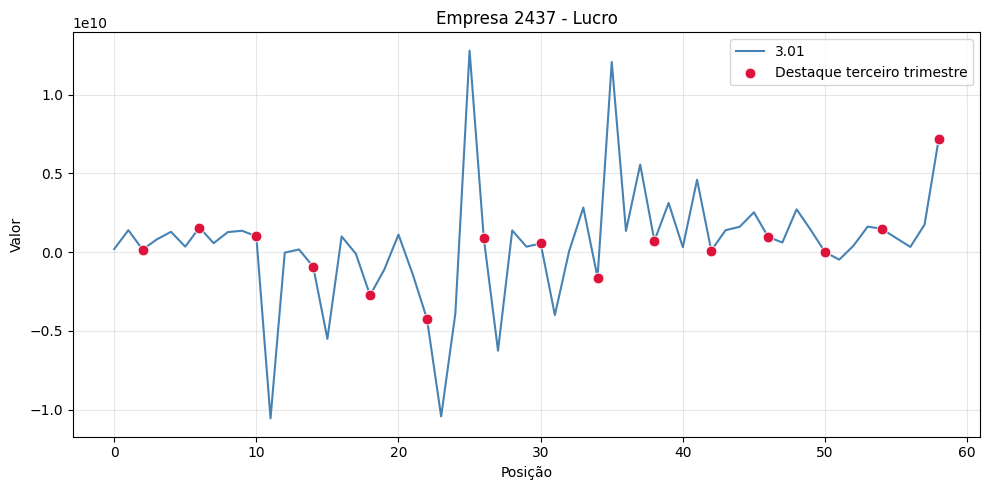

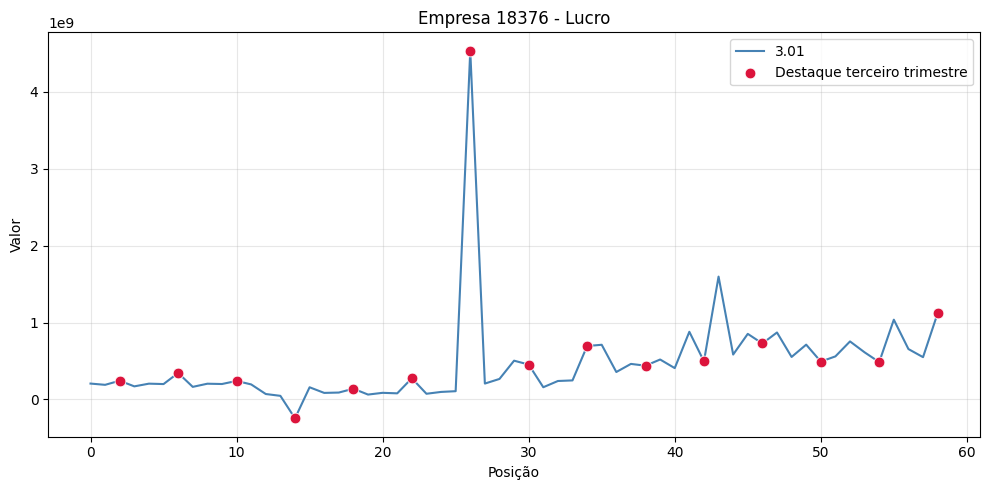

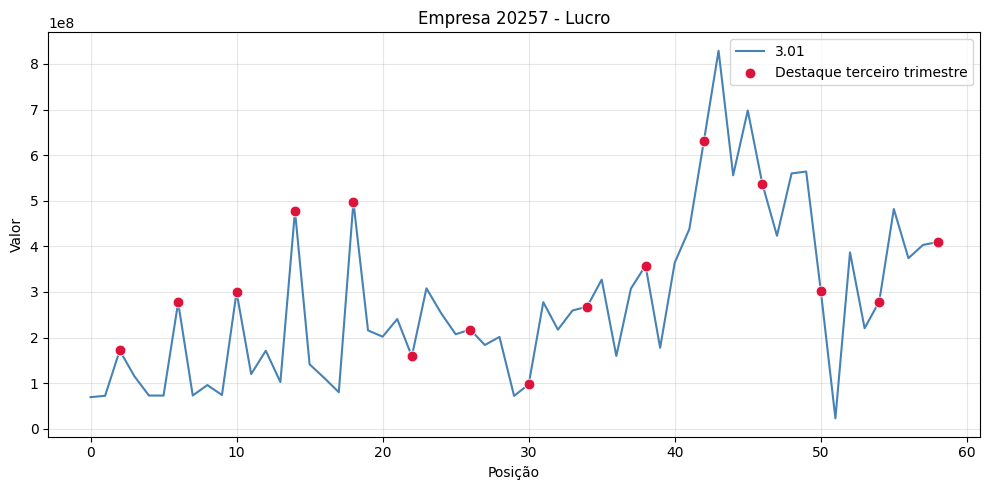

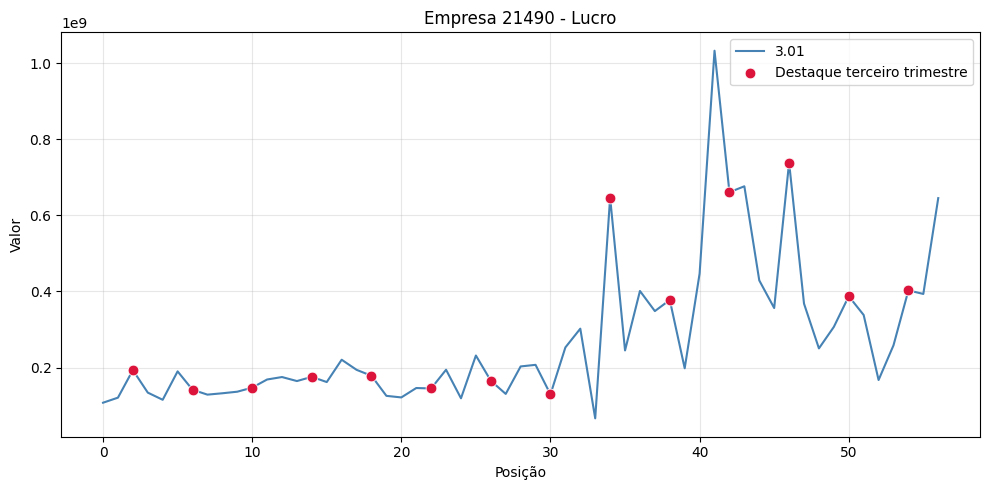

In [16]:
# ...existing code...
def plot_com_destaques(serie, n=4, offset=0, titulo=None, label='Série'):
    s = pd.Series(serie).reset_index(drop=True)
    x = np.arange(len(s))

    plt.figure(figsize=(10, 5))
    plt.plot(x, s.values, label=label, color='steelblue', linewidth=1.5)

    idx = np.arange(offset, len(s), n)  # ex.: 0,4,8,... (use offset=1 para 1,5,9,...)
    plt.scatter(idx, s.iloc[idx].values, color='crimson', s=60, zorder=3,
                edgecolors='white', linewidths=0.6, label=f'Destaque terceiro trimestre')

    plt.title(titulo or f'{label} (Destaque terceiro trimestre)')
    plt.xlabel('Posição')
    plt.ylabel('Valor')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Uso com a sua série:
for code in [2437, 18376, 20257, 21490]:
    plot_com_destaques(dados_indicadores.query(f"CD_CVM == {code}")['3.11'], n=4, offset=2, titulo=f'Empresa {code} - Lucro', label='3.01')

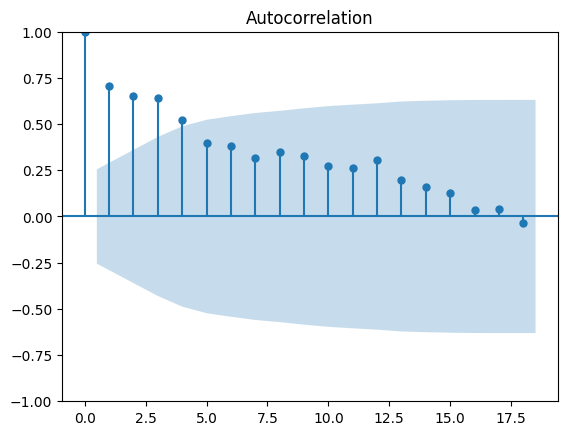

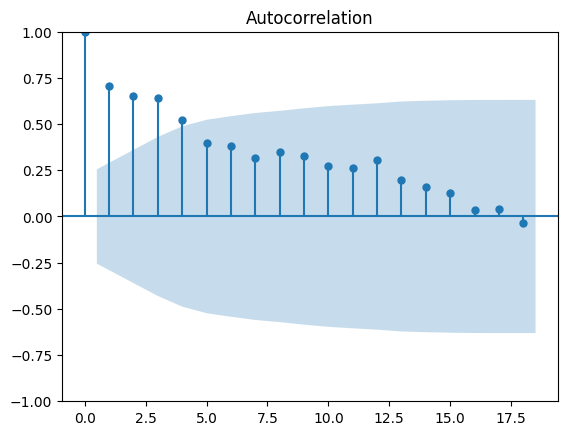

In [17]:
plot_acf(dados_indicadores.query(f"CD_CVM == 20257")['3.01'])

## Correlação Cruzada

O foco de predição será nos indicadores:
* 3.01 (Receitas de venda de Bens e/ou Serviços)
* 3.02 (Custo dos Bens e/ou Serviços)
* 3.11 (Lucro ou Prejuízo consolidado do Período)

In [18]:
def plot_ccf(lags, corr, indice, col, empresa=None):
    """
    Plota a CCF com linhas de confiança, eixos e legendas padronizados.
    - lags: array de lags
    - corr: array de correlações (mesmo tamanho de lags)
    - indice: nome da variável X
    - indicador: nome da variável Y
    - empresa: identificador opcional
    - n_obs: nº de observações para IC; se None usa len(corr) como aproximação
    - alpha: nível de significância (default 5%)
    """
    fig, ax =plt.subplots(figsize=(15, 6))
    plt.stem(lags, corr, use_line_collection=True)
    plt.title(f'CCF entre {indice} e {col} - Empresa {empresa}')
    confidence_interval = 1.96/np.sqrt(len(corr))
    ax.axhline(-confidence_interval, color='red', label='5% intervalo de confiança')
    ax.axhline(confidence_interval, color='red')
    ax.axvline(x = 0, color = 'black', lw = 1)
    ax.axhline(y = 0, color = 'black', lw = 1)
    ax.axhline(y = np.max(corr), color = 'blue', lw = 1,
            linestyle='--', label = 'Maior correlação +/-')
    ax.axhline(y = np.min(corr), color = 'blue', lw = 1,
            linestyle='--')
    ax.set(ylim = [-1, 1])
    # if y_label != x_label:
    #     ax.set_title('Correlação Cruzada ' + x_label + ' e ' + y_label, weight='bold', fontsize = 15)
    # if y_label == x_label:
    #     ax.set_title('Autocorrelação ' + x_label, weight='bold', fontsize = 15)
    ax.set_ylabel('Coeficientes de Correlação', weight='bold',
    fontsize = 12)
    #determina os pontos marcados no eixo X
    plt.xticks(range(min(lags), max(lags+1), 3))
    ax.set_xlabel('Lags', weight='bold', fontsize = 12)
    plt.legend()
# ...existing code...

In [2]:
# Calcular a Função de Correlação Cruzada (CCF) entre índices (VIF) e apenas os indicadores alvo
ccf_dict = {}
alvo_indicadores = ['3.01', '3.02', '3.11']

# Número de observações para o cálculo do intervalo de confiança (aprox.)
n_obs = len(indicadores_estac[2437])
conf_interval = 1.96 / np.sqrt(n_obs)

for empresa, df in indicadores_estac.items():
    # Indicadores alvo disponíveis neste df
    cols_indicadores = [c for c in alvo_indicadores if c in df.columns]
    if not cols_indicadores:
        continue

    # # Índices aprovados pelo VIF que existem em indices_norm_estac
    # cols_indices = [c for c in vif_finais.get(empresa, pd.Series(dtype=float)).index
    #                 if c in indices_norm_estac.columns]
    # if not cols_indices:
    #     continue

for indice in indices_estac.columns[1:]:
    serie_x = indices_estac[indice].dropna()
    for empresa, df in indicadores_estac.items():
        for col in cols_indicadores:
            serie_y = df[col].dropna()

            # Alinhar pelas datas em comum
            #print(f'{serie_x.shape} - {serie_y.shape}')

            aligned = pd.concat([serie_x, serie_y], axis=1, join='inner').dropna()
            if len(aligned) < 3:
                continue

            corr = ccf(aligned.iloc[:, 0], aligned.iloc[:, 1], adjusted=False)
            lags = np.arange(len(corr))
            ccf_dict[(empresa, indice, col)] = corr

NameError: name 'indicadores_estac' is not defined

In [20]:
ccf_dict[(2437, 'ibov', '3.01')]

array([-0.03232091,  0.06505161, -0.06453567,  0.08456084,  0.00347055,
        0.27864458, -0.09759673,  0.06333015, -0.22815514,  0.08372866,
        0.06309291,  0.13522476,  0.09167456, -0.1491097 ,  0.27538465,
       -0.53705608,  0.20997593,  0.05401178,  0.1235486 , -0.08209155,
        0.00095833, -0.10415999, -0.05038441,  0.09394258, -0.23759723,
        0.10813502, -0.01440926, -0.05878865,  0.23557194, -0.1265347 ,
        0.13075097, -0.07267938, -0.01339206,  0.02993911,  0.06037526,
        0.0096293 , -0.01732004, -0.03809489, -0.01210802,  0.00207134,
       -0.02393559, -0.00876407, -0.02655268, -0.00897711,  0.03989887,
        0.00633318, -0.00544046,  0.01709247,  0.01619877, -0.03057771,
       -0.00281815,  0.01565799, -0.00055379, -0.02180197, -0.01268599,
        0.01411292, -0.00082432, -0.00666429])

In [21]:
# Desempacotar ccf_dict em um DataFrame
records = []
for (empresa, indice_x, indicador), ccf_arr in ccf_dict.items():
    for lag, corr_val in enumerate(ccf_arr):
        records.append({
            'Indice': indice_x,
            'Empresa': empresa,
            'Indicador': indicador,
            'Lag': lag,          # statsmodels.ccf retorna lags >= 0
            'CCF': corr_val,
            'Abs_CCF': abs(corr_val)
        })

df_ccf = pd.DataFrame(records)

# Opcional: limitar por lag máximo (ex.: até 8)
lag_max = 8
df_ccf = df_ccf[df_ccf['Lag'] <= lag_max]

# Marcar significância pelo intervalo de confiança já calculado (conf_interval)
df_ccf['Significativo'] = df_ccf['Abs_CCF'] > conf_interval

# 1) Top N lags significativos em geral
topN = 10
top_lags = (df_ccf[df_ccf['Significativo']]
            .sort_values('Abs_CCF', ascending=False)
            .head(topN))
display(top_lags)

# 2) Ranking por par (Indice, Empresa, Indicador): melhor lag por par
idx_max = (df_ccf[df_ccf['Significativo']]
           .groupby(['Empresa', 'Indice', 'Indicador'])['Abs_CCF']
           .idxmax())
ranked_pairs = (df_ccf.loc[idx_max]
                .sort_values('Abs_CCF', ascending=False)
                .reset_index(drop=True))
display(ranked_pairs.head(topN))

,Indice,Empresa,Indicador,Lag,CCF,Abs_CCF,Significativo
642,ibov,21490,3.11,4,-0.626943,0.626943,True
1338,iee,21490,3.11,4,-0.580337,0.580337,True
10132,PIB Corrente,20257,3.02,1,0.576699,0.576699,True
12214,Vol. VA Agro,20257,3.02,0,0.565043,0.565043,True
26831,T-bonds,20257,3.02,1,0.562560,0.562560,True
1339,iee,21490,3.11,5,0.552158,0.552158,True
5393,INCC-Brasil-DI,21490,3.01,8,-0.520846,0.520846,True
3370,igpm,21490,3.02,6,-0.519114,0.519114,True
2151,vix,2437,3.02,5,0.516247,0.516247,True
4762,IPAOG-DI,21490,3.02,6,-0.515928,0.515928,True


,Indice,Empresa,Indicador,Lag,CCF,Abs_CCF,Significativo
0,ibov,21490,3.11,4,-0.626943,0.626943,True
1,iee,21490,3.11,4,-0.580337,0.580337,True
2,PIB Corrente,20257,3.02,1,0.576699,0.576699,True
3,Vol. VA Agro,20257,3.02,0,0.565043,0.565043,True
4,T-bonds,20257,3.02,1,0.562560,0.562560,True
5,INCC-Brasil-DI,21490,3.01,8,-0.520846,0.520846,True
6,igpm,21490,3.02,6,-0.519114,0.519114,True
7,vix,2437,3.02,5,0.516247,0.516247,True
8,IPAOG-DI,21490,3.02,6,-0.515928,0.515928,True
9,INCC-Brasil-DI,21490,3.02,7,-0.504726,0.504726,True


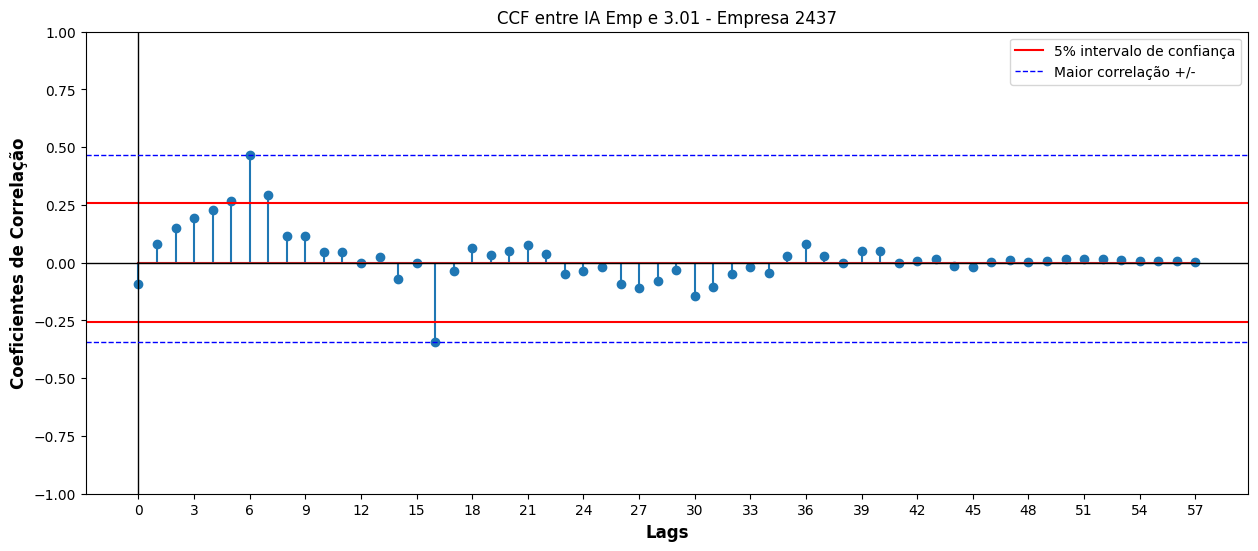

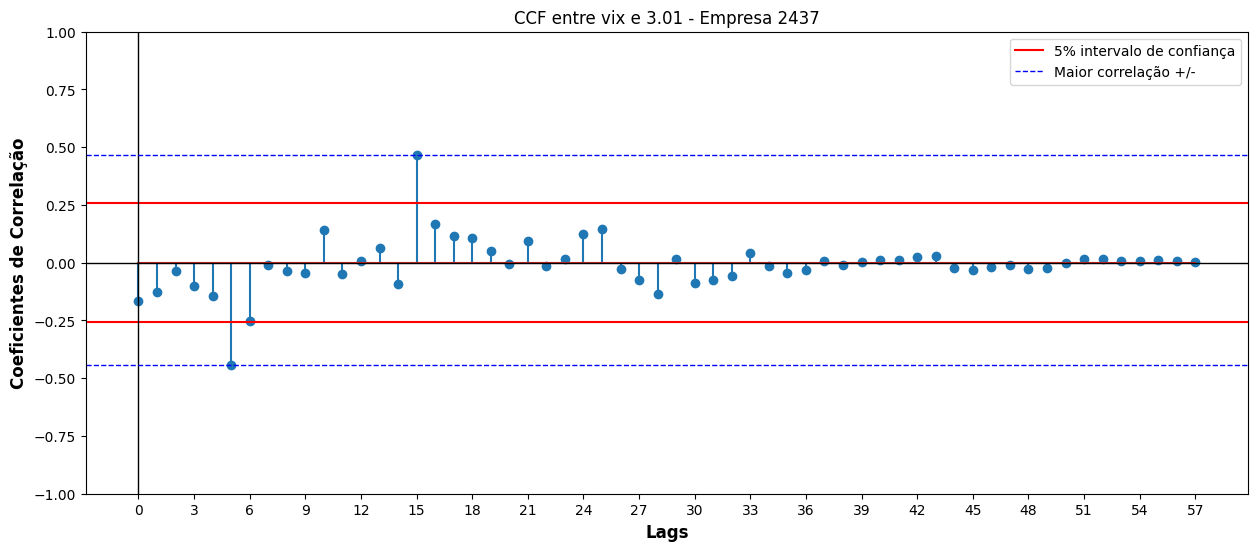

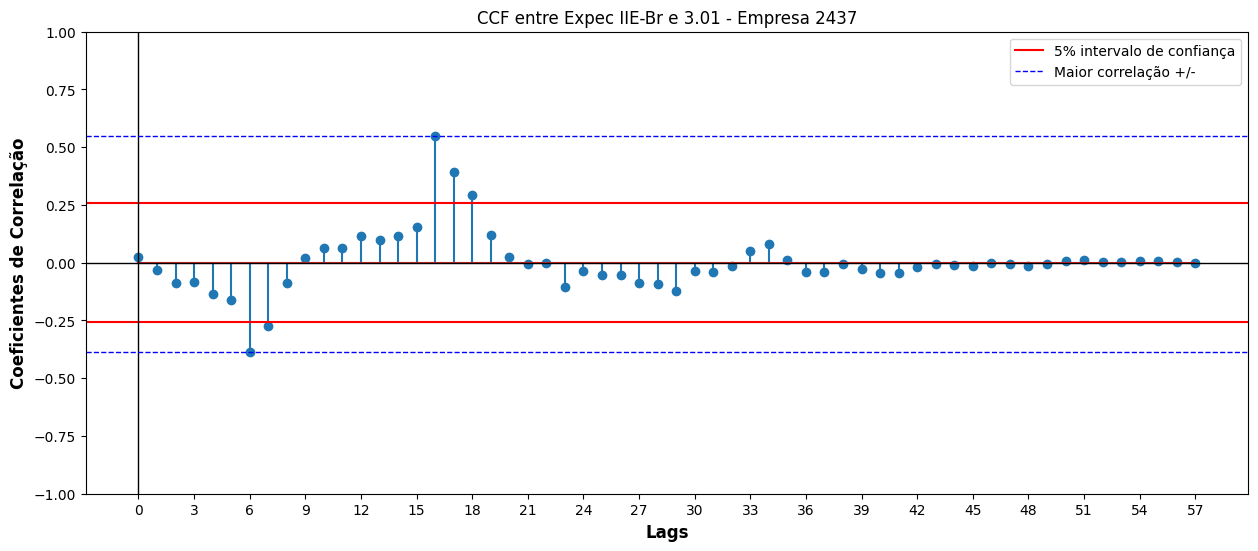

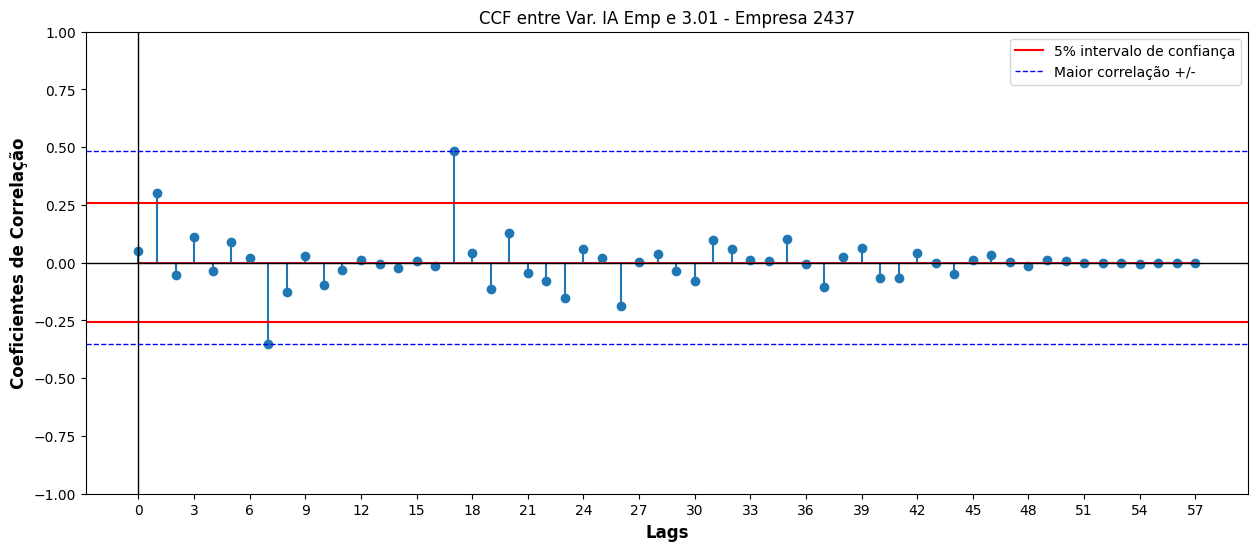

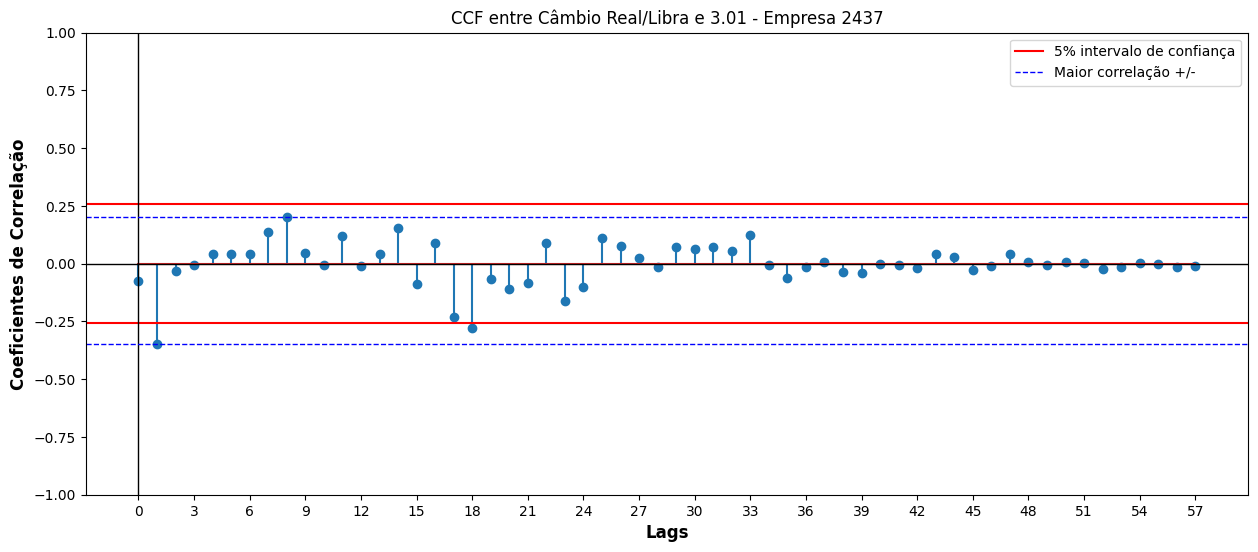

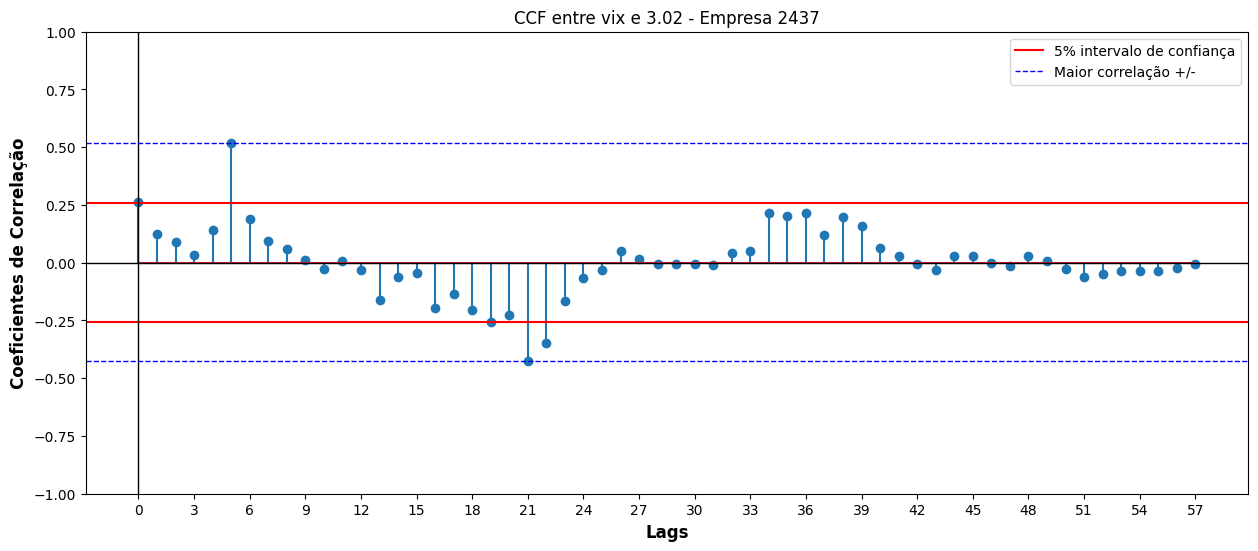

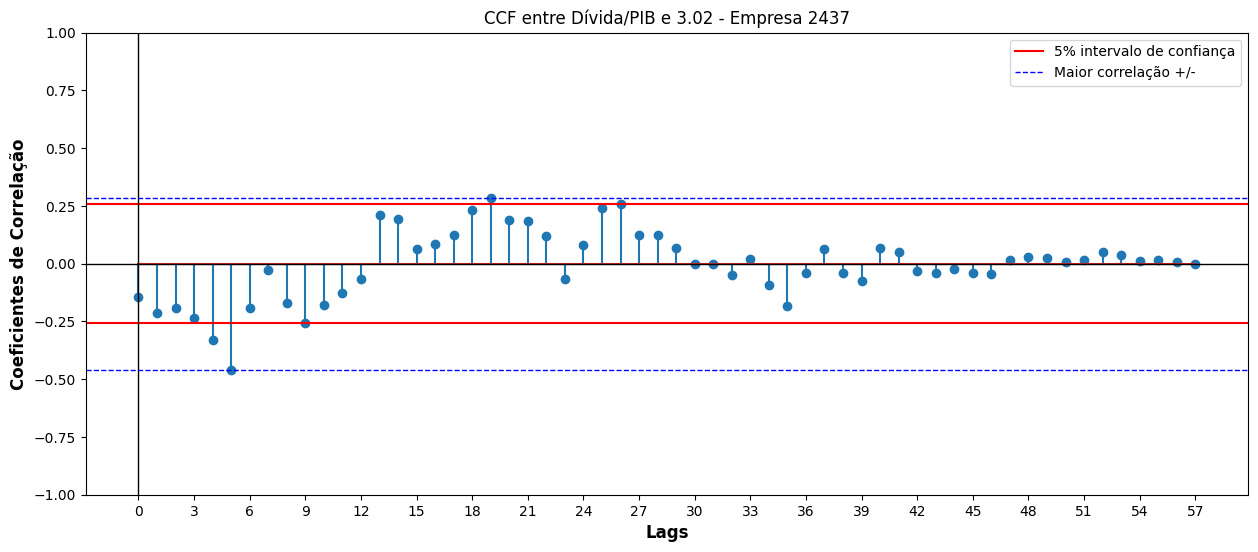

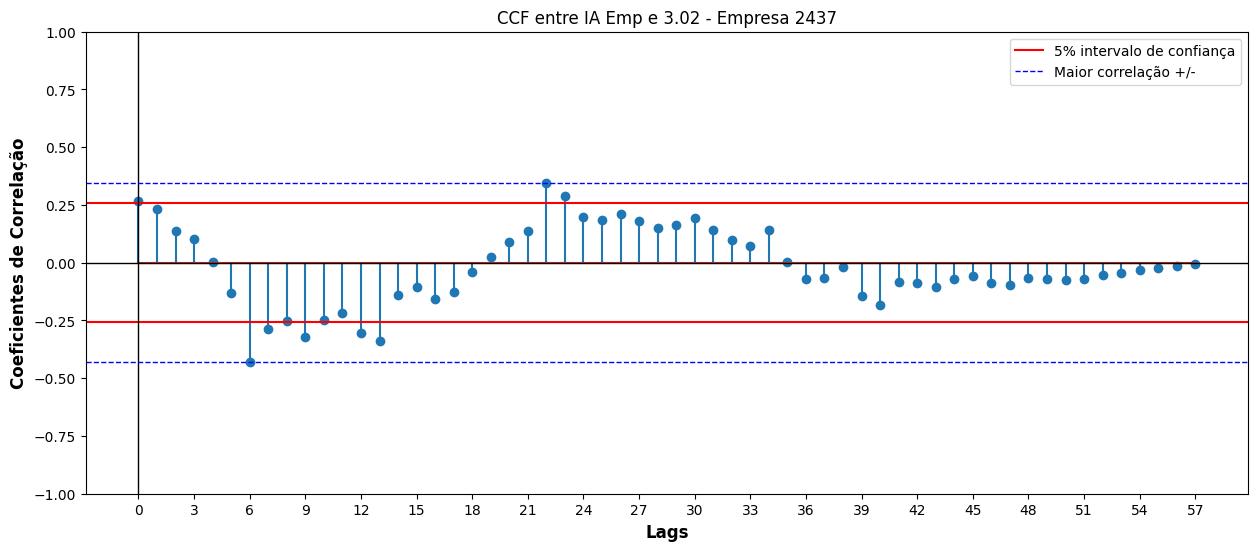

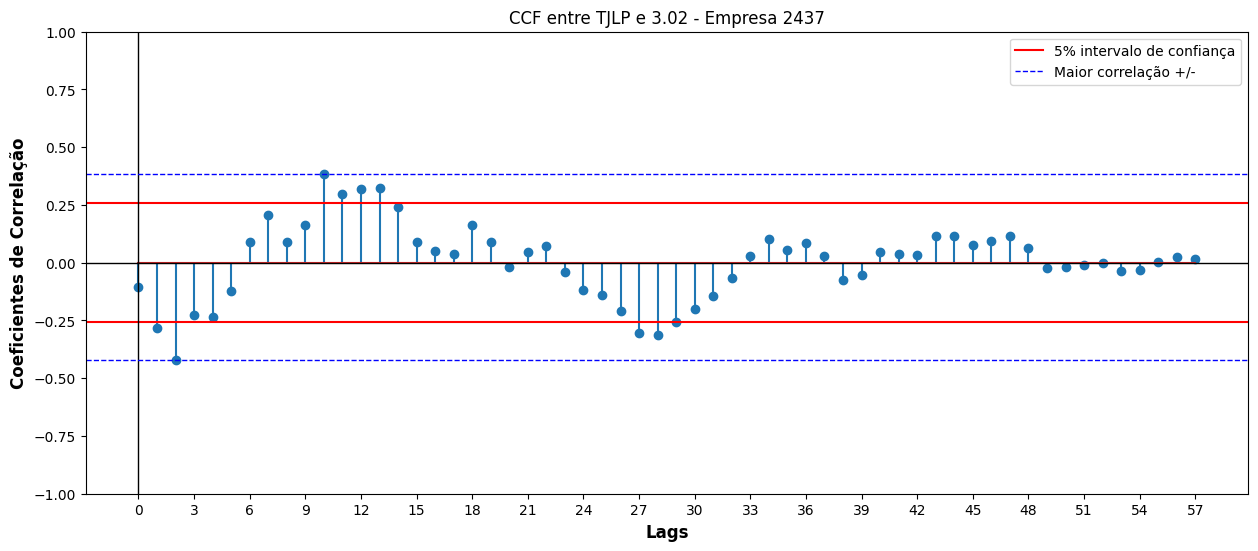

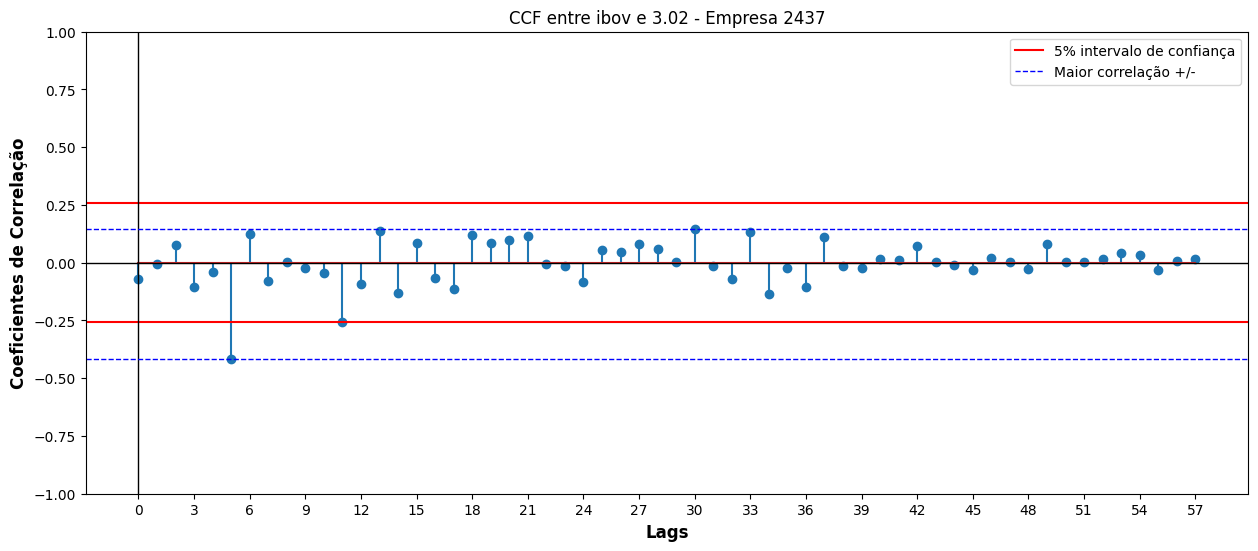

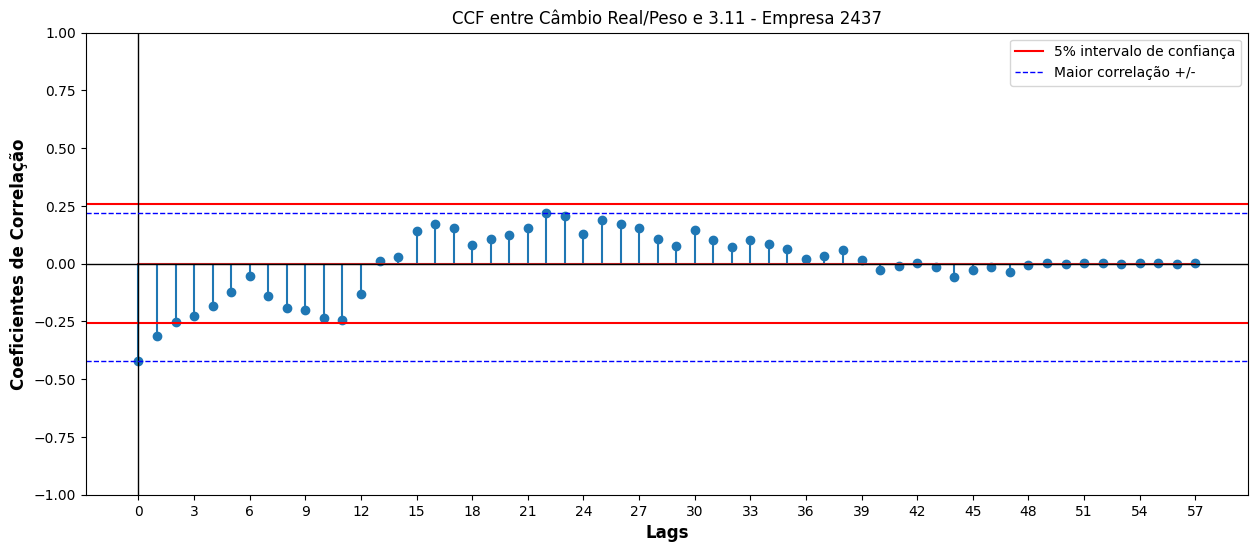

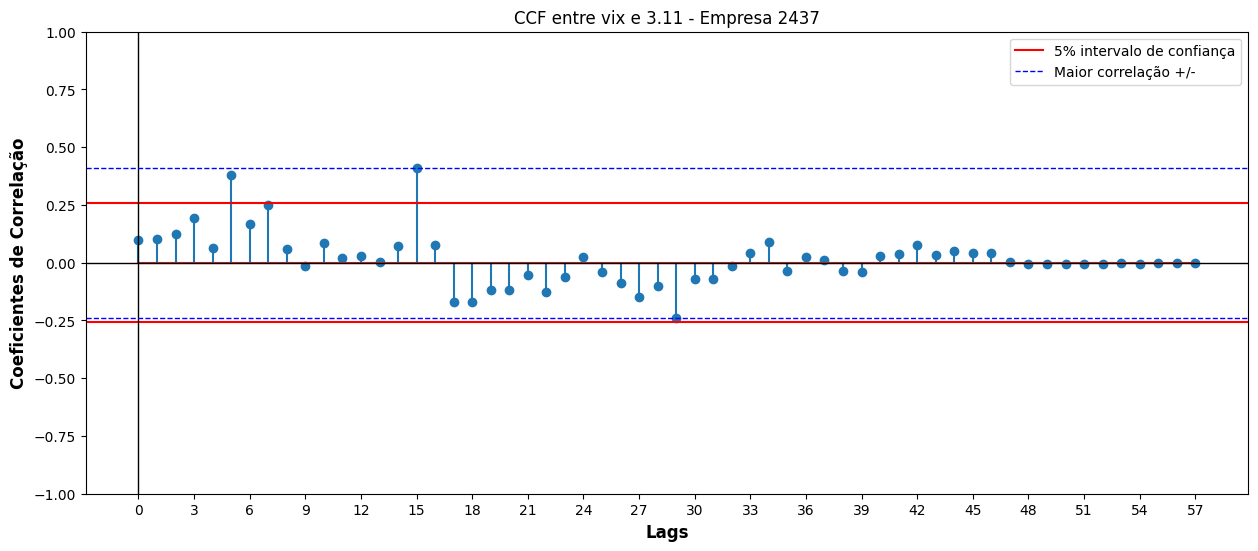

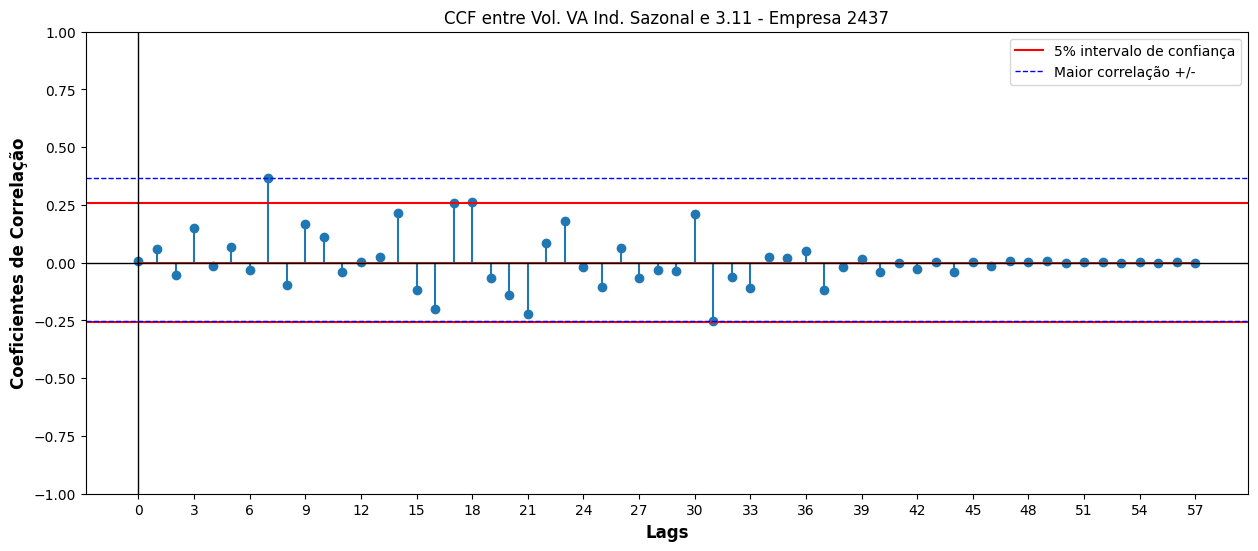

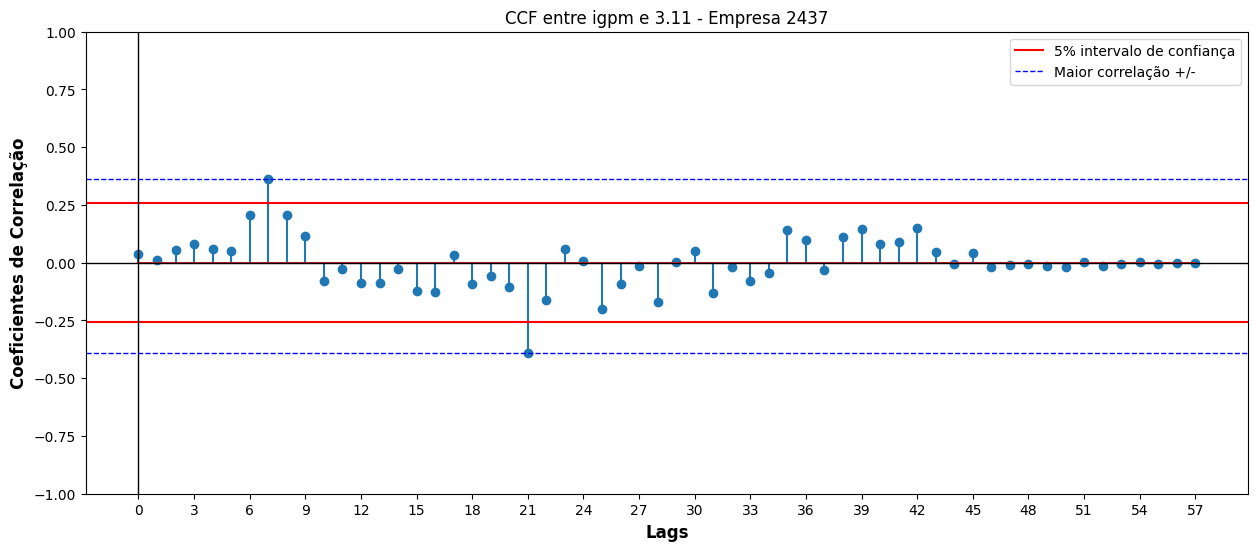

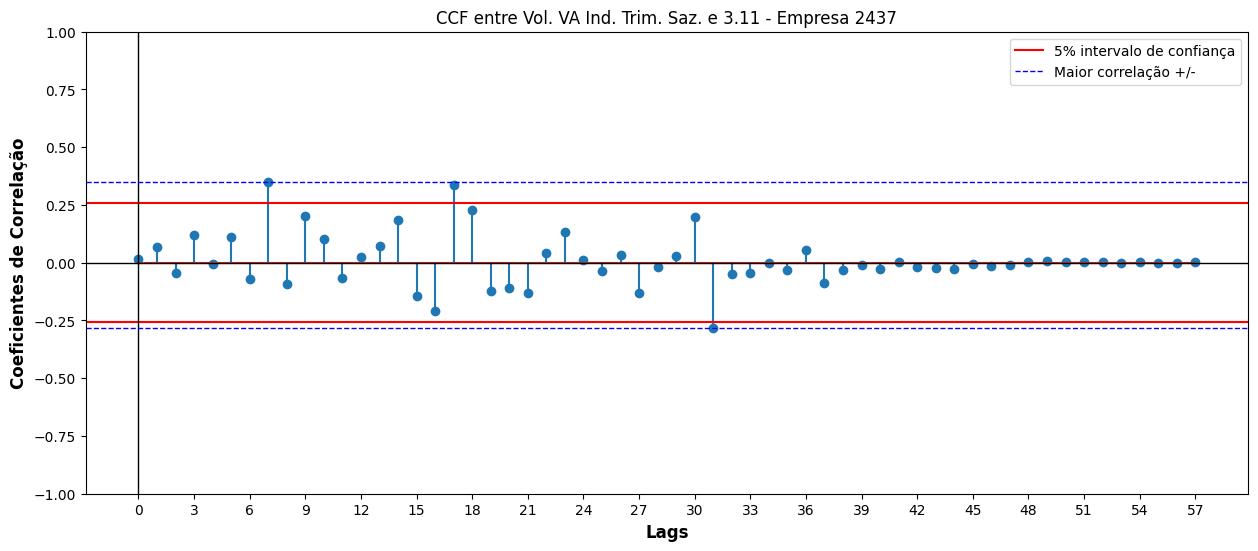

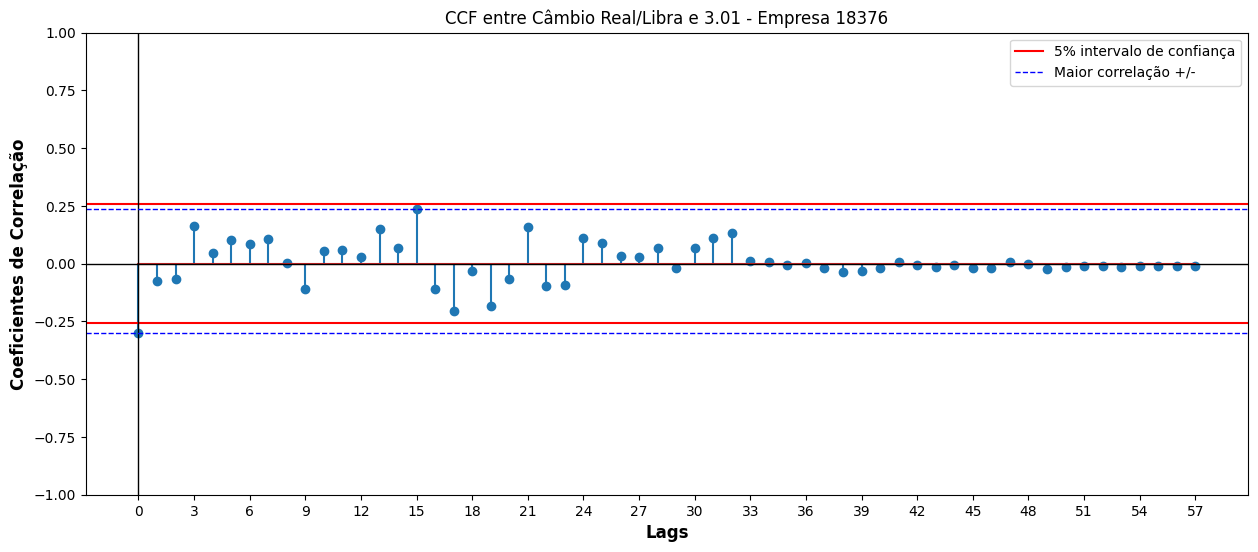

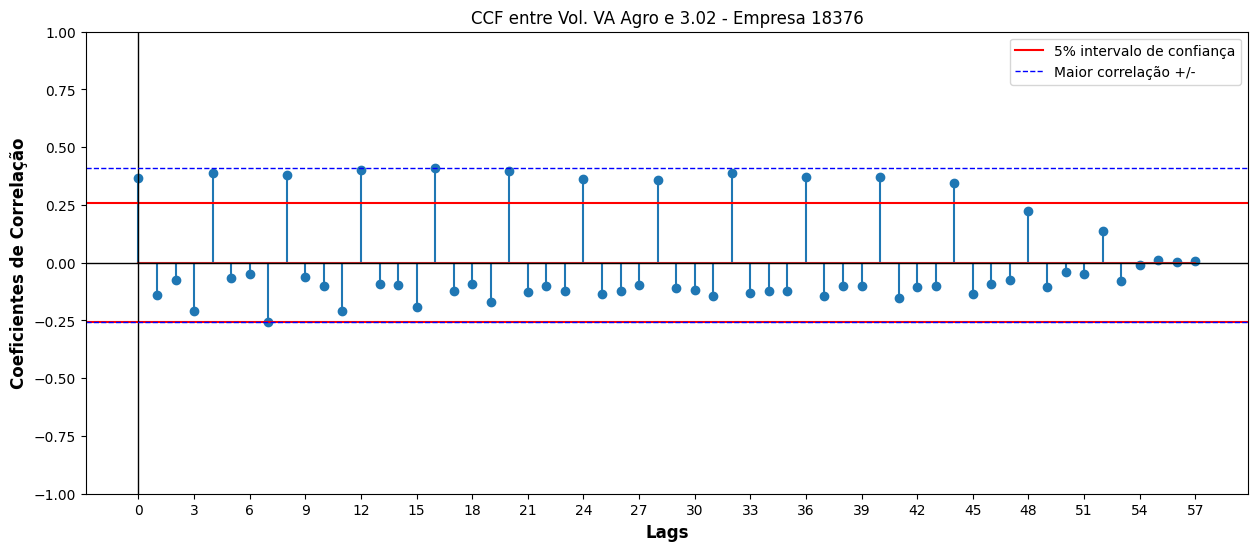

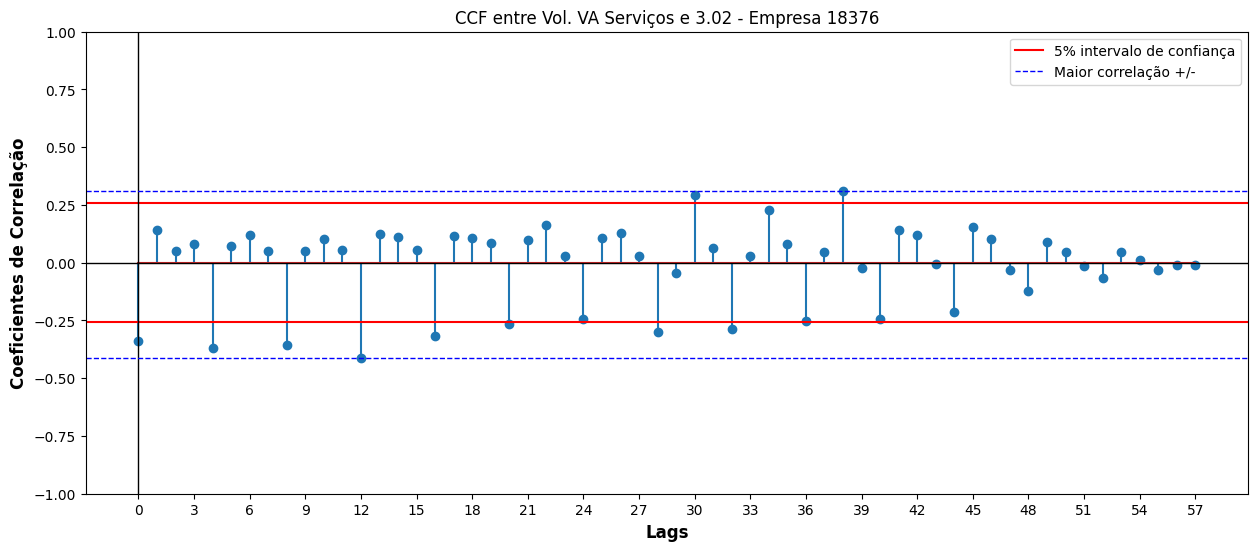

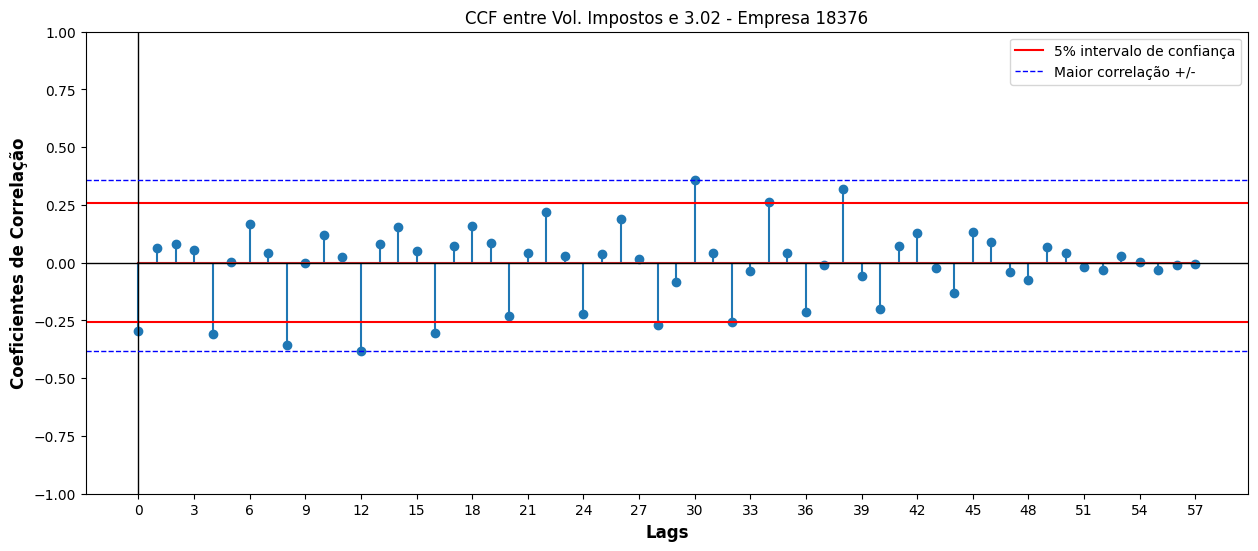

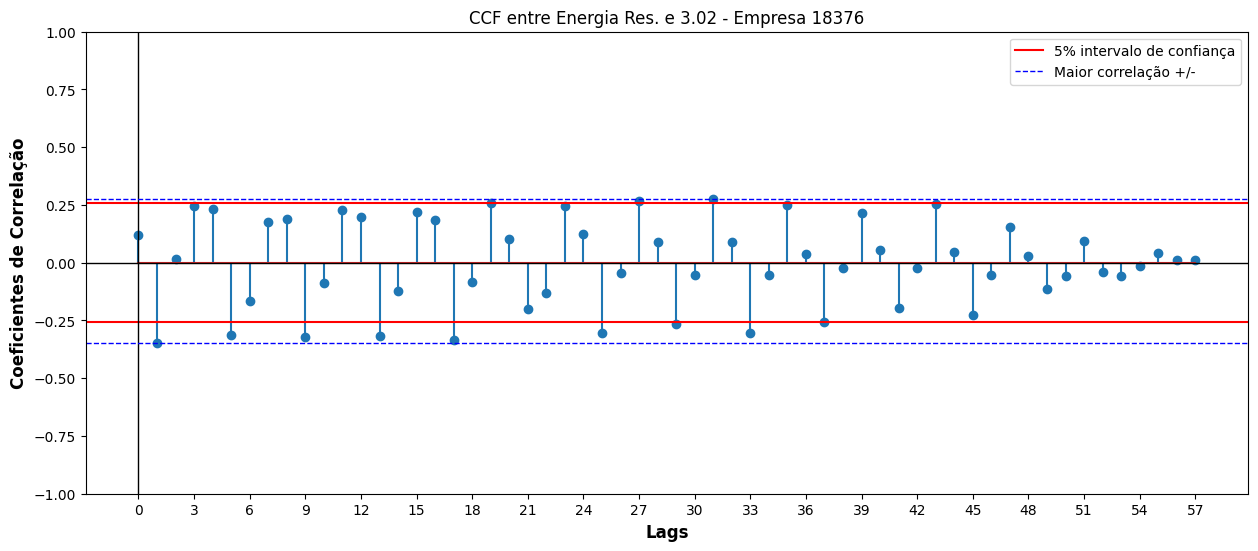

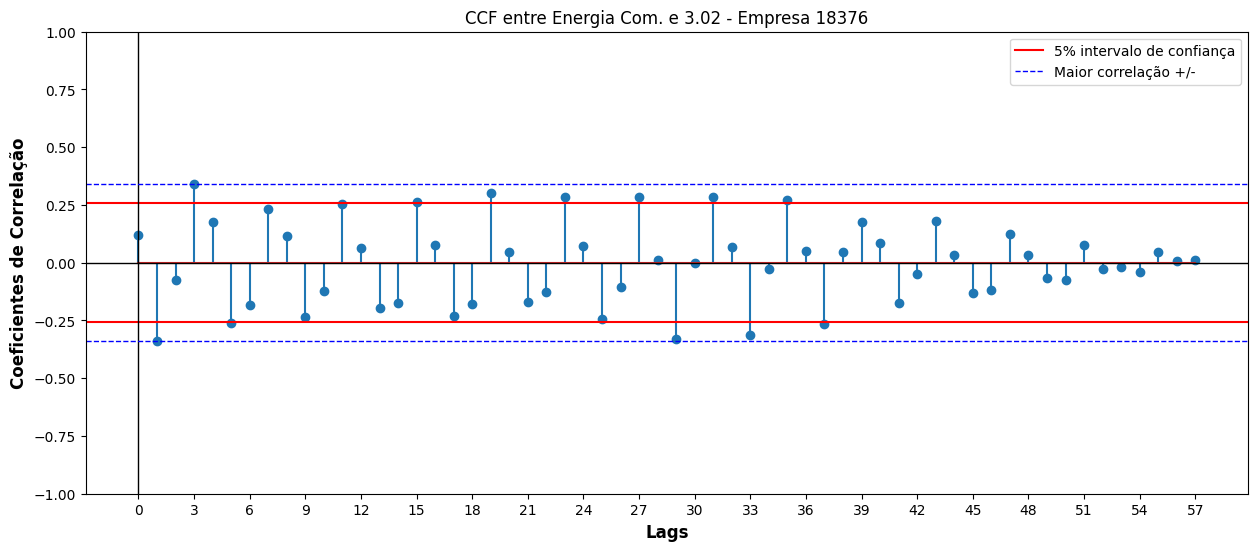

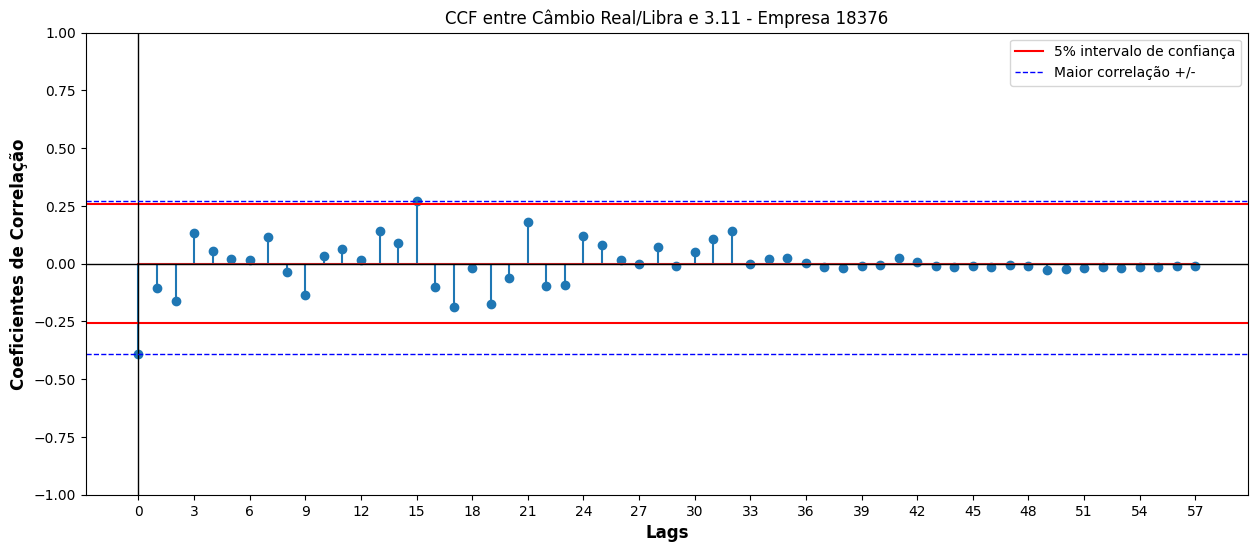

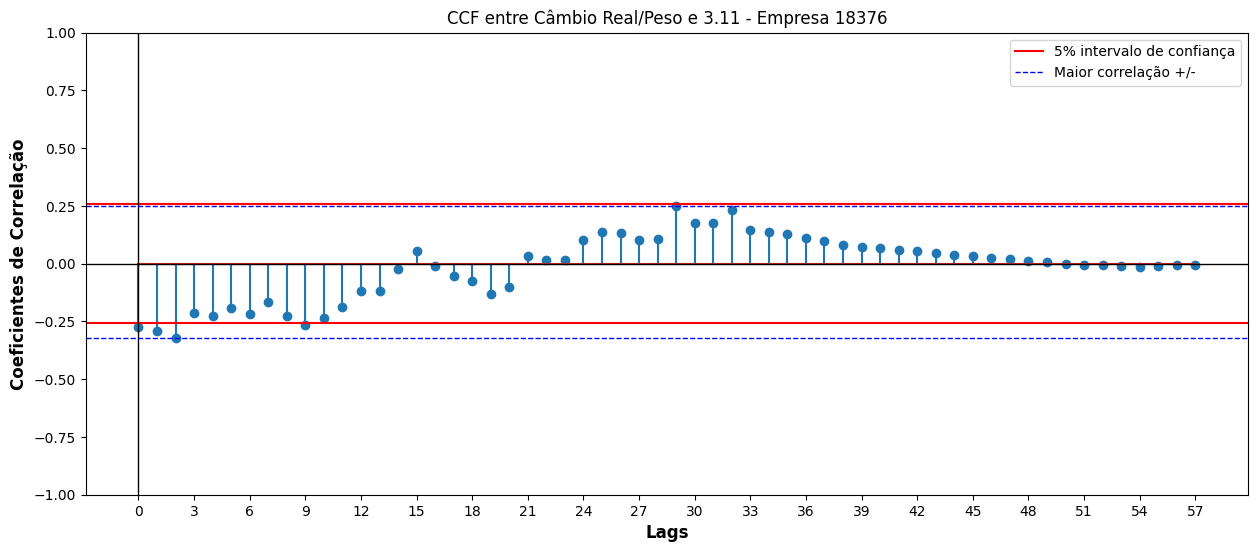

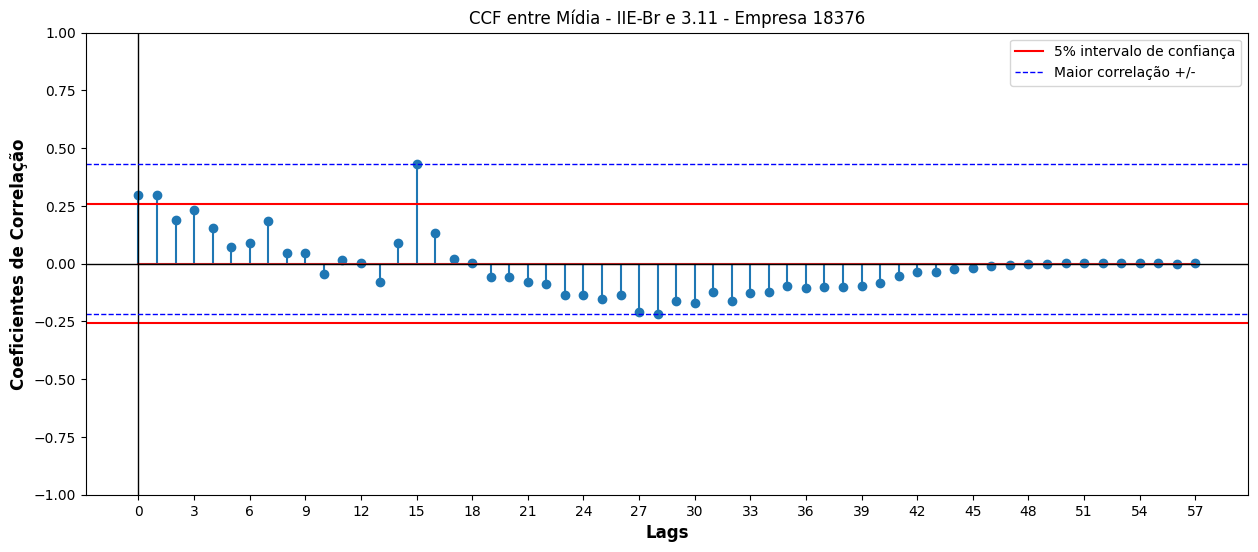

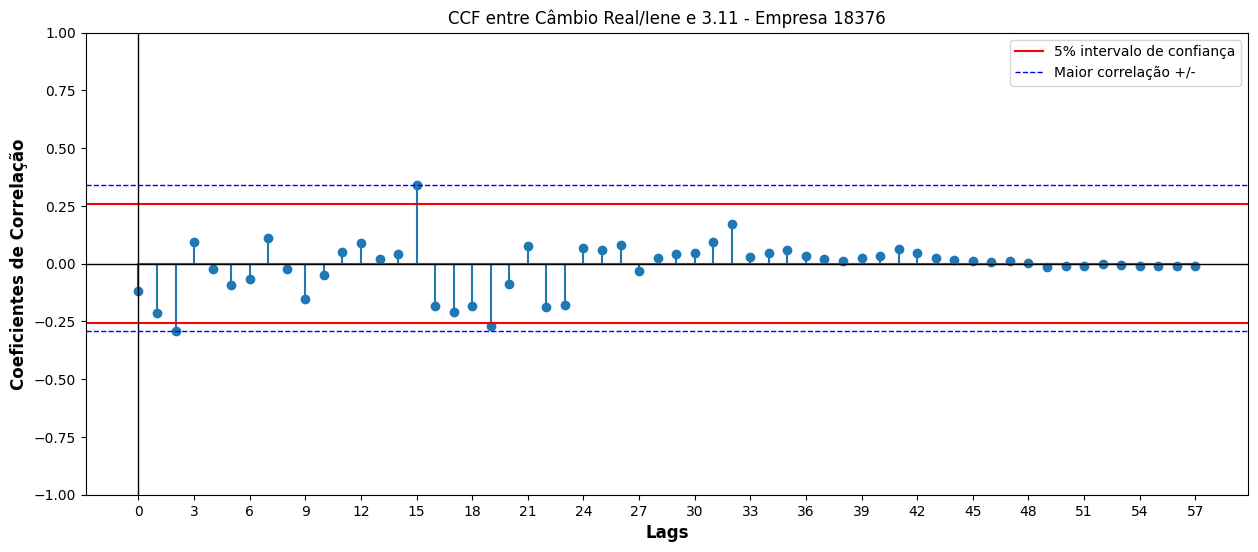

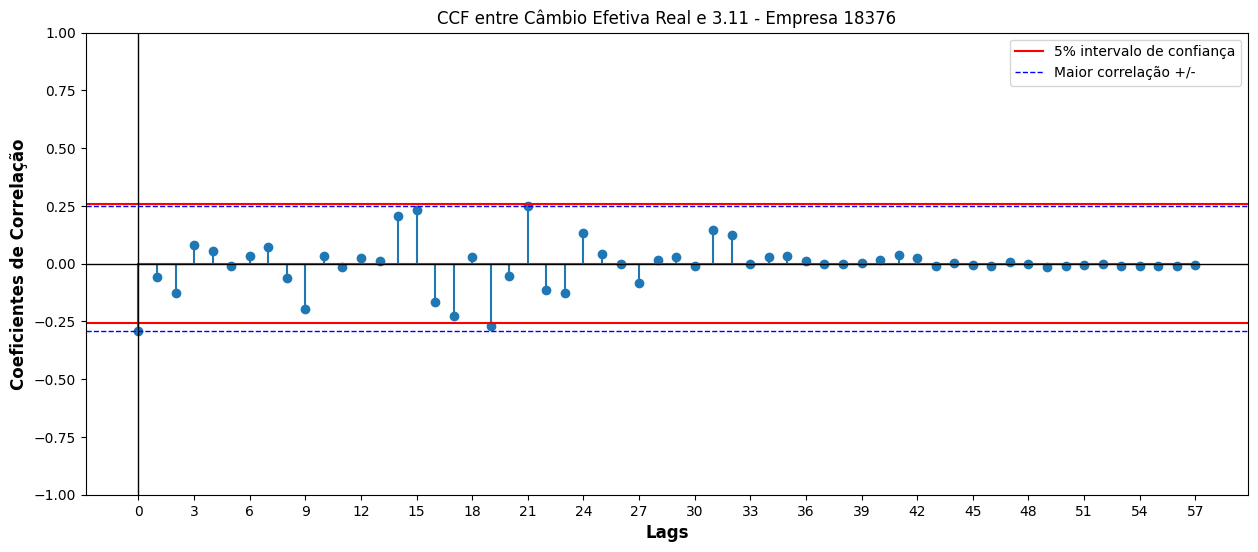

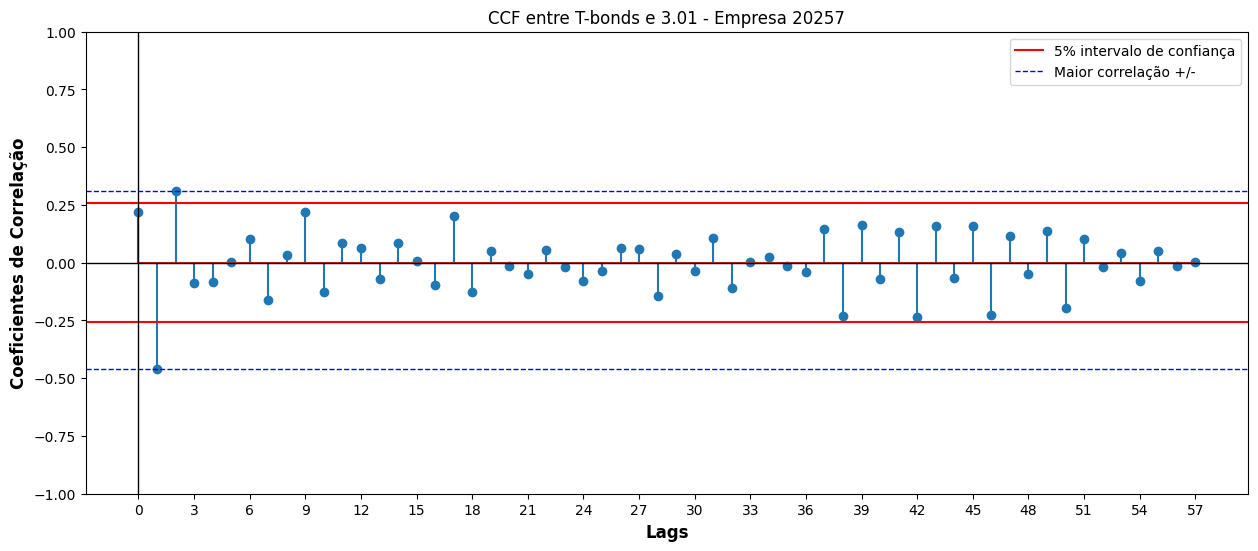

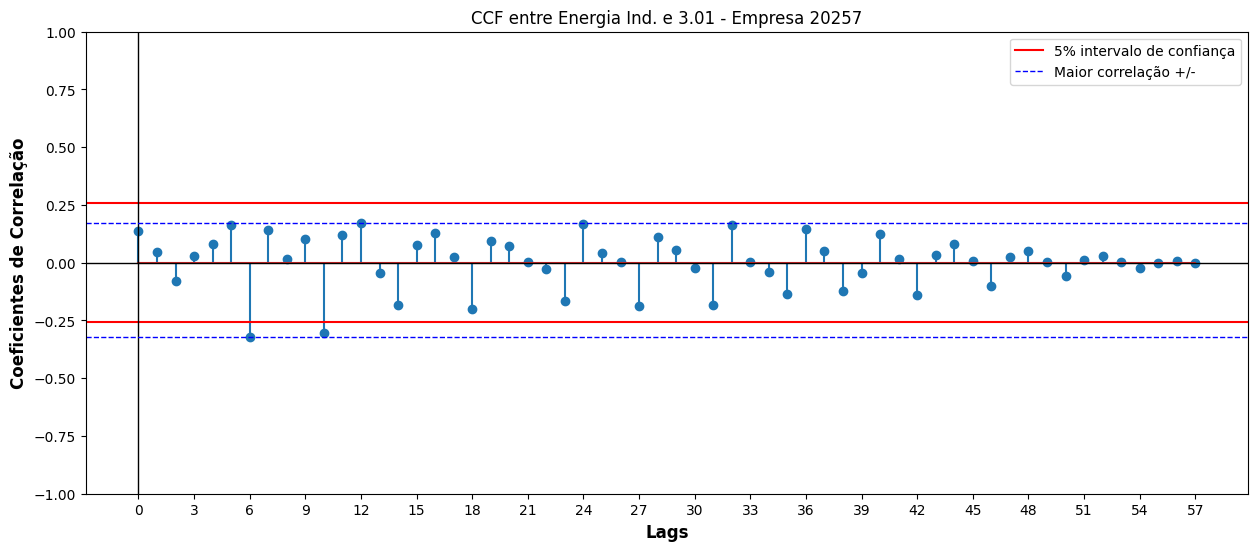

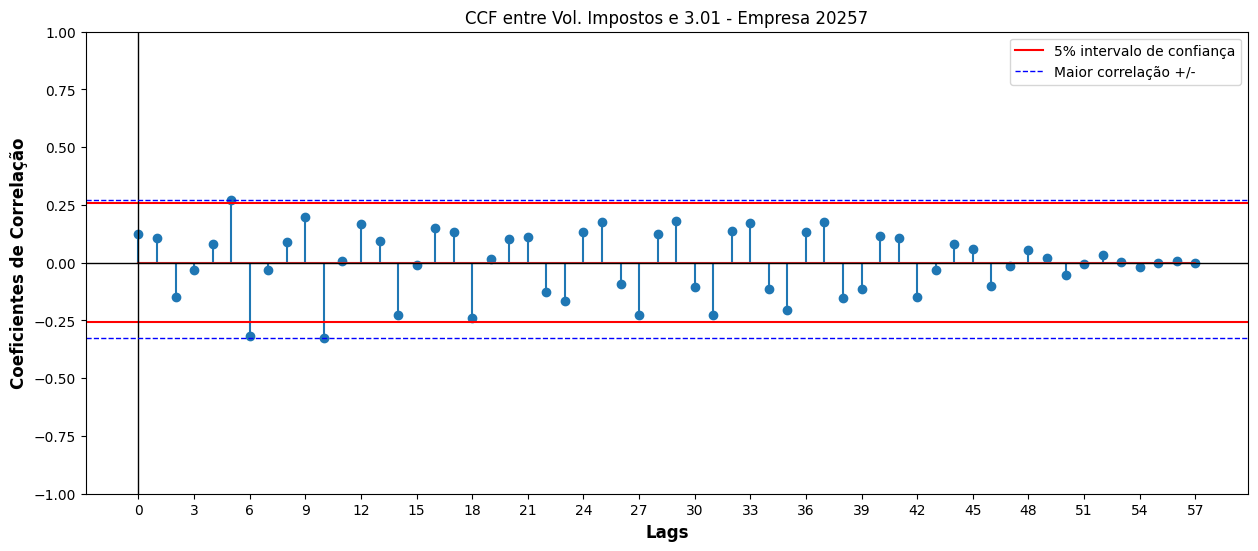

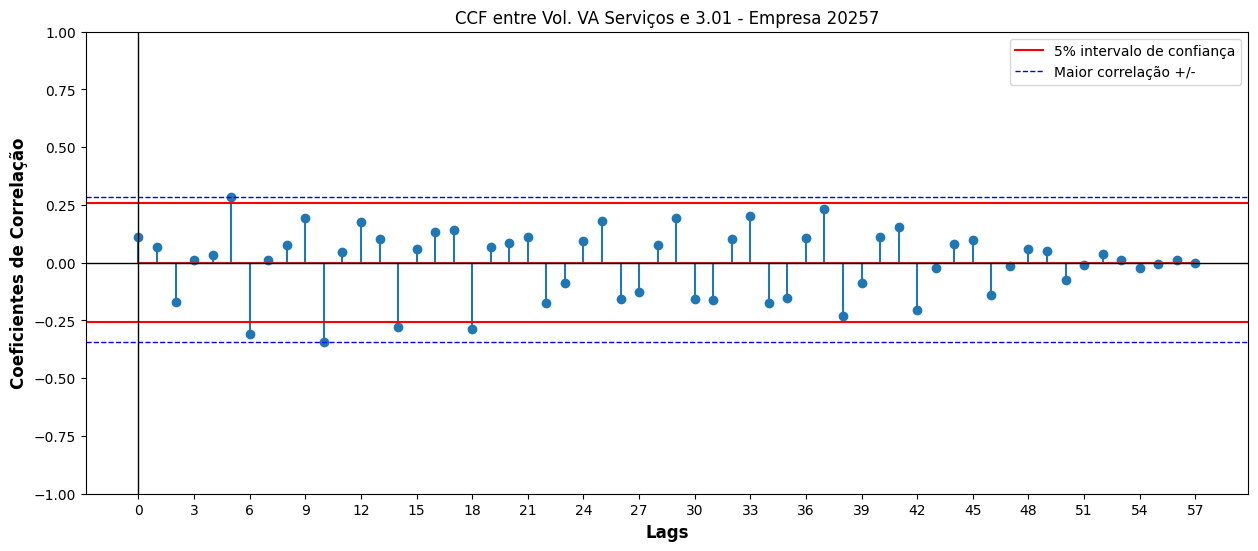

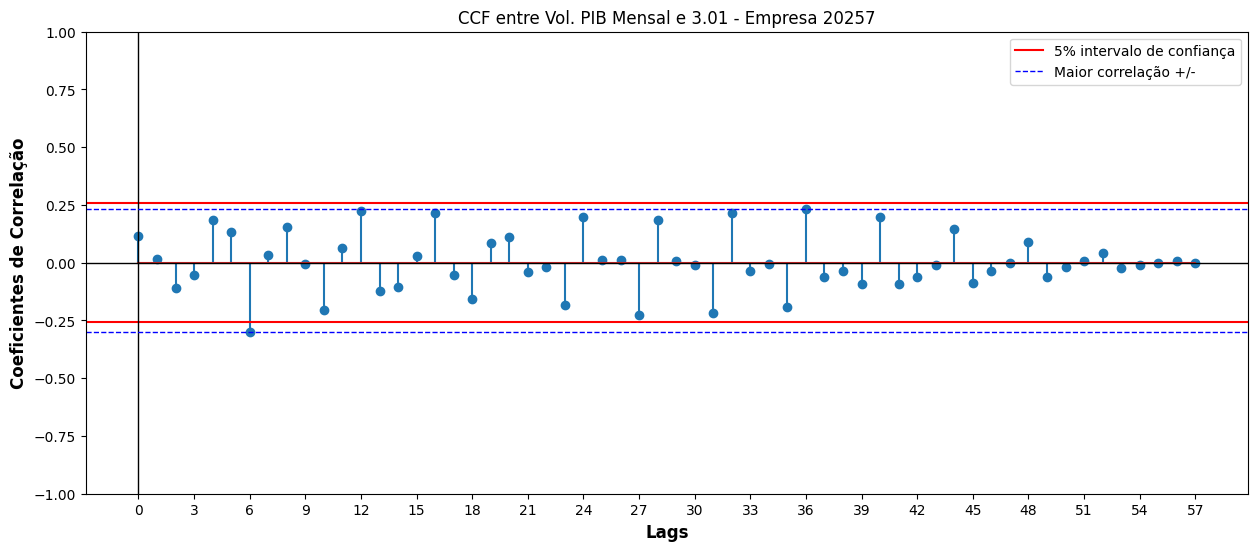

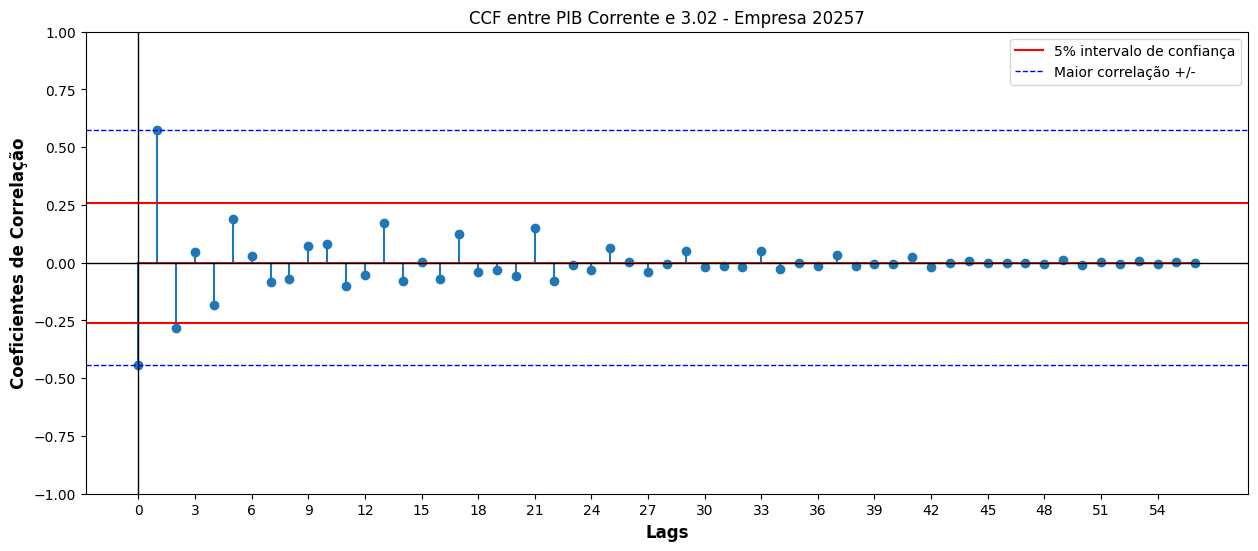

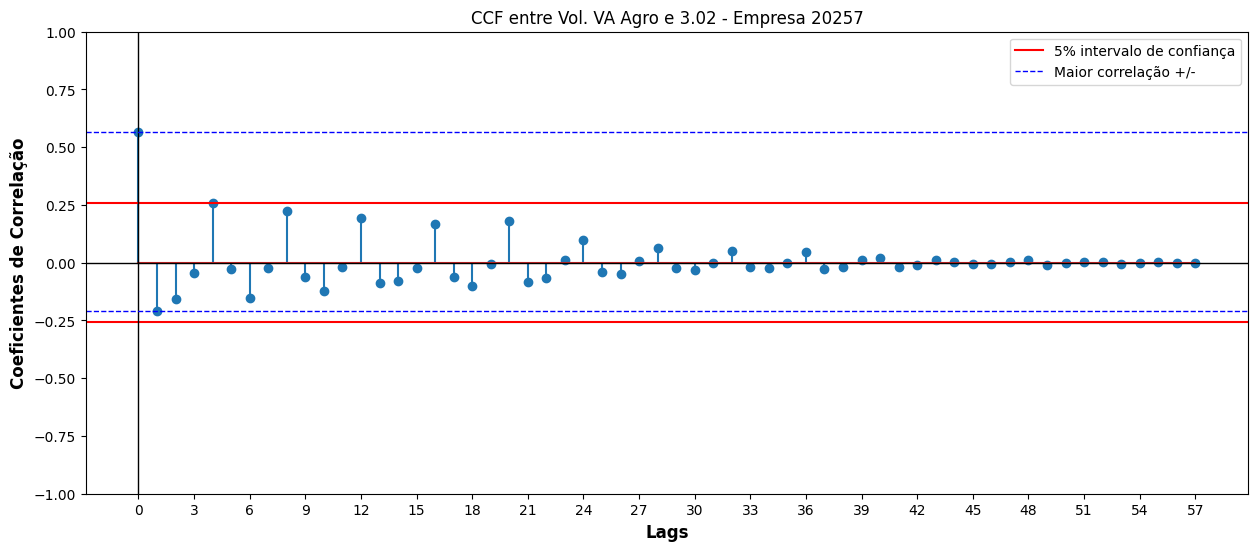

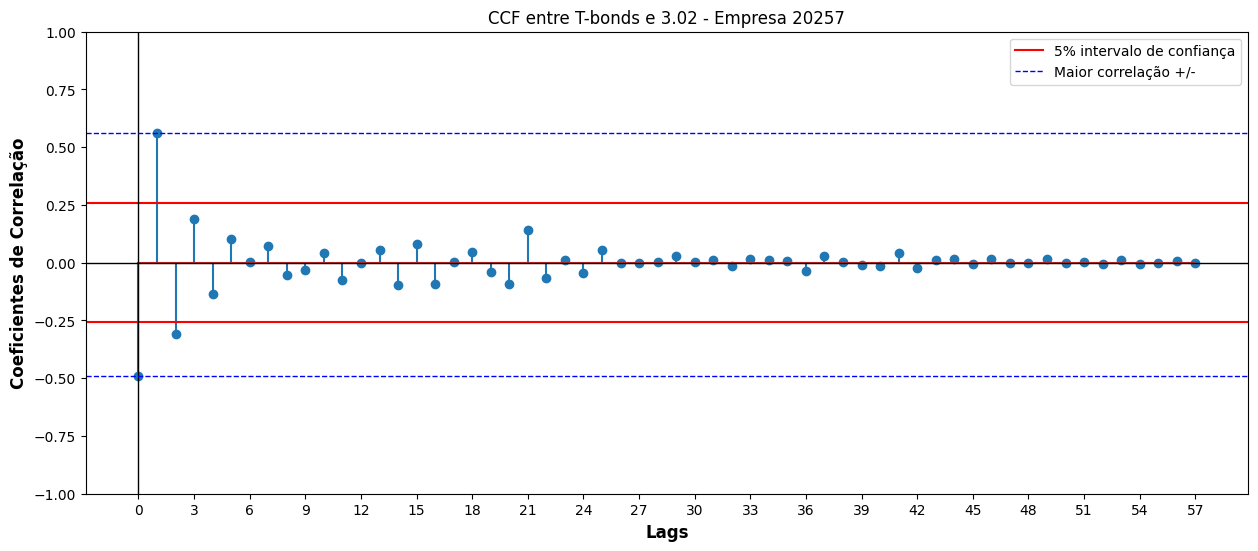

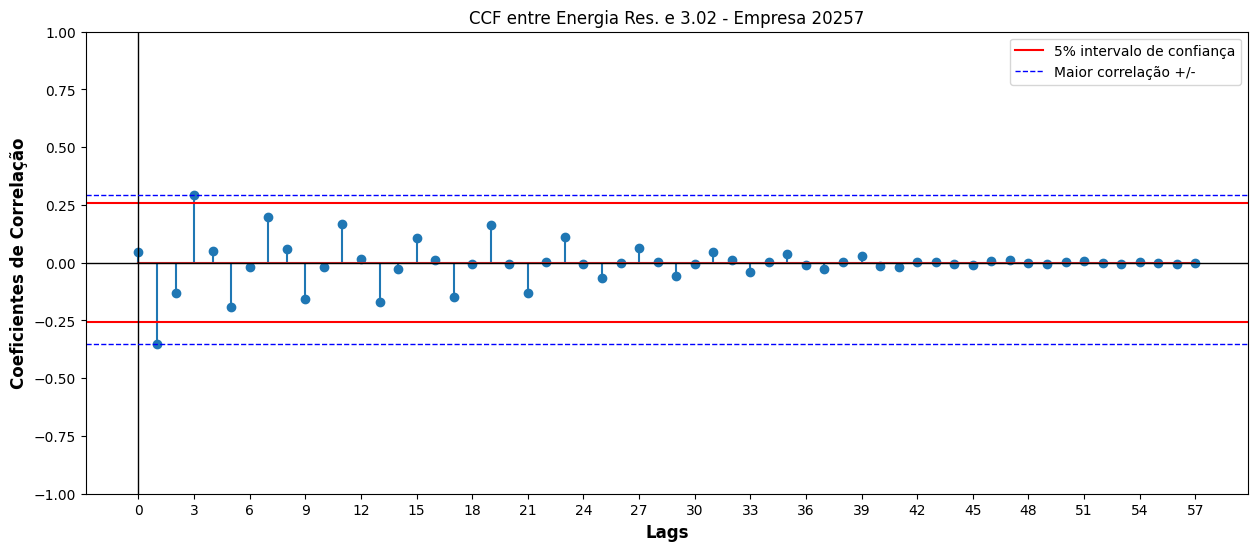

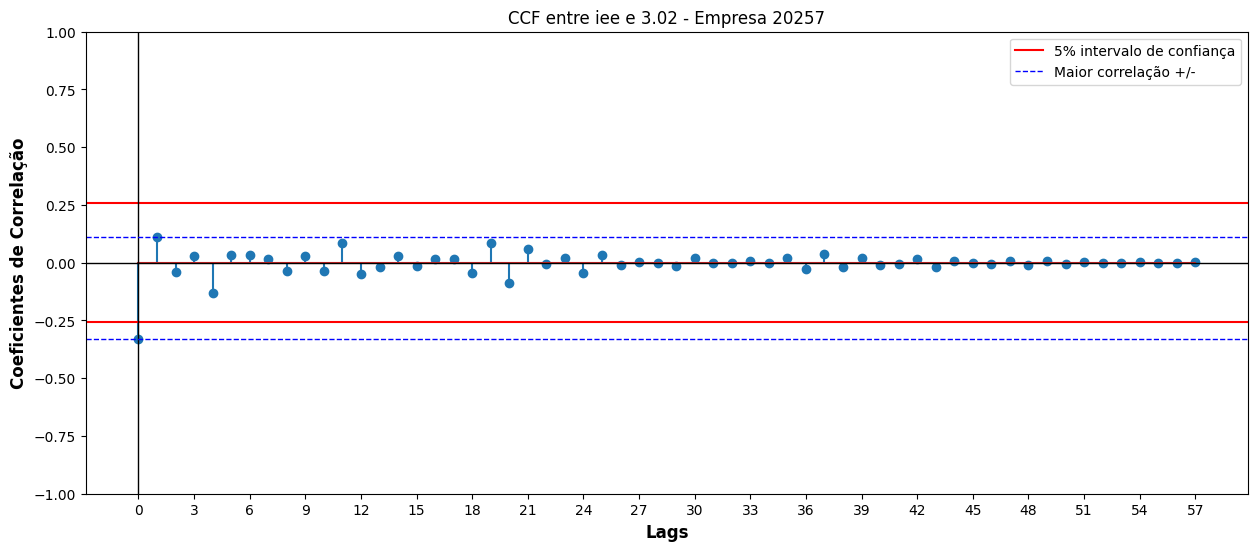

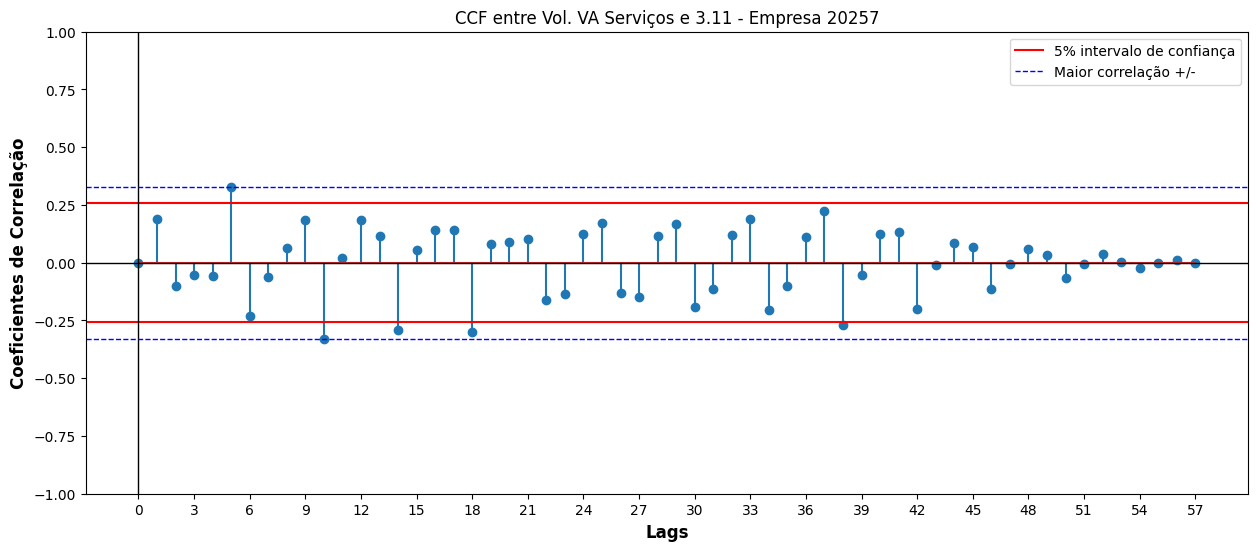

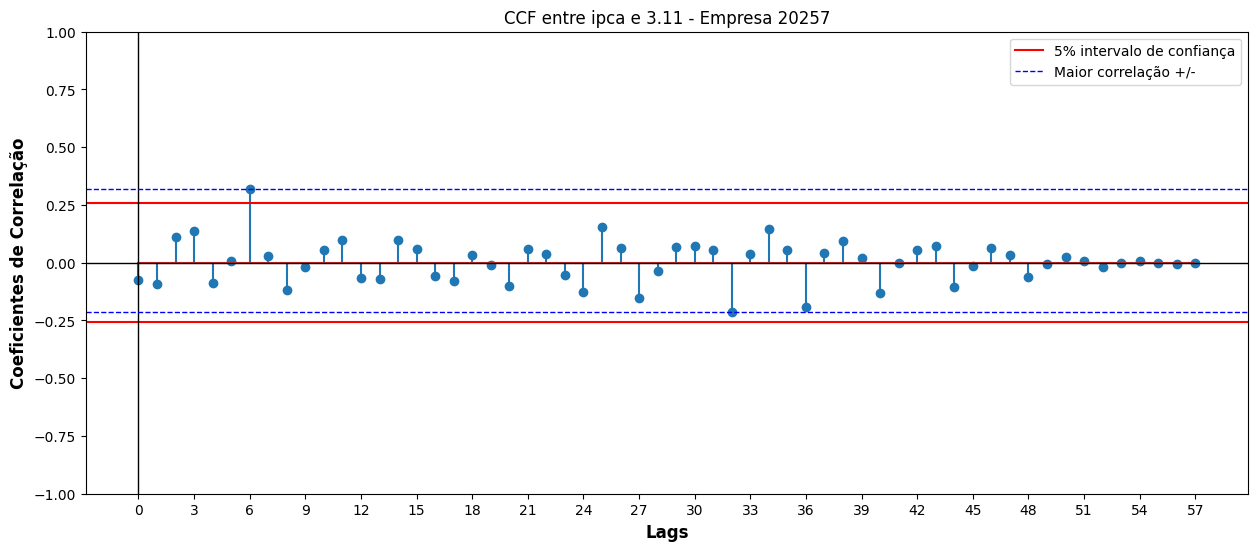

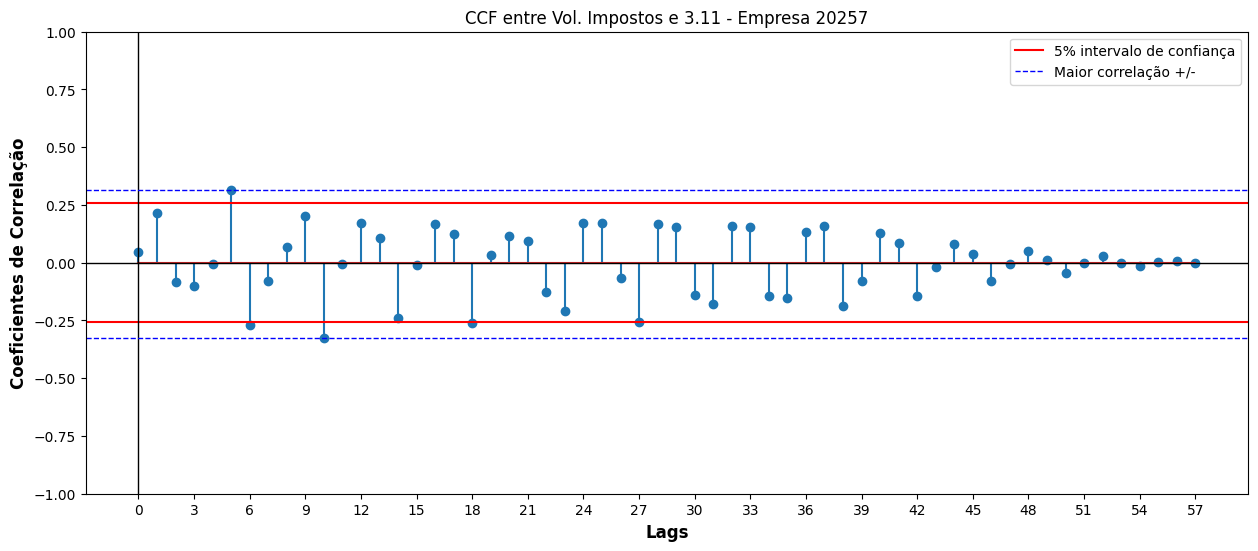

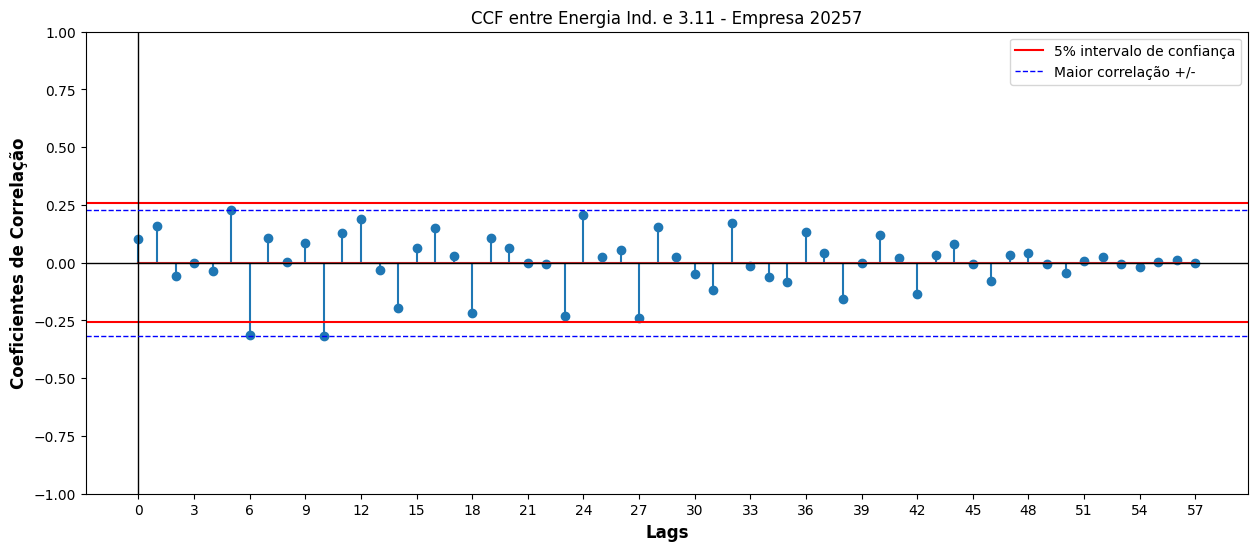

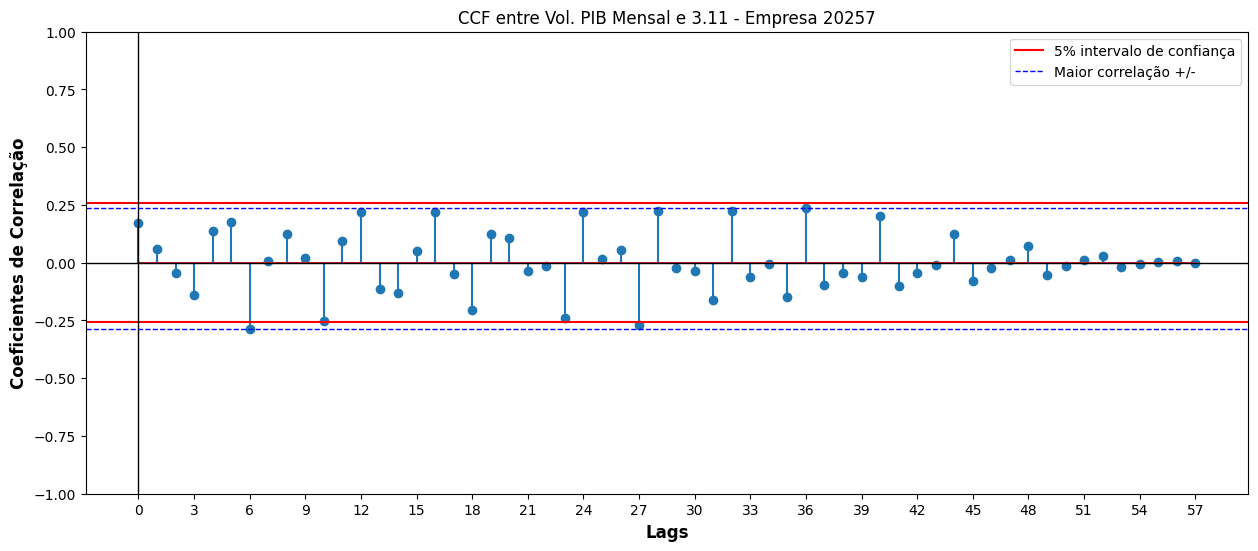

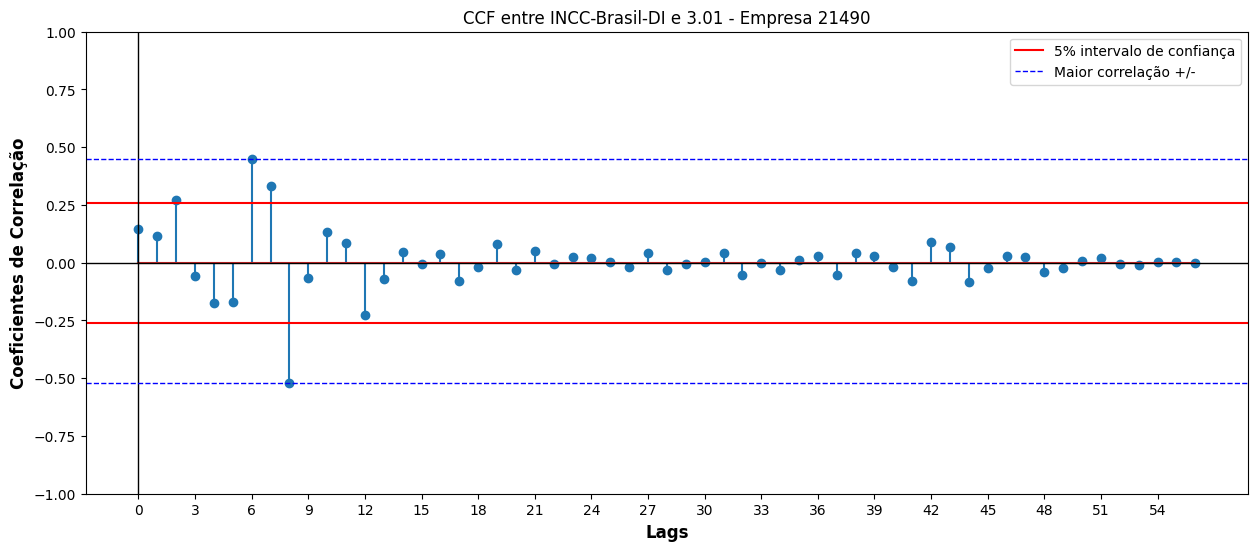

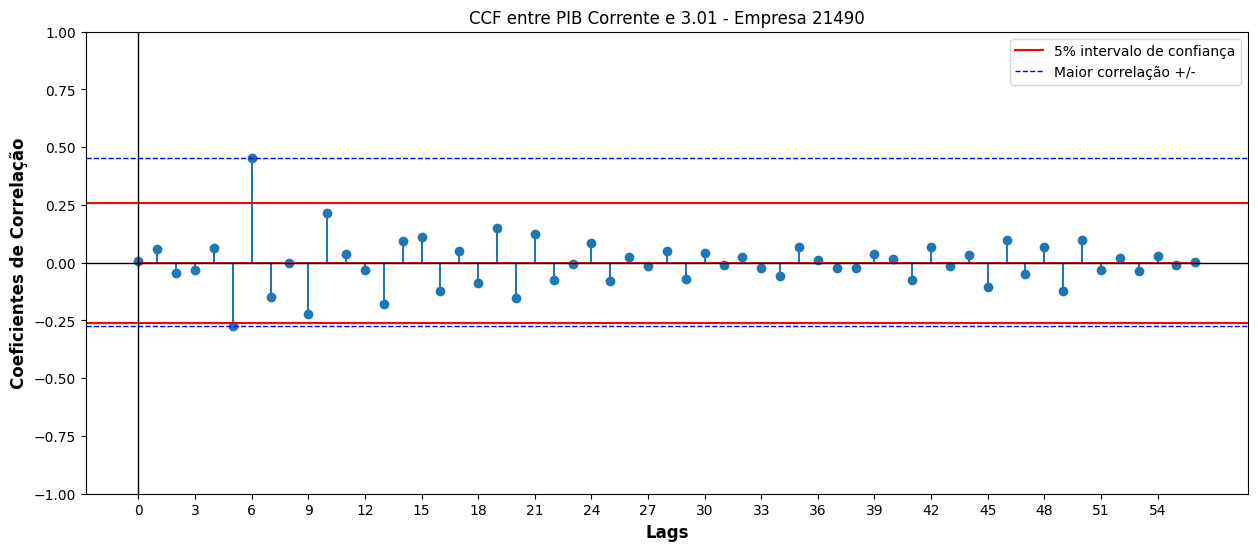

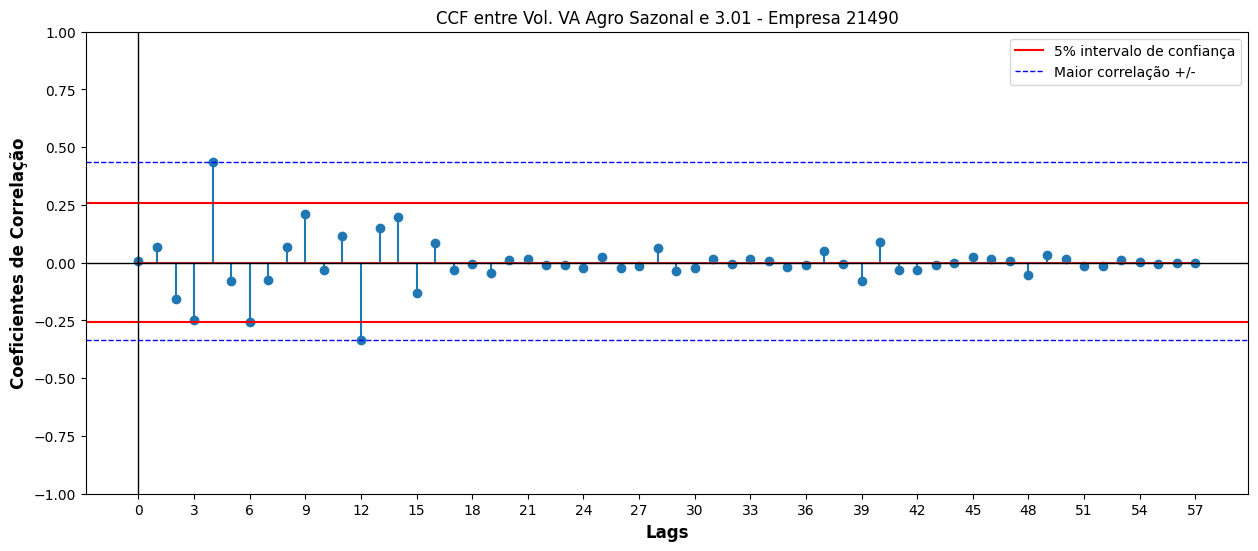

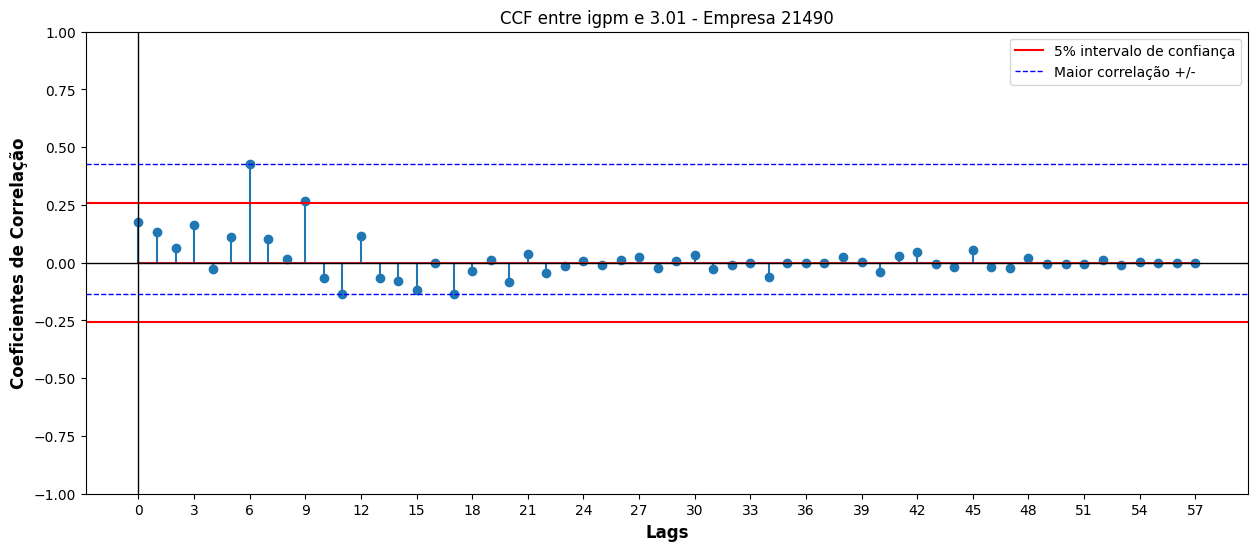

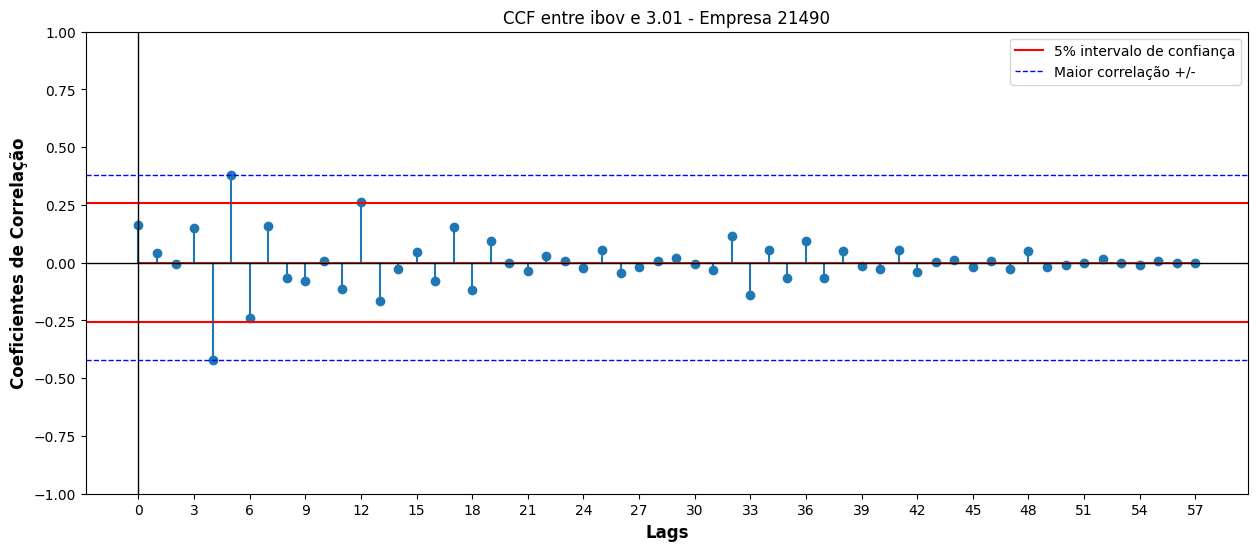

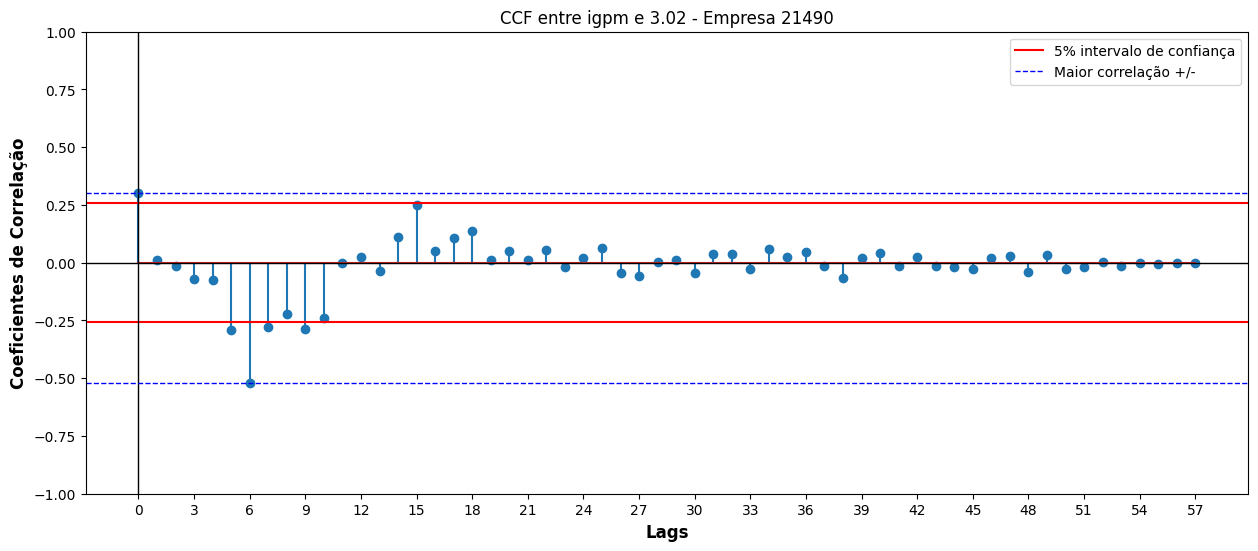

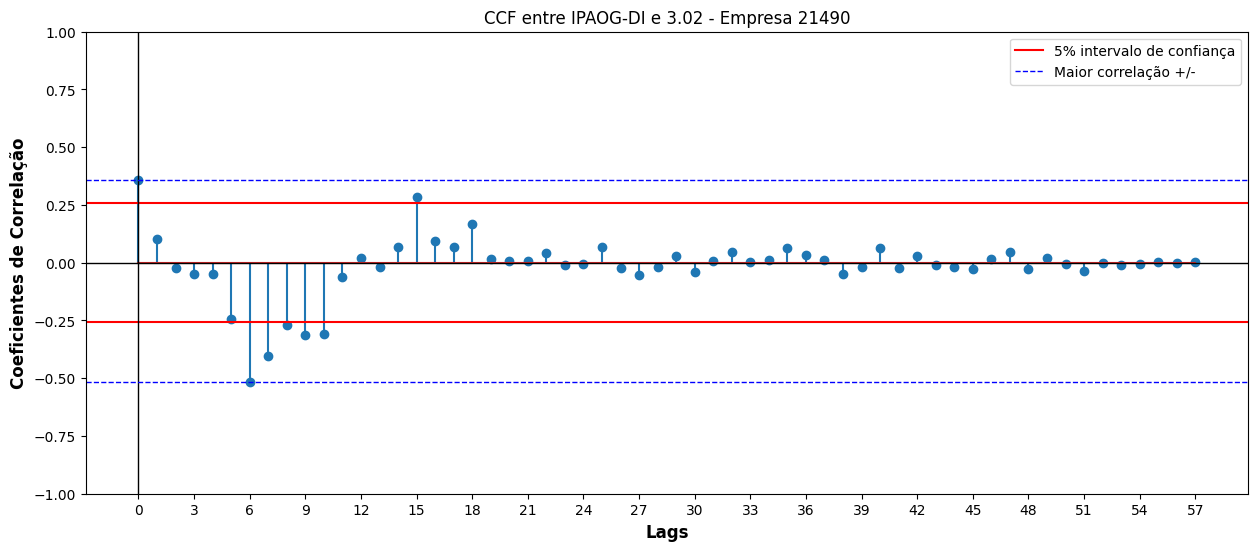

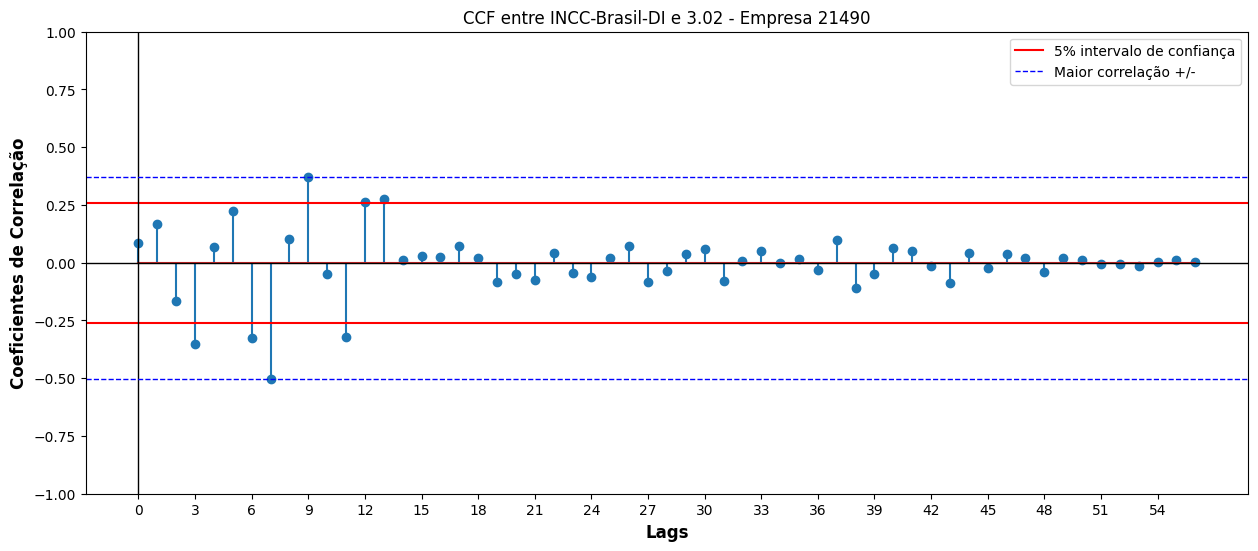

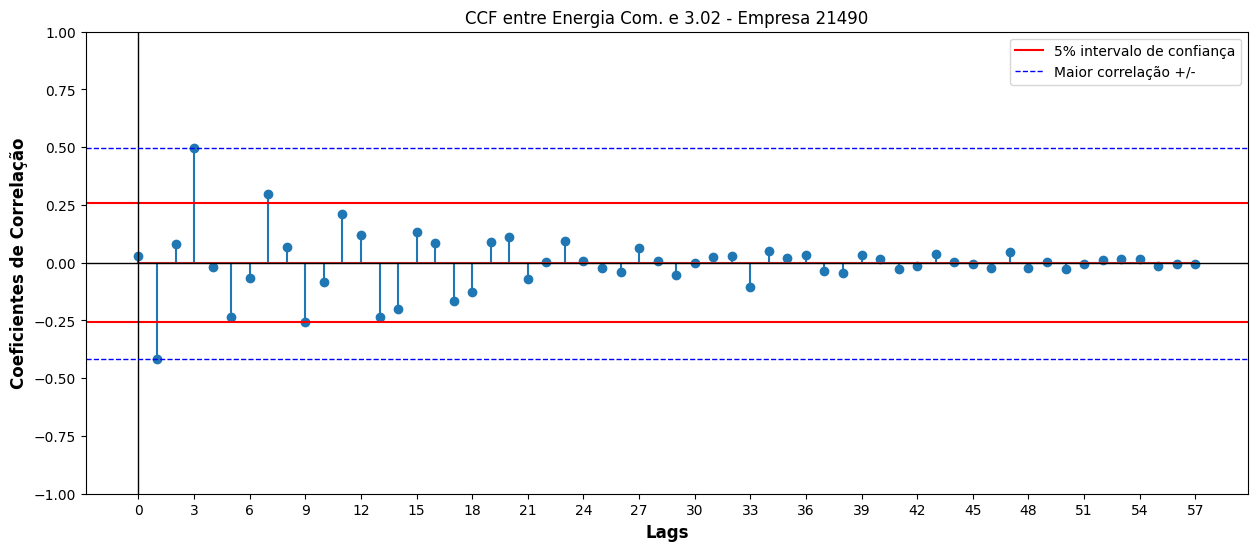

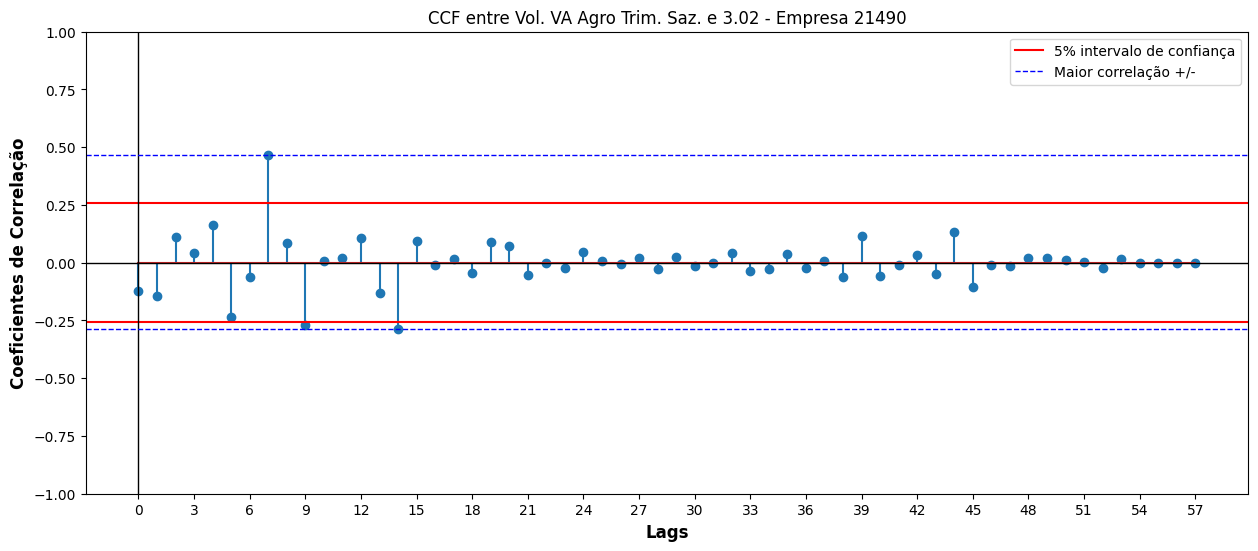

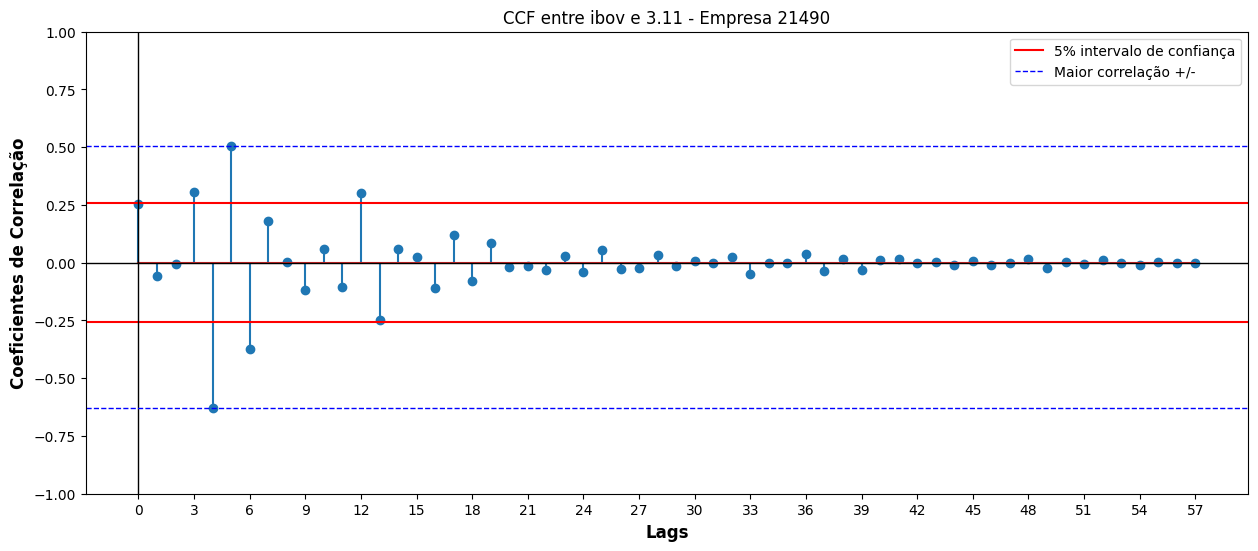

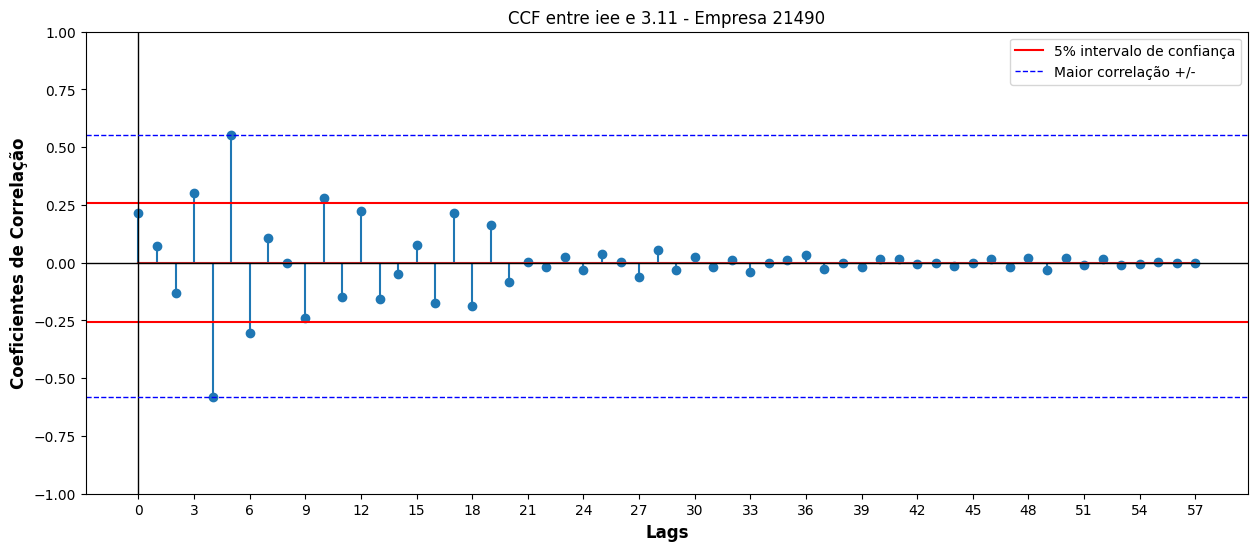

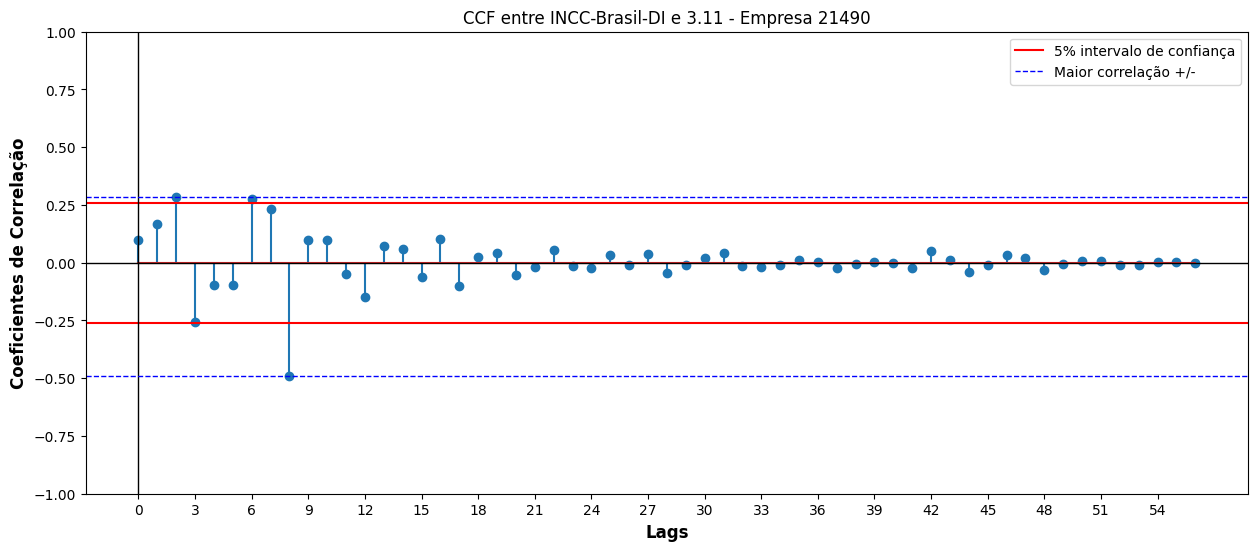

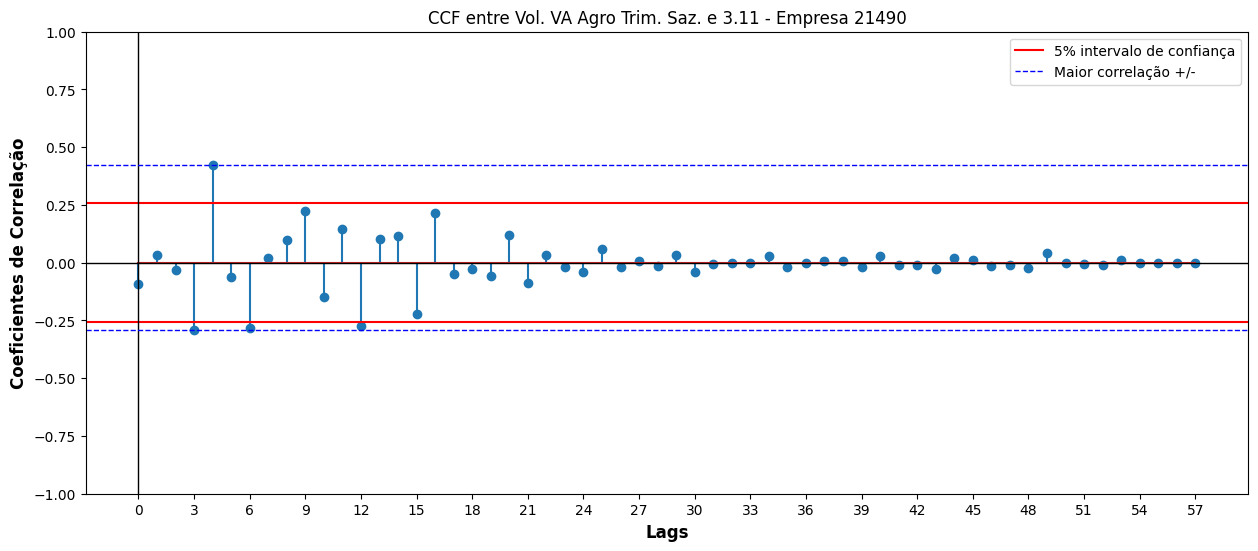

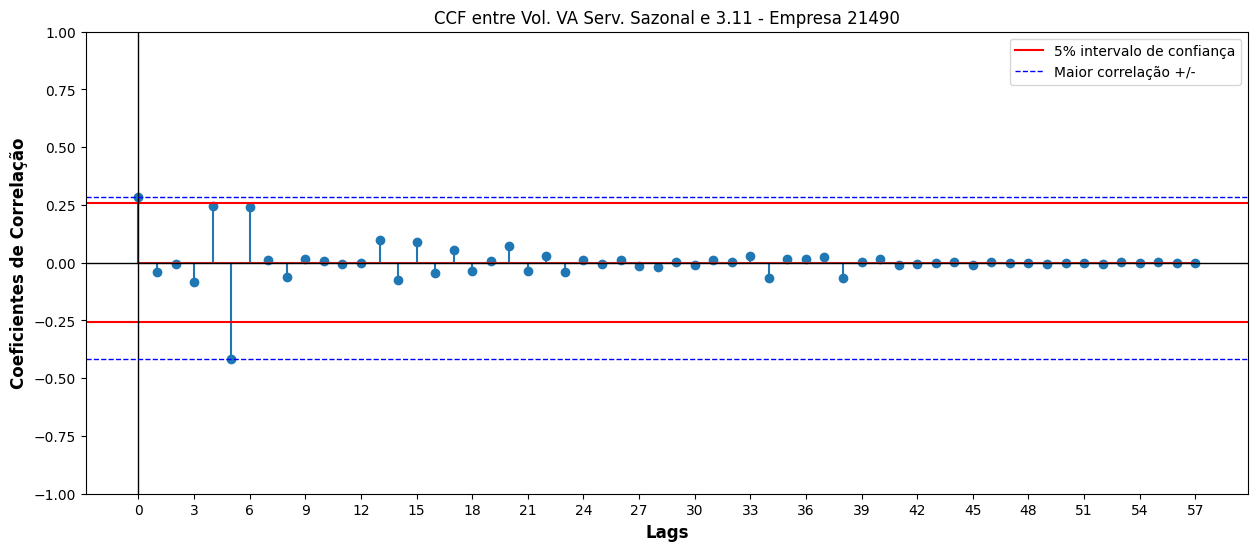

In [22]:
# Plotar Top 5 por (Empresa, Indicador) com base em ranked_pairs
top_n = 5
alvo_indicadores = ['3.01', '3.02', '3.11']  # opcional: filtre apenas os indicadores-alvo

rp = ranked_pairs.copy()
if 'Indicador' in rp.columns and alvo_indicadores:
    rp = rp[rp['Indicador'].isin(alvo_indicadores)]

for (empresa, indicador), df_group in rp.groupby(['Empresa', 'Indicador']):
    df_top = df_group.sort_values('Abs_CCF', ascending=False).head(top_n)
    for _, row in df_top.iterrows():
        indice = row['Indice']
        key = (empresa, indice, indicador)
        corr = ccf_dict.get(key)
        if corr is None:
            # chave inexistente no dicionário (pode ocorrer por nomes/filtragens)
            continue
        lags = np.arange(len(corr))
        plot_ccf(lags, corr, indice=indice, col=indicador, empresa=empresa)

In [23]:
dict_indicadores.keys()

dict_keys([2437, 18376, 20257, 21490])

Montando dataframes de indicadores específicos

In [52]:
def criar_dataframe_indicador(df, coluna_valor):
    """
    Cria um dataframe pivotado onde a coluna 'DT_FIM_EXERC' é o índice
    e cada coluna corresponde ao valor da coluna especificada (coluna_valor)
    de cada empresa (CD_CVM).

    Parâmetros:
      df: DataFrame original com as colunas 'CD_CVM', 'DT_FIM_EXERC' e a coluna desejada.
      coluna_valor: Nome da coluna que será utilizada para os valores (ex.: 'Resultado Bruto').

    Retorna:
      Um DataFrame pivotado.
    """
    resultado = pd.DataFrame()
    for cd_cvm in df['CD_CVM'].unique():
        df_temp = df.loc[df['CD_CVM'] == cd_cvm, ['DT_FIM_EXERC', coluna_valor]].copy()
        df_temp = df_temp.rename(columns={coluna_valor: cd_cvm})
        df_temp = df_temp.set_index('DT_FIM_EXERC')
        if resultado.empty:
            resultado = df_temp.copy()
        else:
            resultado = resultado.join(df_temp, how='outer')

    # Preencher valores NaN com 0
    resultado.fillna(0, inplace=True)
    
    return resultado

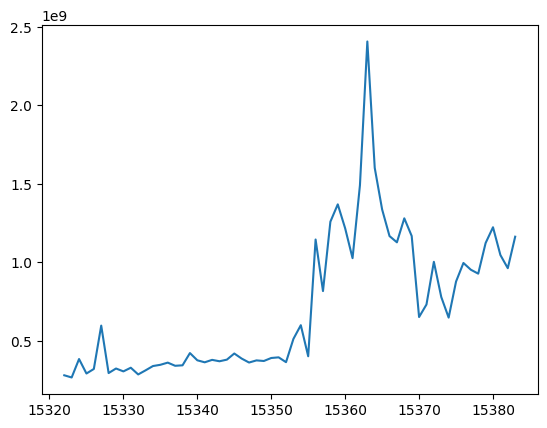

In [53]:
plt.plot(dados_indicadores.query("CD_CVM == 21490")['3.01'])

In [54]:
resultado_bruto = criar_dataframe_indicador(dados_indicadores_transm, '3.01')
lucro_consolidado = criar_dataframe_indicador(dados_indicadores_transm, '3.11')
despesas_operacionais = criar_dataframe_indicador(dados_indicadores_transm, '3.04')

In [55]:
dados_indicadores_transm['CD_CVM'].unique()

array([ 2437, 18376, 20257, 21490], dtype=int64)

Teste de estacionariedade KPSS
-   **Hipótese Nula (H0)**: A série é estacionária.
-   **Hipótese Alternativa (Ha)**: A série não é estacionária.

Teste de estacionariedade ADF
-   **Hipótese Nula (H0)**: A série não é estacionária.
-   **Hipótese Alternativa (Ha)**: A série é estacionária.

obs: utilizando dois métodos distintos para confirmar a estacionariedade

In [56]:
def teste_dados_estacionarios(series):
    dados_estacionarios_kpss = {}
    dados_estacionarios_adf = {}
    for cd_cvm, serie in series.items():
        print(cd_cvm)
        kpss_stat, p_value, lags, critical_values = kpss(serie)
        
        print(f'Estatística do teste: {kpss_stat:.4f}')
        print(f'p-valor: {p_value:.4f}')
        print('Valores Críticos:')
        for key, value in critical_values.items():
            print(f'{key}: {value:.4f}')
        print('Resultado:')
        if p_value > 0.05:
            #dados_estacionarios_kpss[cd_cvm] = p_value
            dados_estacionarios_kpss[cd_cvm] = 'S'
        else:
            #dados_estacionarios_kpss[cd_cvm] = p_value
            dados_estacionarios_kpss[cd_cvm] = 'N'

        adf_result = adfuller(serie)

        print('ADF Statistic: %f' % adf_result[0])
        print('p-value: %f' % adf_result[1])
        # Inspeciona valores críticos
        for key, value in adf_result[4].items():
            print(f'Critical Value ({key}): {value:.4f}')

        if adf_result[1] < 0.05:
            #dados_estacionarios_adf[cd_cvm] = adf_result[1]
            dados_estacionarios_adf[cd_cvm] = 'N'
        else:
            dados_estacionarios_adf[cd_cvm] = 'S'

        df_dados_estacionarios_KPSS = pd.DataFrame.from_dict(dados_estacionarios_kpss, orient='index', columns=['KPSS'])
        df_dados_estacionarios_ADF = pd.DataFrame.from_dict(dados_estacionarios_adf, orient='index', columns=['ADF'])
        
    return df_dados_estacionarios_KPSS.join(df_dados_estacionarios_ADF)


In [57]:
resultado_bruto_estacionariedade = teste_dados_estacionarios(resultado_bruto.copy())
lucro_consolidado_estacionariedade = teste_dados_estacionarios(lucro_consolidado.copy())
despesas_operacionais_estacionariedade = teste_dados_estacionarios(despesas_operacionais.copy())

2437
Estatística do teste: 0.1048
p-valor: 0.1000
Valores Críticos:
10%: 0.3470
5%: 0.4630
2.5%: 0.5740
1%: 0.7390
Resultado:
ADF Statistic: -7.514522
p-value: 0.000000
Critical Value (1%): -3.5387
Critical Value (5%): -2.9086
Critical Value (10%): -2.5919
18376
Estatística do teste: 0.9992
p-valor: 0.0100
Valores Críticos:
10%: 0.3470
5%: 0.4630
2.5%: 0.5740
1%: 0.7390
Resultado:
ADF Statistic: -5.884162
p-value: 0.000000
Critical Value (1%): -3.5387
Critical Value (5%): -2.9086
Critical Value (10%): -2.5919
20257
Estatística do teste: 1.1348
p-valor: 0.0100
Valores Críticos:
10%: 0.3470
5%: 0.4630
2.5%: 0.5740
1%: 0.7390
Resultado:
ADF Statistic: -0.326178
p-value: 0.921714
Critical Value (1%): -3.5424
Critical Value (5%): -2.9102
Critical Value (10%): -2.5927
21490
Estatística do teste: 0.9418
p-valor: 0.0100
Valores Críticos:
10%: 0.3470
5%: 0.4630
2.5%: 0.5740
1%: 0.7390
Resultado:
ADF Statistic: -1.358639
p-value: 0.601937
Critical Value (1%): -3.5424
Critical Value (5%): -2.9102

Armazenar valor do componente de integração para cada série temporal

In [58]:
def nivel_integracao(series):

    integration_level = {}  # Will store the integration order for each series
    series_corrigido = pd.DataFrame()

    for col in series.columns:
        serie = series[col]
        
        # Apply first-order differencing
        diff1 = serie.diff().dropna()
        adf_result1 = adfuller(diff1)
        
        if adf_result1[1] < 0.05:
            integration_level[col] = 1  # Series became stationary after 1st diff.
            series[col] = diff1
            print(f'{col}: Estacionário depois da primeira diferenciação (I=1)')
        else:
            # Aplicar diferenciação de segunda ordem
            diff2 = diff1.diff().dropna()
            adf_result2 = adfuller(diff2)
            integration_level[col] = 2  # Even after 1st diff, not stationary; use 2nd diff.
            series[col] = diff2
            print(f'{col}: Estaionário depois da segunda diferenciação (I=2) -- p-value: {adf_result2[1]:.4f}')

    print("\nIntegration levels:", integration_level)
    df_integration_level = pd.DataFrame.from_dict(integration_level, orient='index', columns=['Integration Level'])
    return df_integration_level

In [59]:
nivel_int_resultado_bruto = nivel_integracao(resultado_bruto.copy())
nivel_int_lucro_consolidado = nivel_integracao(lucro_consolidado.copy())
nivel_int_despesas_operacionais = nivel_integracao(despesas_operacionais.copy())

2437: Estacionário depois da primeira diferenciação (I=1)
18376: Estacionário depois da primeira diferenciação (I=1)
20257: Estacionário depois da primeira diferenciação (I=1)
21490: Estacionário depois da primeira diferenciação (I=1)

Integration levels: {2437: 1, 18376: 1, 20257: 1, 21490: 1}
2437: Estacionário depois da primeira diferenciação (I=1)
18376: Estacionário depois da primeira diferenciação (I=1)
20257: Estacionário depois da primeira diferenciação (I=1)
21490: Estacionário depois da primeira diferenciação (I=1)

Integration levels: {2437: 1, 18376: 1, 20257: 1, 21490: 1}
2437: Estacionário depois da primeira diferenciação (I=1)
18376: Estacionário depois da primeira diferenciação (I=1)
20257: Estacionário depois da primeira diferenciação (I=1)
21490: Estaionário depois da segunda diferenciação (I=2) -- p-value: 0.0000

Integration levels: {2437: 1, 18376: 1, 20257: 1, 21490: 2}


Analise ACF e PACF para séries estacionárias - fluxo para dados estacionarios

Algoritmo

In [32]:
# Função auxiliar para determinar o maior lag significativo
def obter_ordem(values, confint):
    ordem = 0
    for lag in range(1, len(values)):  # Ignora lag 0
        print(values)
        print(f'Lag {lag}: {values[lag]}, {confint[lag]}')
        if (values[lag] < confint[lag][0]) or (values[lag] > confint[lag][1]):
            ordem = lag
        else:
            # Se o primeiro não significativo aparecer, interrompe
            break
    return ordem

In [33]:
def analisar_componentes_arima(serie, nlags=10, alpha=0.05):
    """
    Analisa os componentes AR e MA de uma série temporal.

    Parâmetros:
    - serie: pandas Series ou array-like com a série temporal estacionária.
    - nlags: número de lags para avaliar.
    - alpha: nível de significância (default = 5%).

    Retorna:
    - Um dicionário com a conclusão sobre os componentes AR (p) e MA (q).
    """
    N = len(serie)
    z = norm.ppf(1 - alpha/2)  # por exemplo, 1.96 para 95% de confiança
    
    # Inicializa o array dos intervalos de confiança
    ci_acf = np.zeros((nlags+1, 2))
    ci_pacf = np.zeros((nlags+1, 2))

    # Para o lag zero, o ACF é 1 e não calculamos intervalo (ou pode ser [0,0])
    ci_acf[0] = [0, 0]
    ci_pacf[0] = [0, 0]

    # Calcular ACF e PACF com intervalos de confiança
    acf_values, acf_interval = acf(serie, nlags=nlags, alpha=alpha)
    # Calcular ACF e PACF com intervalos de confiança
    pacf_values, pacf_interval= pacf(serie, nlags=nlags, alpha=alpha)

        # Calcula os intervalos para cada lag > 0 usando a fórmula de Bartlett
    for k in range(1, nlags+1):
        var = (1.0 / N) * (1 + 2 * np.sum( acf_values[1:k]**2 ))
        margin = z * np.sqrt(var)
        ci_acf[k] = [-margin, margin]

    # Calcula os intervalos para cada lag > 0 usando a fórmula de Bartlett
    for k in range(1, nlags+1):
        var = (1.0 / N) * (1 + 2 * np.sum( pacf_values[1:k]**2 ))
        margin = z * np.sqrt(var)
        ci_pacf[k] = [-margin, margin]

    # Determinar p e q
    #print("Valores ACF:", acf_values)
    #print("Valores PACF:", pacf_values)
    #print("Intervalos de Confiança ACF:", ci_acf)
#print("Intervalos de Confiança PACF:", ci_pacf)
    p = obter_ordem(pacf_values, ci_pacf)
    q = obter_ordem(acf_values, ci_acf)

    # Construir conclusão
    conclusao = {
        'AR (p)': p,
        'MA (q)': q,
        'Interpretacao': f"O modelo sugerido é ARIMA({p}, d, {q}), onde d é definido pela análise de estacionariedade."
    }
    return p, q, conclusao


Montando variações de ARIMA para cada empresa

In [34]:
def componentes_arima(serie_temporal, nivel_int_serie):
    resultados = []

    for cd_cvm, series in serie_temporal.items():
        p,q, retorno = analisar_componentes_arima(series)
       # print(f'CD_CVM: {cd_cvm}')
       # print(f'AR(p): {p}, MA(q): {q}')
        serie_temporal_arima_dict = {}
        serie_temporal_arima_dict['CD_CVM'] = cd_cvm
        
        serie_temporal_arima = pd.DataFrame()
        if p == 0 and q == 0:
            #print('Setando p=1 para existir pelo menos um modelo AR')
            p = 1 
            q = 1
        resultados.append({
            'CD_CVM': cd_cvm,
            'AR(p)': p,
            'MA(q)': q
        })

    df_componentes = pd.DataFrame(resultados).set_index('CD_CVM')

    #Juntando componente integrativo com os componentes AR e MA
    df_componentes_arima = pd.concat([nivel_int_serie, df_componentes], axis=1)
    df_componentes_arima.columns = ['I(d)', 'AR(p)', 'MA(q)']
    df_componentes_arima.fillna(0, inplace=True)
    df_componentes_arima['I(d)'] = df_componentes_arima['I(d)'].astype(int)
    print(df_componentes_arima)
    return df_componentes_arima

In [35]:
def gera_modelo_arima(serie_temporal, df_componentes):
    # Dicionário para armazenar os modelos ajustados para cada CD_CVM
    modelos_arima = {}

    for cd_cvm in df_componentes.index:
        # Split dos dados em treino/validação e teste
        n = len(serie_temporal)
        split_point = int(n * 0.8) 

        p = df_componentes.loc[cd_cvm, 'AR(p)']
        q = df_componentes.loc[cd_cvm, 'MA(q)']
        i = df_componentes.loc[cd_cvm, 'I(d)']
        # Como as séries já são estacionárias, definimos d = 0
        order = (p, i, q)

        serie = serie_temporal[cd_cvm].iloc[:split_point]
        
        try:
            modelo = ARIMA(serie, order=order).fit()
            modelos_arima[cd_cvm] = modelo
            print(f'Modelo ARIMA({p}, {i}, {q}) para CD_CVM {cd_cvm} ajustado com sucesso.')
            print(modelo.summary())
        except Exception as e:
            print(f'Erro ao ajustar modelo para CD_CVM {cd_cvm}: {str(e)}')

    return modelos_arima

In [36]:
def adicionar_lags(df, lags=4):
    frames = df.copy()  # copia do DataFrame original
    for lag in range(1, lags + 1):
        lagged = df.shift(lag).copy()
        lagged.columns = [f"{col}_lag{lag}" for col in df.columns]
        frames = pd.concat([frames, lagged], axis=1)
    return frames

In [37]:
resultado_bruto_comp_arima = componentes_arima(resultado_bruto[1:].copy(), nivel_int_resultado_bruto)
lucro_consolidado_comp_arima = componentes_arima(lucro_consolidado[1:].copy(), nivel_int_lucro_consolidado)
despesas_operacionais_comp_arima = componentes_arima(despesas_operacionais[1:].copy(), nivel_int_despesas_operacionais)

[ 1.00000000e+00  1.50487446e-02  4.98431606e-02  1.07052893e-02
 -9.98556152e-03  9.30974241e-03  2.16145315e-04 -5.20857070e-02
  1.20901951e-01 -5.54338793e-02 -5.32139665e-01]
Lag 1: 0.015048744632002486, [-0.25735588  0.25735588]
[ 1.00000000e+00  1.47892835e-02  4.83321880e-02  1.15140792e-02
 -6.64918315e-03  9.30727380e-03 -2.15358677e-04 -4.49767241e-02
  1.02638678e-01 -4.69542534e-02 -4.23085954e-01]
Lag 1: 0.014789283517657596, [-0.25735588  0.25735588]
[ 1.          0.11181592  0.07114882  0.12028897  0.10383499  0.0234324
  0.00609341  0.02478777  0.09044061  0.03754183 -0.01316572]
Lag 1: 0.11181592231655012, [-0.25735588  0.25735588]
[1.         0.10988806 0.0799082  0.12776593 0.1226049  0.05590485
 0.03863535 0.05342821 0.10261865 0.05992978 0.01838057]
Lag 1: 0.10988806158695445, [-0.25735588  0.25735588]
[ 1.          0.71027778  0.34449769  0.24211153 -0.07776197 -0.2278558
  0.09592761 -0.01150999  0.29710164  0.05964667 -0.07020413]
Lag 1: 0.7102777779084878, [-0

In [38]:
result_bruto_arima = gera_modelo_arima(resultado_bruto, resultado_bruto_comp_arima)
lucro_consolidado_arima = gera_modelo_arima(lucro_consolidado, lucro_consolidado_comp_arima)
despesas_operacionais_arima = gera_modelo_arima(despesas_operacionais, despesas_operacionais_comp_arima)

Modelo ARIMA(1, 1, 1) para CD_CVM 2437 ajustado com sucesso.
                               SARIMAX Results                                
Dep. Variable:                   2437   No. Observations:                   47
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1090.851
Date:                Sun, 05 Oct 2025   AIC                           2187.701
Time:                        13:19:10   BIC                           2193.187
Sample:                    03-31-2010   HQIC                          2189.757
                         - 09-30-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0543      0.456      0.119      0.905      -0.840       0.948
ma.L1         -0.9672      0.107     -9.033      0.000      -1.177    

In [39]:
resultado_bruto.columns

Index([2437, 18376, 20257, 21490], dtype='int64')

In [40]:
def walk_forward_arima(serie, ordem_arima, n_splits=8):

    # Configurando o TimeSeriesSplit
    # Vamos dividir os dados em 8 janelas de teste. A janela de treino irá crescer a cada passo.
    tscv = TimeSeriesSplit(n_splits=n_splits)

    # Listas para armazenar os resultados de cada dobra da validação
    valores_reais = []
    previsoes = []

    print("Iniciando a validação Walk-Forward...")
    # --- 3. O Loop de Validação Walk-Forward ---
    # O tscv.split(serie) gera os índices de treino e teste para cada dobra
    for i, (train_index, test_index) in enumerate(tscv.split(serie)):
        print(f"--- Dobra {i+1}/{n_splits} ---")
        
        # 1. Separar os dados de treino e teste da dobra atual
        treino = serie.iloc[train_index]
        teste = serie.iloc[test_index]
        print(f"Tamanho do Treino: {len(treino)}, Tamanho do Teste: {len(teste)}")
        
        # 2. Treinar o modelo ARIMA APENAS com os dados de treino
        # O modelo é retreinado a cada passo com mais dados, simulando a realidade
        modelo = sm.tsa.ARIMA(treino, order=ordem_arima, )
        modelo_ajustado = modelo.fit()
        
        # 3. Fazer a previsão para o período de teste
        # O número de passos da previsão é o tamanho do conjunto de teste
        previsao = modelo_ajustado.forecast(steps=len(teste))
        
        # 4. Guardar os resultados
        previsoes.extend(previsao)
        valores_reais.extend(teste)

    print("\nValidação Walk-Forward concluída.")

    # --- 4. Avaliação e Visualização dos Resultados ---

    # Calcular a métrica de erro final sobre todos os pontos previstos
    rmse_final = np.sqrt(mean_squared_error(valores_reais, previsoes))
    print(f"\nRMSE Final (out-of-sample): {rmse_final:.4f}")

    # Criar um DataFrame com os resultados para facilitar a visualização
    df_resultados = pd.DataFrame({
        'Real': valores_reais,
        'Previsao': previsoes
    }, index=serie.index[-len(valores_reais):]) # Garante que o índice de datas está correto

    # Plotar os resultados
    plt.figure(figsize=(14, 7))
    plt.plot(serie, label='Série Original Completa', color='gray')
    plt.plot(df_resultados['Real'], label='Valores Reais (Teste)', color='blue', marker='o', linestyle='None')
    plt.plot(df_resultados['Previsao'], label='Previsões Walk-Forward', color='red', linestyle='--')
    plt.title('Validação Walk-Forward - Previsões vs. Real', fontsize=16)
    plt.xlabel('Data')
    plt.ylabel('Valor')
    plt.legend()
    plt.grid(True)
    plt.show()

In [41]:
def walk_forward_arima_one_step(serie, ordem_arima, tamanho_treino_inicial, input_exog=None):
    """
    Realiza a validação walk-forward prevendo apenas um passo à frente por vez.

    Parâmetros:
    - serie: A série temporal completa (Pandas Series).
    - ordem_arima: A ordem (p, d, q) do modelo ARIMA.
    - tamanho_treino_inicial: O número de observações para o primeiro treino.
    - input_exog: DataFrame com as variáveis exógenas.
    """
    # Listas para armazenar os resultados
    valores_reais = []
    previsoes = []
    
    # O número total de previsões que faremos
    n_previsoes = len(serie) - tamanho_treino_inicial

    print(f"Iniciando a validação Walk-Forward (One-Step-Ahead)...")
    print(f"Tamanho do treino inicial: {tamanho_treino_inicial}, Número de previsões a fazer: {n_previsoes}")

    # --- O Novo Loop de Validação ---
    # Este loop itera para cada ponto que queremos prever
    for i in range(n_previsoes):
        # O índice do ponto atual no DataFrame original
        indice_atual = tamanho_treino_inicial + i
        
        # 1. Separar os dados de treino
        # O treino contém todos os dados até o ponto ANTERIOR ao que queremos prever
        treino = serie.iloc[:indice_atual]
        #treino_exog = input_exog.iloc[:indice_atual]
        
        # O valor real é o ponto exato que estamos tentando prever
        valor_real = serie.iloc[indice_atual]
        
        # A variável exógena para a previsão precisa ser a do momento da previsão
        #teste_exog = input_exog.iloc[indice_atual:indice_atual+1]

        # Imprimir progresso para não parecer que travou (este processo é lento)
        if (i + 1) % 10 == 0 or (i + 1) == n_previsoes:
             print(f"--- Prevendo passo {i+1}/{n_previsoes} (Treinando com {len(treino)} observações) ---")
        
        # 2. Treinar o modelo ARIMA com a janela de treino atual
        modelo = sm.tsa.ARIMA(treino, order=ordem_arima, exog=None)
        modelo_ajustado = modelo.fit()
        
        # 3. Fazer a previsão de APENAS UM PASSO à frente
        previsao = modelo_ajustado.forecast(steps=1, exog=None)
        
        # 4. Guardar os resultados
        previsoes.append(previsao.iloc[0]) # .iloc[0] para pegar o valor escalar da previsão
        valores_reais.append(valor_real)

    print("\nValidação Walk-Forward concluída.")
    
    # O restante do código para avaliação e plotagem permanece o mesmo
    rmse_final = np.sqrt(mean_squared_error(valores_reais, previsoes))
    print(f"RMSE Final (out-of-sample): {rmse_final:.4f}")

    df_resultados = pd.DataFrame({
        'Real': valores_reais,
        'Previsao': previsoes
    }, index=serie.index[-len(valores_reais):])

    plt.figure(figsize=(14, 7))
    plt.plot(serie, label='Série Original Completa', color='gray', alpha=0.6)
    plt.plot(df_resultados['Real'], label='Valores Reais (Teste)', color='blue', marker='o', linestyle='None', markersize=5)
    plt.plot(df_resultados['Previsao'], label='Previsões One-Step-Ahead', color='red', linestyle='--')
    plt.title('Validação Walk-Forward (One-Step-Ahead) - Previsões vs. Real', fontsize=16)
    plt.xlabel('Data')
    plt.ylabel('Valor')
    plt.legend()
    plt.grid(True)
    plt.show()

    return rmse_final, modelo_ajustado


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 4983349626.1717


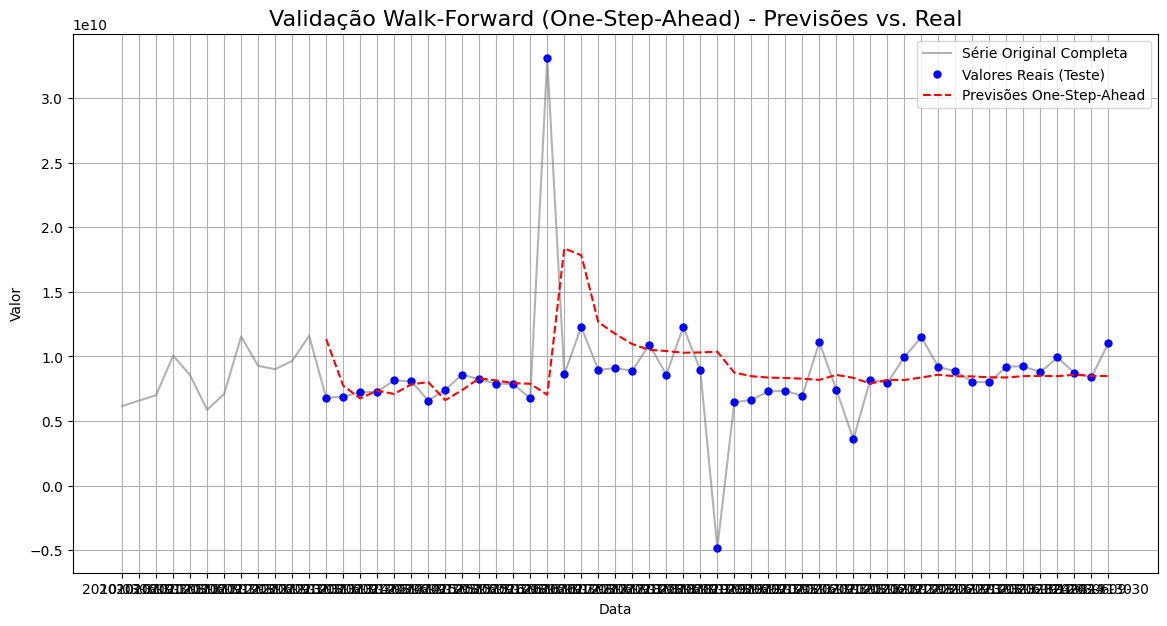


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 1586648485.3615


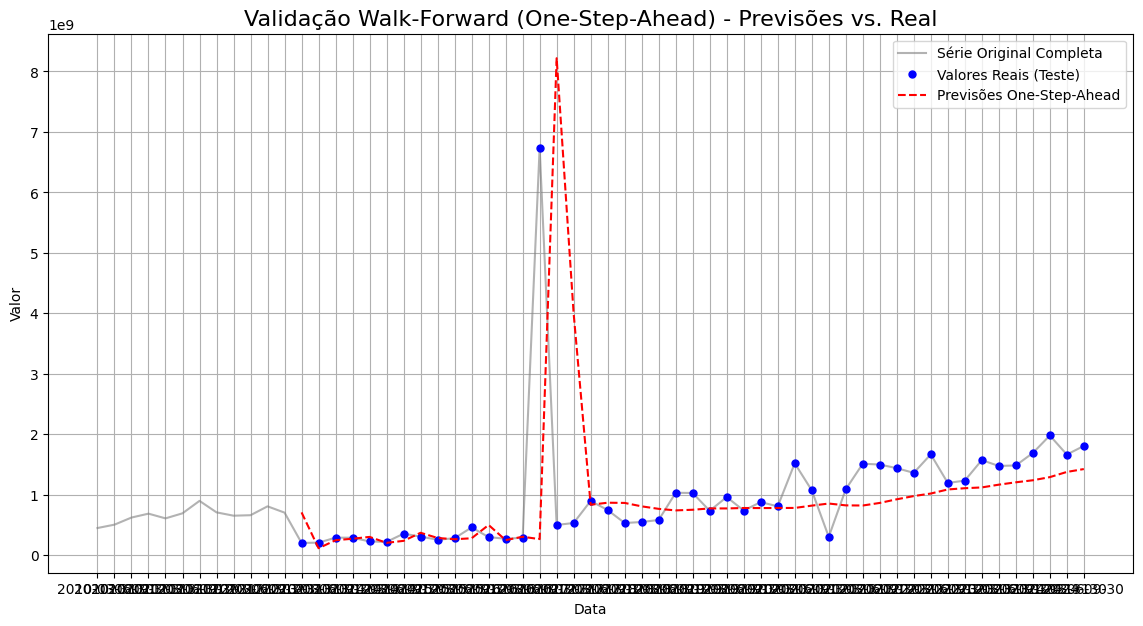


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 213968588.3239


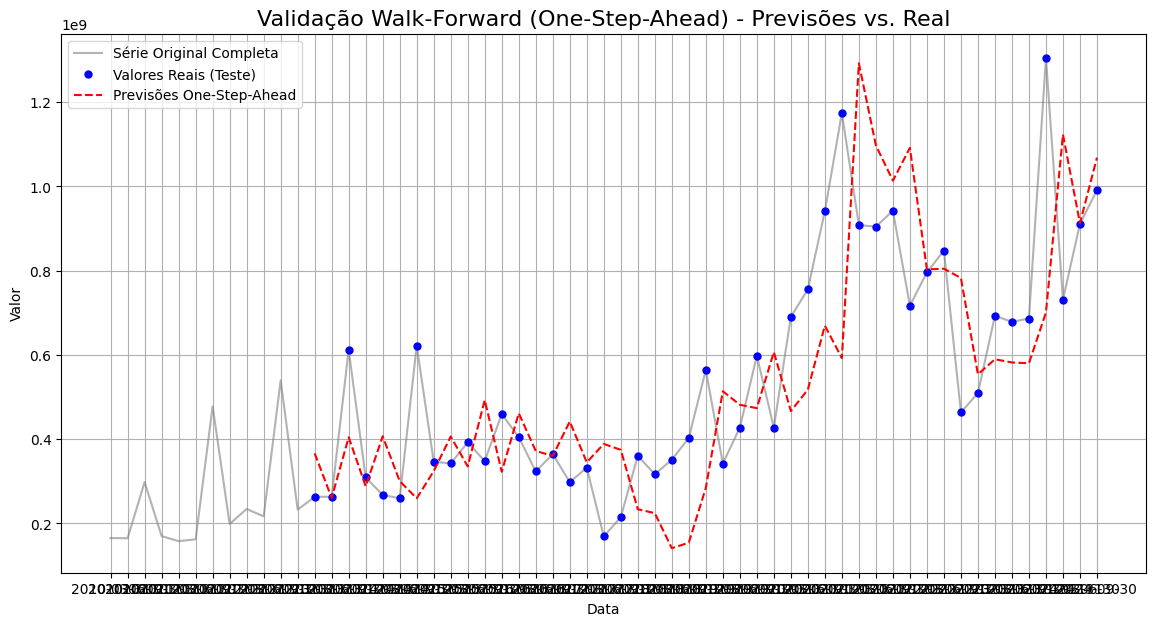


Empresa 21490 - Ordem ARIMA: [1, 1, 5]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 313089879.3195


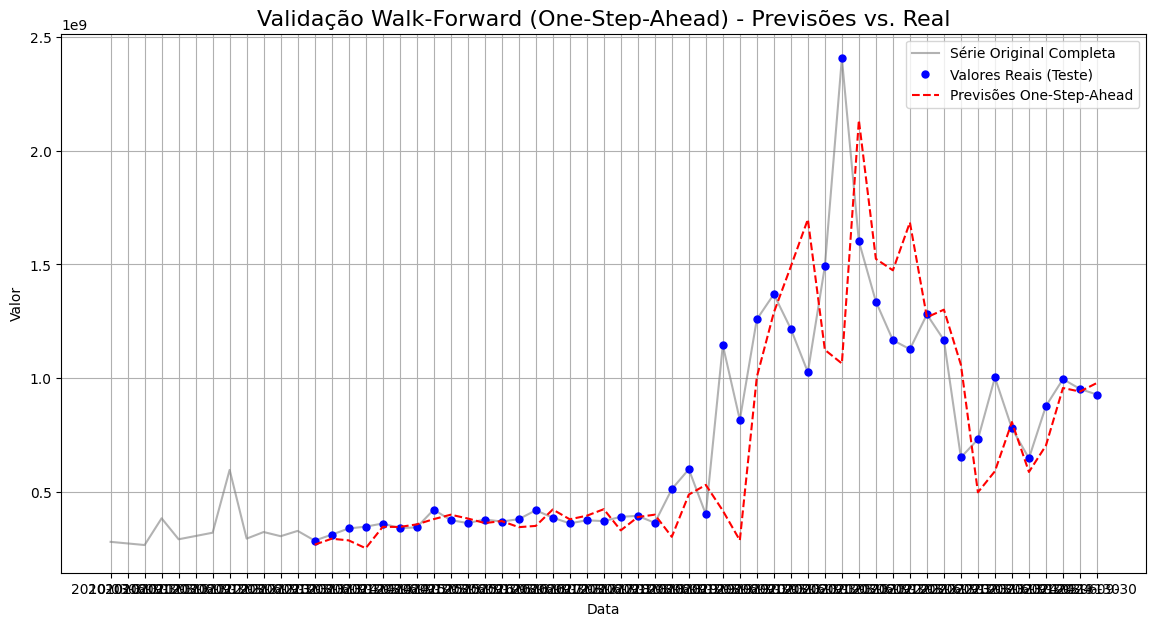

In [42]:
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    walk_forward_arima_one_step(resultado_bruto[empresa], ordem_arima=resultado_bruto_comp_arima.loc[empresa].tolist(), tamanho_treino_inicial=12)

Refina ARIMA


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 4983349626.1717


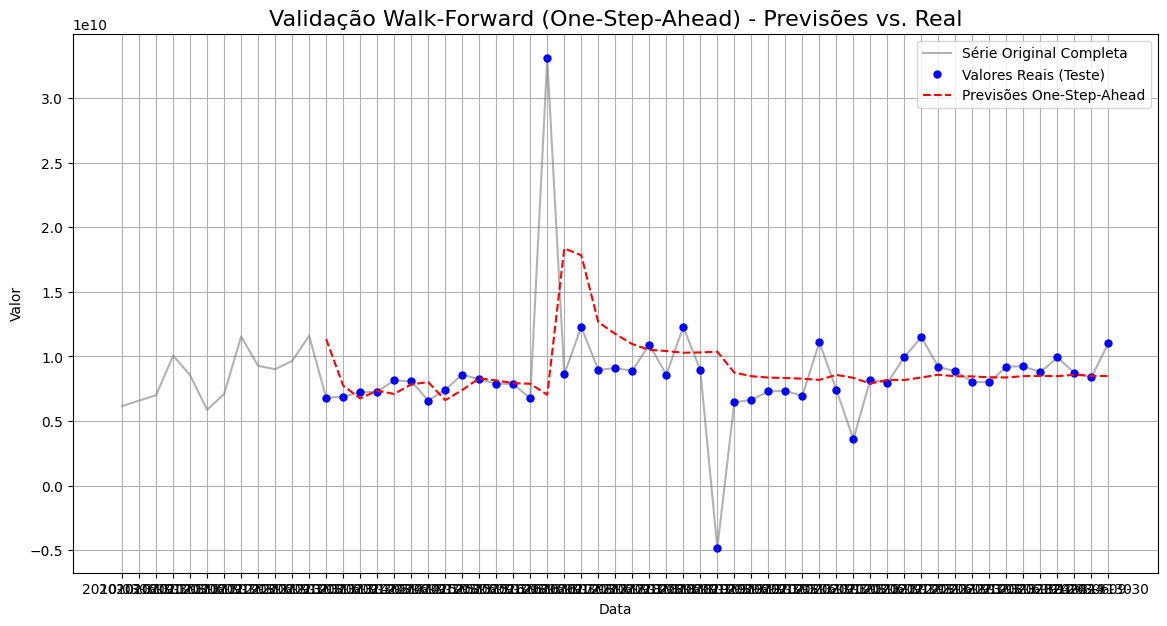


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 1586648485.3615


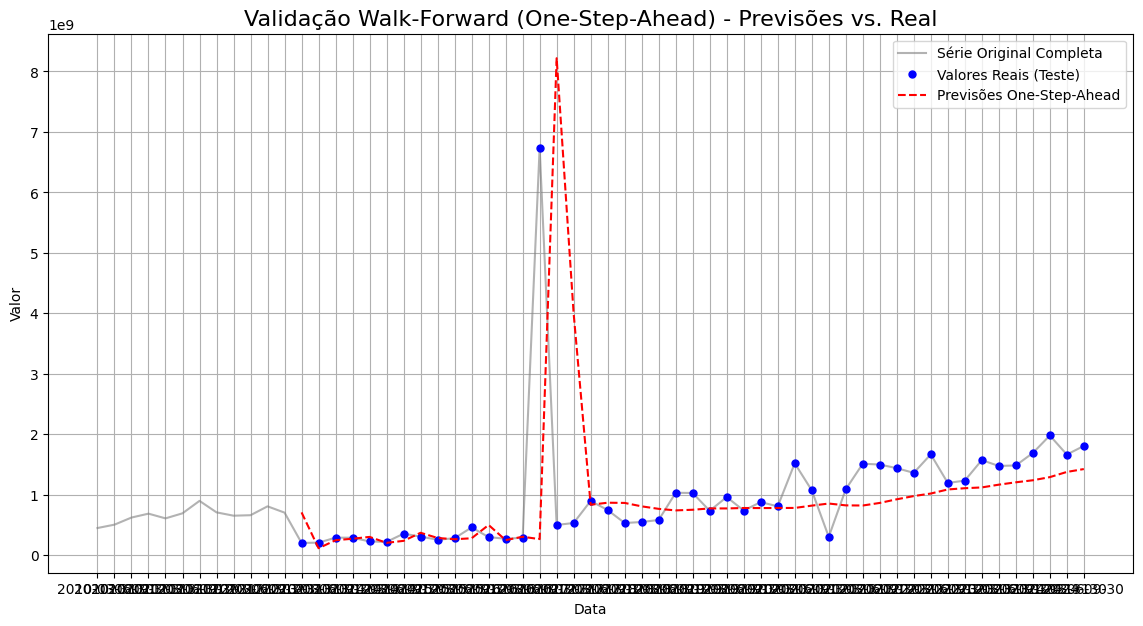


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 213968588.3239


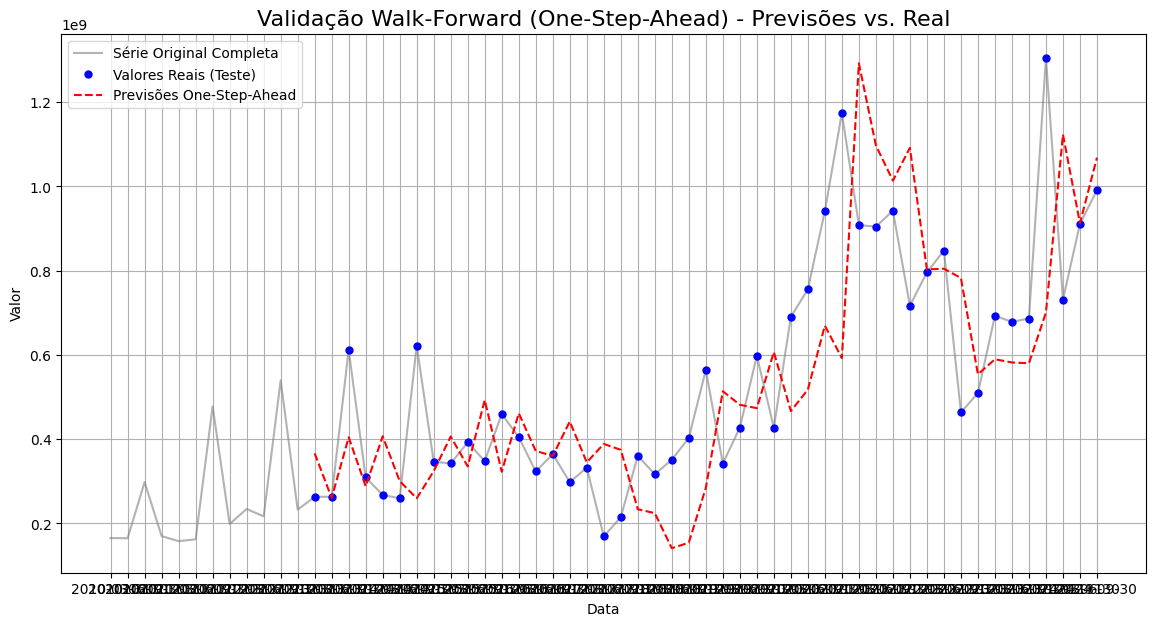


Empresa 21490 - Ordem ARIMA: [1, 1, 5]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 47
--- Prevendo passo 10/47 (Treinando com 21 observações) ---
--- Prevendo passo 20/47 (Treinando com 31 observações) ---
--- Prevendo passo 30/47 (Treinando com 41 observações) ---
--- Prevendo passo 40/47 (Treinando com 51 observações) ---
--- Prevendo passo 47/47 (Treinando com 58 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 313089879.3195


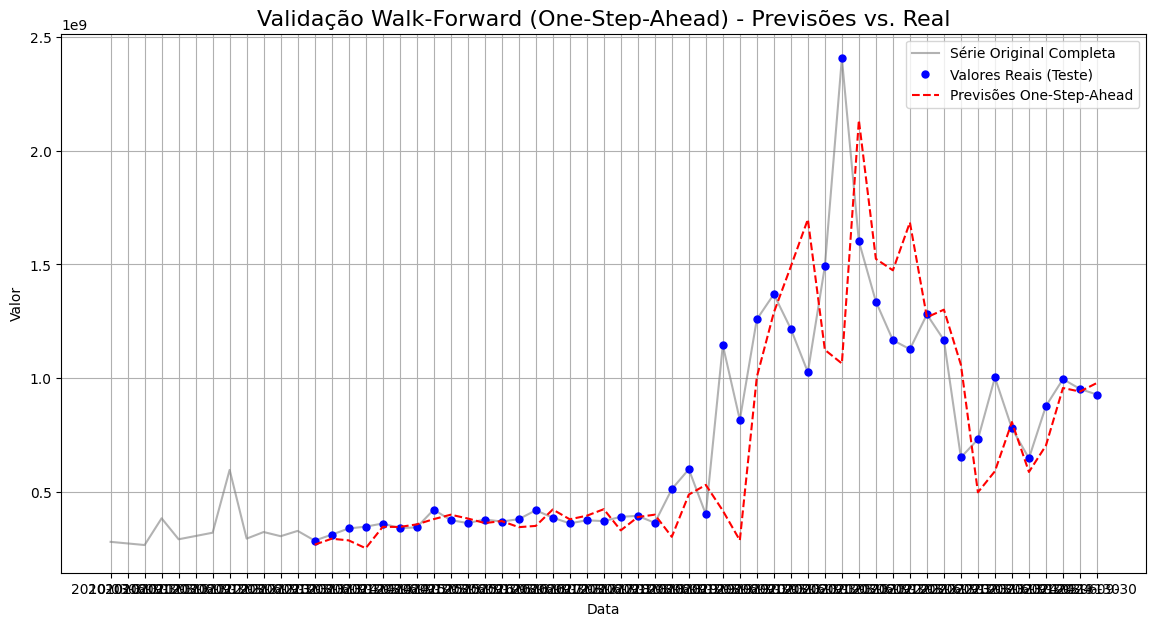

In [44]:
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    walk_forward_arima_one_step(resultado_bruto[empresa], ordem_arima=resultado_bruto_comp_arima.loc[empresa].tolist(), tamanho_treino_inicial=12)


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 4212756529.7746


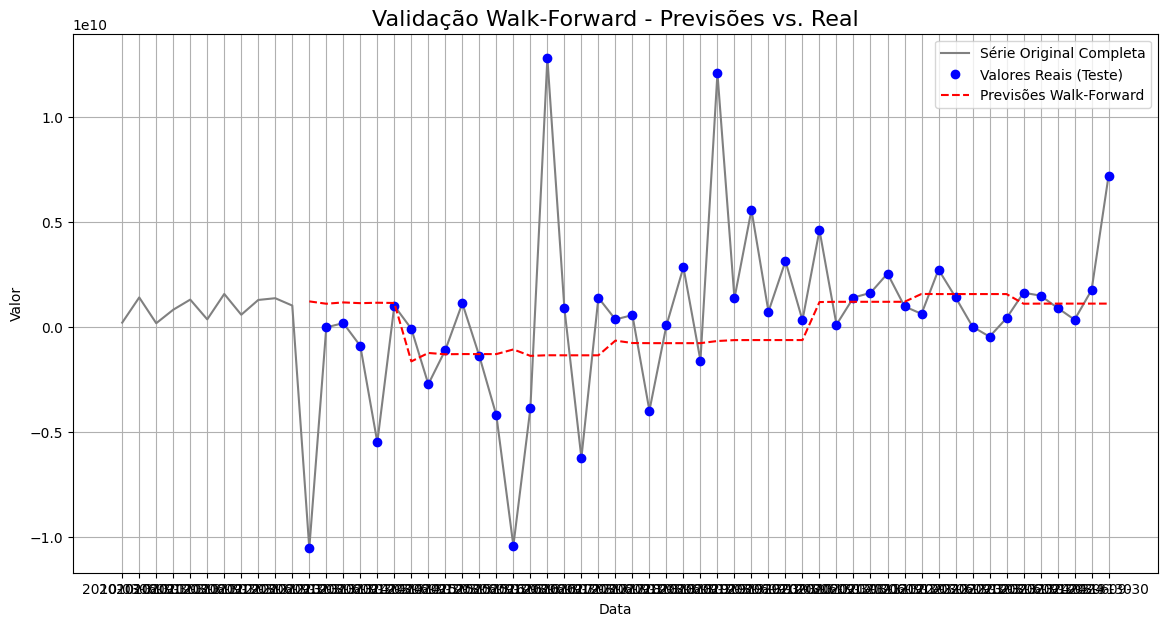


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 682298326.8289


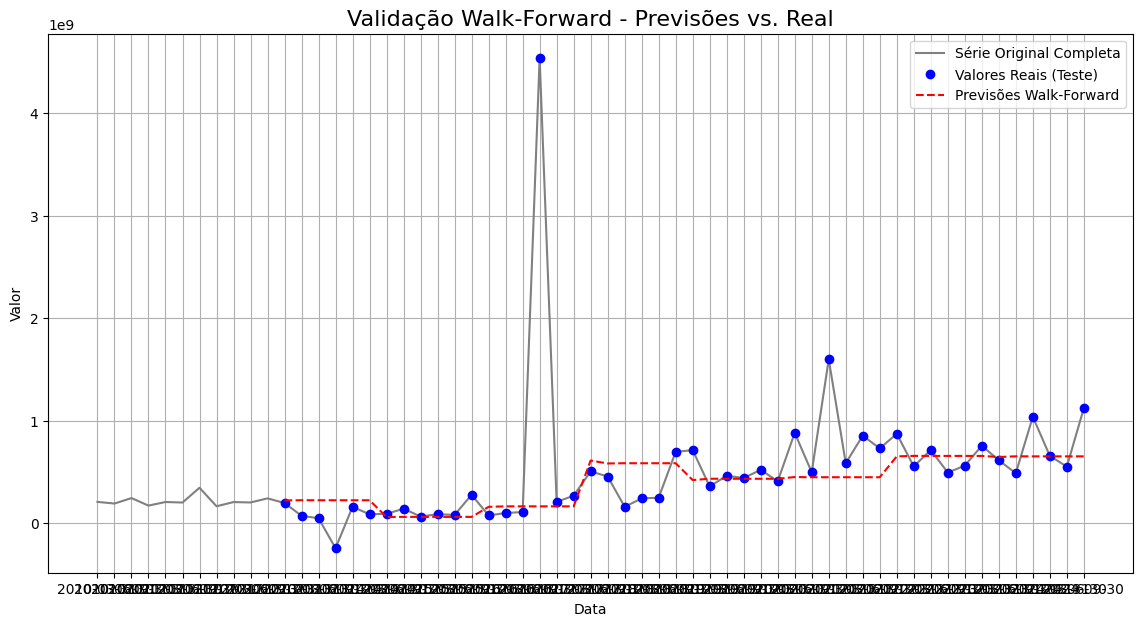


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 199446596.8470


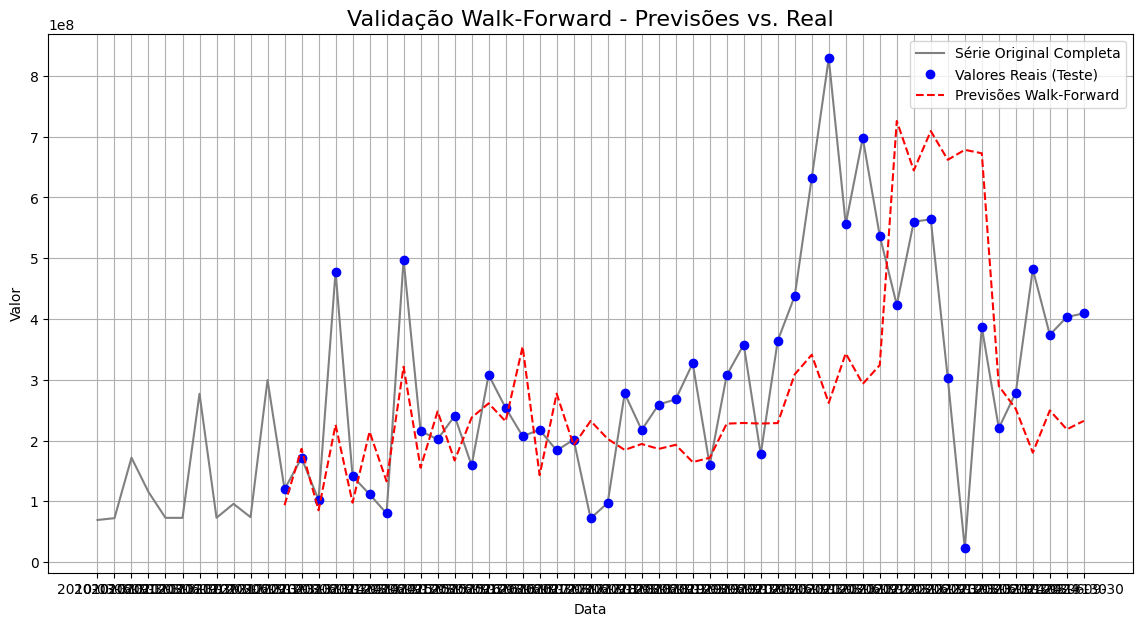


Empresa 21490 - Ordem ARIMA: [1, 1, 3]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 174146710.5387


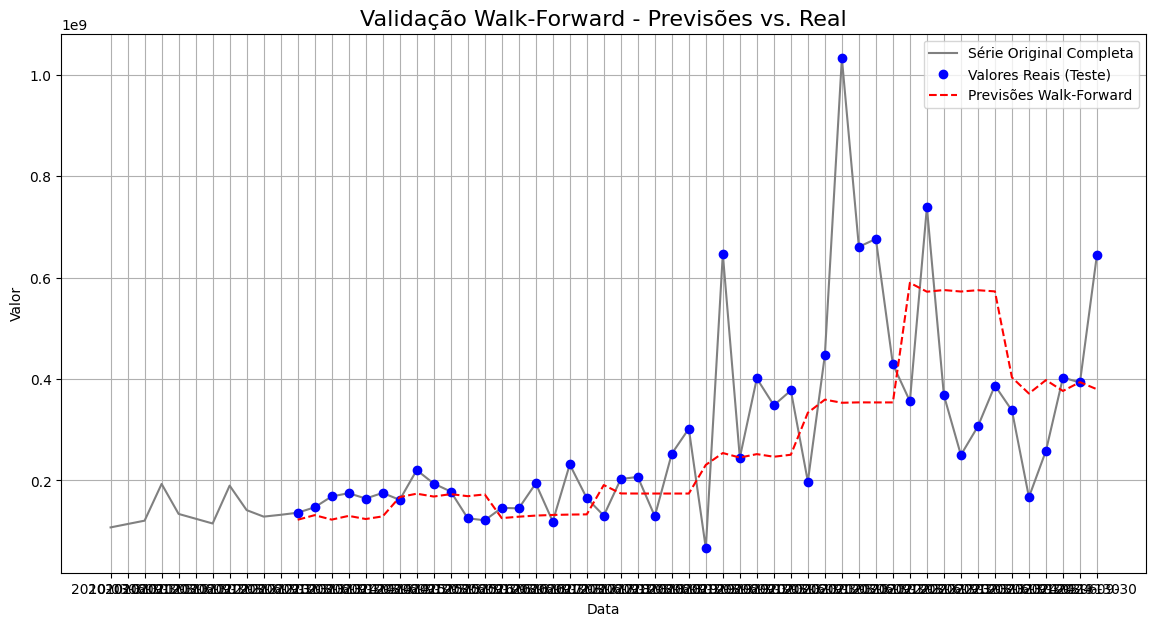

In [45]:
for empresa in lucro_consolidado.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {lucro_consolidado_comp_arima.loc[empresa].tolist()}")
    walk_forward_arima(lucro_consolidado[empresa], ordem_arima=lucro_consolidado_comp_arima.loc[empresa].tolist(), n_splits=8)


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 4648487399.8457


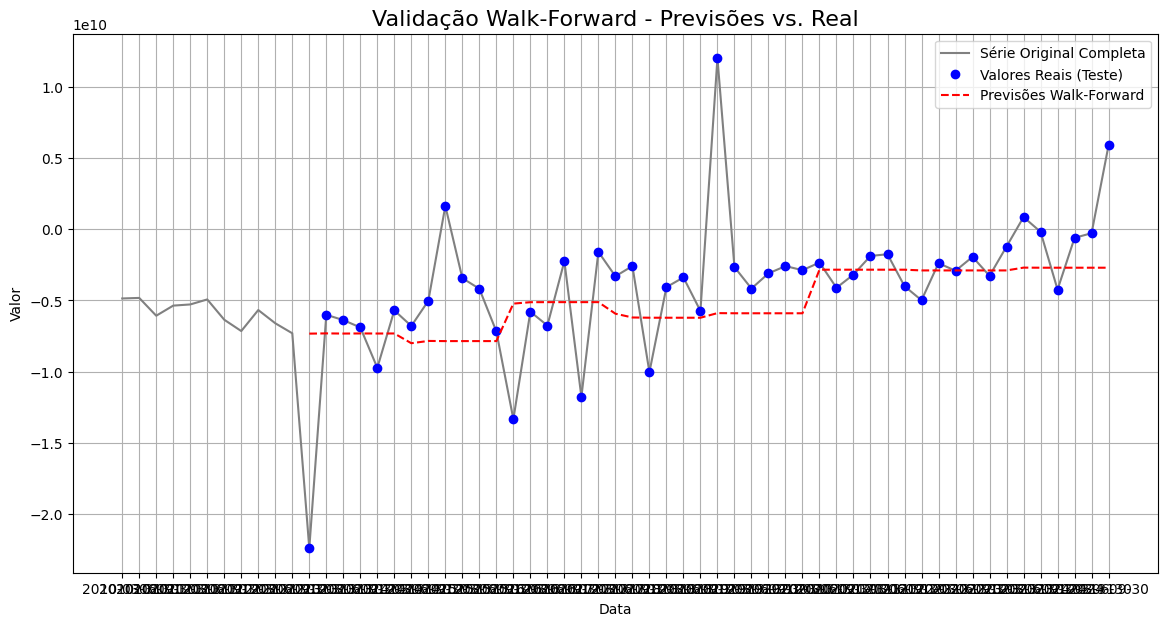


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 328076568.8443


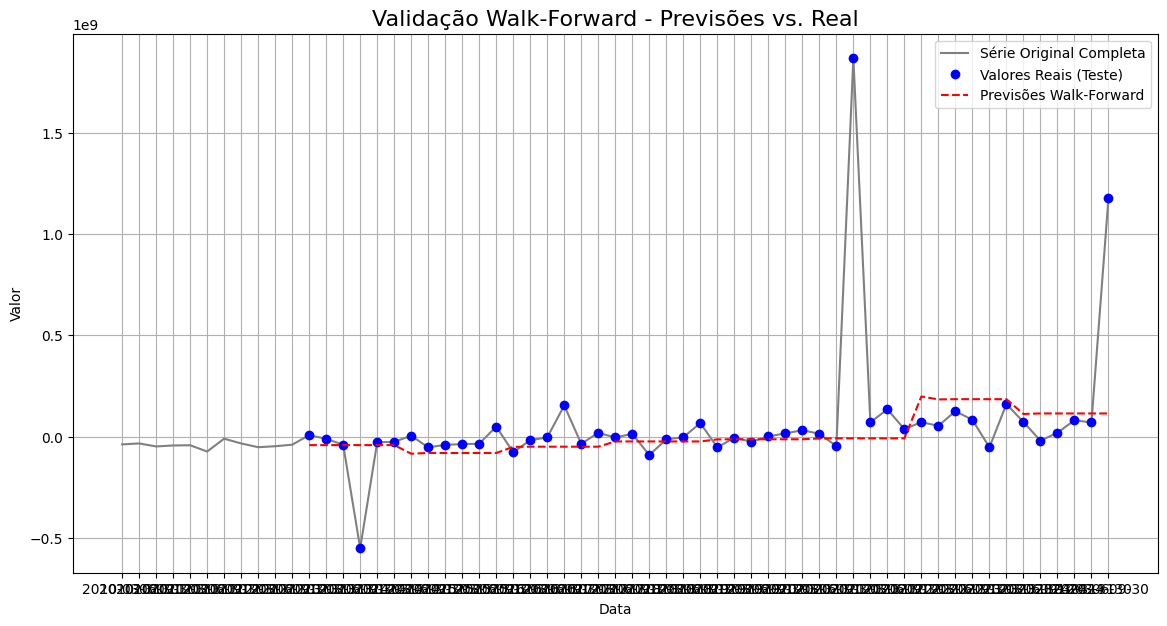


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 74488286.6125


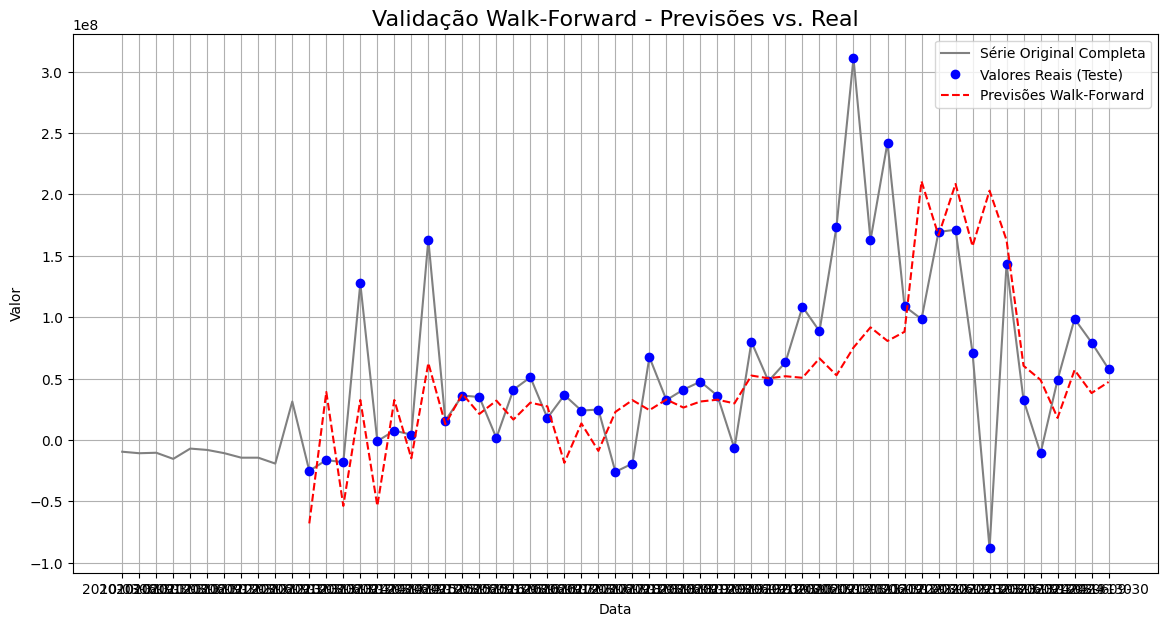


Empresa 21490 - Ordem ARIMA: [2, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 11, Tamanho do Teste: 6
--- Dobra 2/8 ---
Tamanho do Treino: 17, Tamanho do Teste: 6
--- Dobra 3/8 ---
Tamanho do Treino: 23, Tamanho do Teste: 6
--- Dobra 4/8 ---
Tamanho do Treino: 29, Tamanho do Teste: 6
--- Dobra 5/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 6
--- Dobra 6/8 ---
Tamanho do Treino: 41, Tamanho do Teste: 6
--- Dobra 7/8 ---
Tamanho do Treino: 47, Tamanho do Teste: 6
--- Dobra 8/8 ---
Tamanho do Treino: 53, Tamanho do Teste: 6

Validação Walk-Forward concluída.

RMSE Final (out-of-sample): 34109112.1283


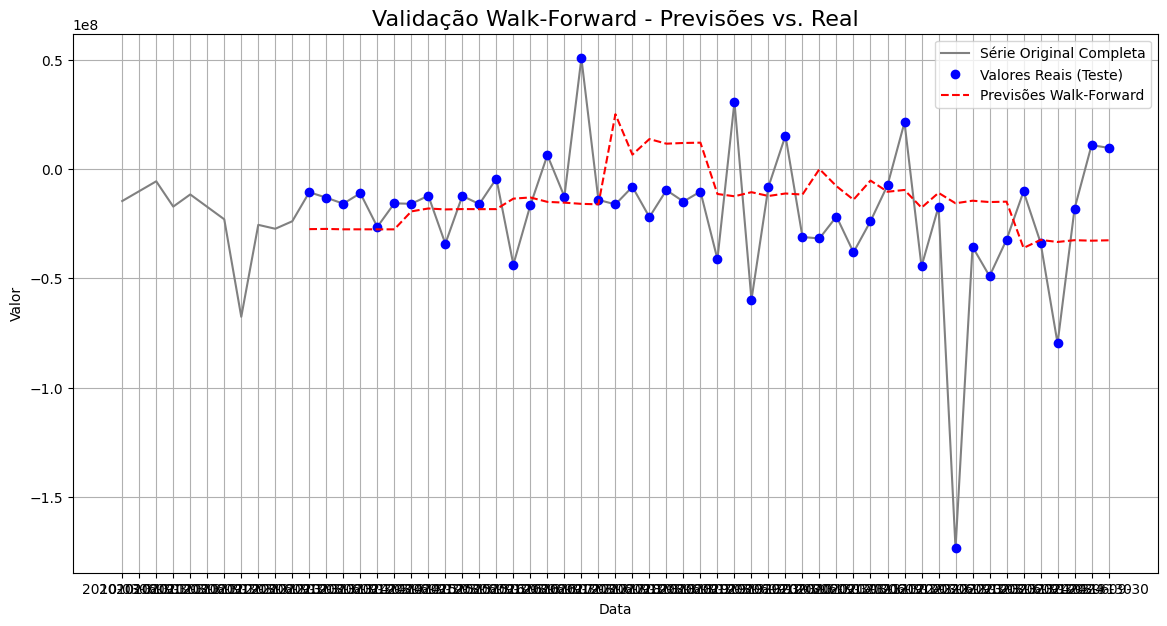

In [46]:
for empresa in despesas_operacionais.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {despesas_operacionais_comp_arima.loc[empresa].tolist()}")
    walk_forward_arima(despesas_operacionais[empresa], ordem_arima=despesas_operacionais_comp_arima.loc[empresa].tolist(), n_splits=8)

2 passos de previsão - não utilizado ainda

In [47]:
# from tqdm import tqdm # Biblioteca para adicionar uma barra de progresso (útil para loops longos)


# serie = resultado_bruto[21490]


# # --- 2. Definição do Modelo e Configuração do Walk-Forward com Horizonte Fixo ---

# ordem_arima = (2, 1, 1)
# horizonte_previsao = 2 # <-- A MUDANÇA PRINCIPAL: queremos prever 2 passos à frente

# # Definir o tamanho do conjunto de treino inicial
# # Vamos usar os primeiros 5 anos (20 trimestres) para o primeiro treino
# tamanho_treino_inicial = 20

# # Listas para armazenar os resultados
# valores_reais = []
# previsoes_h2 = []
# indices_previsao = [] # Guardar os índices de data para o plot

# print(f"Iniciando a validação Walk-Forward para horizonte h={horizonte_previsao}...")
# # --- 3. O Loop de Validação Walk-Forward Manual ---
# # Iteramos a partir do final do treino inicial até o penúltimo ponto possível
# for i in tqdm(range(tamanho_treino_inicial, len(serie) - horizonte_previsao + 1)):
    
#     # 1. Separar os dados de treino da iteração atual
#     treino = serie.iloc[:i]
    
#     # 2. Treinar o modelo ARIMA com os dados de treino
#     modelo = sm.tsa.ARIMA(treino, order=ordem_arima)
#     modelo_ajustado = modelo.fit()
    
#     # 3. Fazer a previsão de 'horizonte_previsao' passos à frente
#     previsao_passos = modelo_ajustado.forecast(steps=horizonte_previsao)
    
#     # 4. Capturar APENAS a previsão do horizonte desejado (a segunda previsão)
#     previsao_final = previsao_passos.iloc[horizonte_previsao - 1]
    
#     # 5. Capturar o valor real correspondente
#     indice_real = i + horizonte_previsao - 1
#     valor_real = serie.iloc[indice_real]
    
#     # 6. Guardar os resultados
#     previsoes_h2.append(previsao_final)
#     valores_reais.append(valor_real)
#     indices_previsao.append(serie.index[indice_real])

# print("\nValidação Walk-Forward concluída.")

# # --- 4. Avaliação e Visualização dos Resultados ---

# # Calcular a métrica de erro final
# rmse_final_h2 = np.sqrt(mean_squared_error(valores_reais, previsoes_h2))
# print(f"\nRMSE Final para Horizonte h=2 (out-of-sample): {rmse_final_h2:.4f}")

# # Criar um DataFrame com os resultados para facilitar a visualização
# df_resultados_h2 = pd.DataFrame({
#     'Real': valores_reais,
#     'Previsao_h2': previsoes_h2
# }, index=indices_previsao)

# # Plotar os resultados
# plt.figure(figsize=(14, 7))
# plt.plot(serie, label='Série Original Completa', color='gray', alpha=0.6)
# plt.plot(df_resultados_h2['Real'], label='Valores Reais (Teste, h=2)', color='blue', marker='o', linestyle='None')
# plt.plot(df_resultados_h2['Previsao_h2'], label=f'Previsões Walk-Forward (h={horizonte_previsao})', color='red', linestyle='--')
# plt.title(f'Validação Walk-Forward - Horizonte de Previsão h={horizonte_previsao}', fontsize=16)
# plt.xlabel('Data')
# plt.ylabel('Valor')
# plt.legend()
# plt.grid(True)
# plt.show()

ARIMAX

Reorganizando indicadores - usados nos modelos

In [48]:
#meça o tamanho de todas as listas do dict_indicadores
tamanhos = {k: v.shape[0] for k, v in dict_indicadores.items()}
tamanhos

{2437: 59, 18376: 59, 20257: 59, 21490: 59}

Criando lags

In [49]:
dict_indicadores[empresa].columns

Index(['3.01', '3.02', '3.03', '3.04', '3.05', '3.06', '3.07', '3.08', '3.09',
       '3.11'],
      dtype='object')

### REMOVER A COLUNAS DATA ANTES DE FAZER OS LAGS

In [50]:
#adicionar lags aos indicadores
df_lags_indicadores = {}
dict_indicadores_select = indicadores_estac.copy()

for empresa in dict_indicadores_select.keys(): 
    #Removendo indicadores que serão previstos nos modelos
    dict_indicadores_select[empresa].drop(columns=['3.01', '3.02', '3.11'], inplace=True)
    df_lags_indicadores[empresa] = adicionar_lags(dict_indicadores_select[empresa], lags=4)
    df_lags_indicadores[empresa] = df_lags_indicadores[empresa].iloc[8:]
    #renomear index
    print(df_lags_indicadores[empresa].columns)
    #normalizar os valores
    df_lags_indicadores[empresa] = (df_lags_indicadores[empresa] - df_lags_indicadores[empresa].mean()) / df_lags_indicadores[empresa].std()

#adicionar lags às entradas
df_lags_entradas = adicionar_lags(indices_estac, lags=8)
#df_lags_entradas = df_lags_entradas.iloc[4:]
#df_lags_entradas.set_index('data', inplace=True)


exog_vars_estac_lags = {}
for empresa in dict_indicadores.keys(): 
    #Removendo lags 0 dos indicadores, uma vez que não teremos estes valores
    dict_indicadores_select[empresa] = dict_indicadores_select[empresa].drop(columns=['3.03', '3.04', '3.05', '3.06', '3.07', '3.08', '3.09'])
    exog_vars_estac_lags[empresa] = pd.concat([dict_indicadores_select[empresa], df_lags_entradas], axis=1)
    exog_vars_estac_lags[empresa] = exog_vars_estac_lags[empresa].iloc[8:]
#antes de alimentar os modelos, dependendo da saída do modelo, tirar o indicador referente

Index(['3.03', '3.04', '3.05', '3.06', '3.07', '3.08', '3.09', '3.03_lag1',
       '3.04_lag1', '3.05_lag1', '3.06_lag1', '3.07_lag1', '3.08_lag1',
       '3.09_lag1', '3.03_lag2', '3.04_lag2', '3.05_lag2', '3.06_lag2',
       '3.07_lag2', '3.08_lag2', '3.09_lag2', '3.03_lag3', '3.04_lag3',
       '3.05_lag3', '3.06_lag3', '3.07_lag3', '3.08_lag3', '3.09_lag3',
       '3.03_lag4', '3.04_lag4', '3.05_lag4', '3.06_lag4', '3.07_lag4',
       '3.08_lag4', '3.09_lag4'],
      dtype='object')
Index(['3.03', '3.04', '3.05', '3.06', '3.07', '3.08', '3.09', '3.03_lag1',
       '3.04_lag1', '3.05_lag1', '3.06_lag1', '3.07_lag1', '3.08_lag1',
       '3.09_lag1', '3.03_lag2', '3.04_lag2', '3.05_lag2', '3.06_lag2',
       '3.07_lag2', '3.08_lag2', '3.09_lag2', '3.03_lag3', '3.04_lag3',
       '3.05_lag3', '3.06_lag3', '3.07_lag3', '3.08_lag3', '3.09_lag3',
       '3.03_lag4', '3.04_lag4', '3.05_lag4', '3.06_lag4', '3.07_lag4',
       '3.08_lag4', '3.09_lag4'],
      dtype='object')
Index(['3.03', '

In [51]:
for empresa in exog_vars_estac_lags.keys():
    exog_vars_estac_lags[empresa].to_csv(f'{path_dados_tratados}exog_vars_estac_lags_{empresa}.csv')

In [52]:
exog_vars_estac_lags[2437].columns

Index(['data', 'ibov', 'iee', 'selic', 'vix', 'igpm', 'ipca', 'IPAOG-DI',
       'INCC-Brasil-DI', 'IIE-Br',
       ...
       'Câmbio Efetiva Real_lag8', 'Juros EUA_lag8', 'T-bonds_lag8',
       'Cotação Dólar_lag8', 'CDI_lag8', 'TJLP_lag8', 'Energia Res._lag8',
       'Energia Ind._lag8', 'Energia Com._lag8', 'Dívida/PIB_lag8'],
      dtype='object', length=423)

Escolher as variáveis a serem utilizadas

In [53]:
def montar_exog_filtradas(ranked_pairs, exog_vars_estac_lags, threshold=0.25, verbose=False):
    """
    Retorna um dicionário: exog_filtradas[empresa][indicador] = DataFrame com colunas filtradas.
    Seleciona pares cuja Abs_CCF >= threshold (default=0.25).
    Colunas esperadas em exog_vars_estac_lags: 'indice' (lag 0) e 'indice_lagN' (N>=1).
    """
    rp = ranked_pairs.copy()
    rp = rp[rp['Abs_CCF'] >= float(threshold)]

    exog_filtradas = {}
    for emp, df_emp in rp.groupby('Empresa'):
        base = exog_vars_estac_lags.get(emp)
        if base is None:
            continue
        exog_filtradas[emp] = {}
        for indicador, df_ind in df_emp.groupby('Indicador'):
            cols = []
            for _, row in df_ind.iterrows():
                indice = str(row['Indice'])
                lag = int(row['Lag'])
                col = indice if lag == 0 else f"{indice}_lag{lag}"
                # aceita 'indice' (lag0) ou 'indice_lag0' se existir
                if col in base.columns:
                    cols.append(col)
                elif lag == 0 and f"{indice}_lag0" in base.columns:
                    cols.append(f"{indice}_lag0")
            cols = sorted(pd.unique(cols))
            if cols:
                exog_filtradas[emp][indicador] = base[cols].copy()
                if verbose:
                    print(f"Empresa {emp} | Indicador {indicador}: {len(cols)} colunas -> {cols}")
    return exog_filtradas

In [54]:
exog_filtradas = montar_exog_filtradas(ranked_pairs, exog_vars_estac_lags, threshold=0.25, verbose=True)

# Visualização rápida
exog_filtradas[21490]['3.11'].head()

Empresa 2437 | Indicador 3.01: 26 colunas -> ['Câmbio Efetiva Real_lag1', 'Câmbio Real/Dólar_lag8', 'Câmbio Real/Libra_lag1', 'Dívida/PIB_lag1', 'Energia Com._lag6', 'Energia Ind._lag7', 'Expec IIE-Br_lag6', 'IA Emp_lag6', 'IIE-Br_lag6', 'Juros EUA_lag4', 'Mídia - IIE-Br_lag6', 'PIB Corrente_lag7', 'Var. IA Emp_lag7', 'Vol. Impostos_lag7', 'Vol. PIB Sazonal_lag6', 'Vol. PIB Trim. Saz._lag6', 'Vol. VA Agro Trim. Saz._lag3', 'Vol. VA Agro_lag3', 'Vol. VA Sazonal_lag6', 'Vol. VA Serv. Sazonal_lag6', 'Vol. VA Serv. Trim. Saz._lag6', 'Vol. VA Serviços_lag7', 'Vol. VA Trim. Saz._lag6', 'ibov_lag5', 'igpm_lag4', 'vix_lag5']
Empresa 2437 | Indicador 3.02: 32 colunas -> ['CDI_lag8', 'Cotação Dólar_lag6', 'Câmbio Efetiva Real_lag6', 'Câmbio Real/Dólar_lag6', 'Câmbio Real/Libra_lag6', 'Câmbio Real/Peso_lag3', 'Dívida/PIB_lag5', 'Energia Ind._lag6', 'IA Emp_lag6', 'IPAOG-DI_lag8', 'Juros EUA_lag6', 'PIB 1995_lag6', 'PIB Corrente_lag7', 'TJLP_lag2', 'Vol. Impostos_lag6', 'Vol. PIB Mensal_lag6', 'Vo

,Cotação Dólar_lag6,Dívida/PIB_lag4,Energia Com._lag2,Energia Ind._lag5,Energia Res.,IIE-Br_lag5,INCC-Brasil-DI_lag8,Juros EUA_lag5,PIB 1995_lag5,PIB Corrente_lag6,...,Vol. VA Indústria_lag6,Vol. VA Produção_lag5,Vol. VA Sazonal_lag5,Vol. VA Serv. Sazonal_lag5,Vol. VA Serv. Trim. Saz._lag5,Vol. VA Serviços_lag5,Vol. VA Trim. Saz._lag5,ibov_lag4,iee_lag4,ipca_lag2
2012-06-30,-0.052567,-0.280000,404.666667,-592.333333,-236.666667,-1.233333,NaN,-0.030000,-1822.000000,1881.666667,...,-1.061000,-2.798333,1.490333,1.224000,2.020,-5.506000,1.946,-6183.0,181.64,0.014570
2012-09-30,-0.029400,-1.236667,416.666667,611.333333,-140.333333,-0.800000,-1.929333,-0.063333,3458.333333,-33425.000000,...,-9.310333,5.891000,1.515333,1.165000,0.901,4.405333,1.567,-10080.0,-2263.11,0.012246
2012-12-31,-0.071700,-1.053333,-185.666667,348.000000,505.333333,9.466667,-4.689667,-0.010000,1814.666667,37007.333333,...,10.804667,2.896000,0.209667,0.057333,-0.010,2.461333,-0.240,4430.0,4803.05,0.010831
2013-03-31,0.041267,-0.156667,-238.666667,-194.333333,531.666667,0.533333,2.121667,-0.010000,-980.000000,-14853.000000,...,5.434000,-2.061667,1.077667,1.169667,0.888,2.155667,1.513,7757.0,2667.97,0.014166
2013-06-30,0.163200,-1.786667,628.000000,-410.666667,-373.333333,-7.600000,10.380000,0.030000,-2681.333333,7615.666667,...,-4.209000,-4.393000,-1.416667,0.812667,-0.203,-5.478333,-2.866,-10156.0,134.60,0.019930


In [55]:
exog_filtradas[21490]['3.01'] = exog_filtradas[21490]['3.01'].interpolate(method='linear', limit_direction='both')

In [56]:
exog_filtradas[21490]['3.01'].columns

Index(['Cotação Dólar_lag6', 'Câmbio Efetiva Real_lag6',
       'Câmbio Real/Dólar_lag6', 'Câmbio Real/Iene_lag6', 'Energia Com._lag2',
       'Energia Ind._lag5', 'Energia Res.', 'INCC-Brasil-DI_lag8',
       'IPAOG-DI_lag6', 'Juros EUA_lag5', 'PIB 1995_lag5', 'PIB Corrente_lag6',
       'T-bonds_lag4', 'TJLP_lag1', 'Var. IA Emp_lag5', 'Vol. Impostos_lag5',
       'Vol. PIB Mensal_lag5', 'Vol. PIB Sazonal_lag5', 'Vol. PIB Trim. Saz.',
       'Vol. VA Agro Sazonal_lag4', 'Vol. VA Agro Trim. Saz._lag4',
       'Vol. VA Ind. Sazonal_lag6', 'Vol. VA Ind. Trim. Saz._lag6',
       'Vol. VA Indústria_lag5', 'Vol. VA Produção_lag5',
       'Vol. VA Sazonal_lag5', 'Vol. VA Serv. Sazonal_lag5',
       'Vol. VA Serv. Trim. Saz.', 'Vol. VA Serviços_lag5',
       'Vol. VA Trim. Saz.', 'ibov_lag4', 'iee_lag5', 'igpm_lag6',
       'ipca_lag2'],
      dtype='object')

Retira multicolinearidade - VIF

In [57]:
def calcular_vif_iterativo(df, thresh=5.0, max_iter=100, verbose=True):
    """
    Calcula VIF iterativamente removendo a variável com maior VIF até que todos fiquem <= thresh.
    Retorna:
      - df_filtrado: DataFrame final após remoções
      - vif_final: Series com VIF das variáveis remanescentes
      - removidas: DataFrame com ordem de remoção e VIF no momento da remoção
    """
    # Copiar e manter apenas colunas numéricas
    df_work = df.select_dtypes(include=[np.number]).copy()

    # Remover colunas constantes ou quase-constantes
    const_cols = [c for c in df_work.columns if df_work[c].nunique(dropna=True) <= 1]
    if const_cols and verbose:
        print(f"Removendo colunas constantes: {const_cols}")
    df_work.drop(columns=const_cols, inplace=True, errors='ignore')

    # # Limpeza de dados: remover linhas com NaN/Inf
    # df_work = df_work.replace([np.inf, -np.inf], np.nan).dropna(axis=0, how='any')

    removidas = []
    it = 0
    while it < max_iter and df_work.shape[1] > 1:
        it += 1
        X = sm.add_constant(df_work, has_constant='add')
        vifs = []
        for i, col in enumerate(X.columns):
            try:
                val = variance_inflation_factor(X.values, i)
            except Exception:
                val = np.inf
            vifs.append(val)
        vif = pd.Series(vifs, index=X.columns)

        # descartar a constante
        if 'const' in vif.index:
            vif = vif.drop('const', errors='ignore')

        # Se todas as variáveis estão abaixo do limiar, parar
        max_v = vif.max()
        if pd.isna(max_v) or max_v <= thresh:
            if verbose:
                print("\nTodos os VIFs estão abaixo do limite.")
            break

        # Remover a variável com maior VIF (inclusive se for inf)
        col_remover = vif.idxmax()
        if verbose:
            print(f"Removendo '{col_remover}' com VIF de {max_v:.2f}")
        removidas.append({'variavel': col_remover, 'vif': float(max_v), 'iter': it})
        df_work = df_work.drop(columns=[col_remover])

        # Se sobrar 1 coluna, não há por que continuar
        if df_work.shape[1] <= 1:
            break

    # VIF final das variáveis remanescentes
    if df_work.shape[1] >= 1:
        Xf = sm.add_constant(df_work, has_constant='add')
        vifs_final = []
        for i, col in enumerate(Xf.columns):
            try:
                val = variance_inflation_factor(Xf.values, i)
            except Exception:
                val = np.inf
            vifs_final.append(val)
        vif_final = pd.Series(vifs_final, index=Xf.columns).drop('const', errors='ignore').sort_values(ascending=False)
    else:
        vif_final = pd.Series(dtype=float)

    removidas_df = pd.DataFrame(removidas)
    if verbose:
        print("\nDataFrame final após remoção por VIF:")
        display(df_work.head())
        print("\nValores finais de VIF:")
        display(vif_final)

    return df_work, vif_final, removidas_df




# ...existing code...

In [58]:
# Exemplo: aplicar em todos os dataframes de exog_vars_estac
vif_filtrados = {}
vif_finais = {}
vif_remocoes = {}

for empresa, df_exog in exog_filtradas.items():
    print(f"\n=== Empresa {empresa} ===")
    df_filtrado, vif_final, removidas = calcular_vif_iterativo(df_exog['3.01'], thresh=5.0, verbose=True)
    vif_filtrados[empresa] = df_filtrado
    vif_finais[empresa] = vif_final
    vif_remocoes[empresa] = removidas


=== Empresa 2437 ===
Removendo 'Vol. PIB Sazonal_lag6' com VIF de 974.24
Removendo 'Vol. PIB Trim. Saz._lag6' com VIF de 482.59
Removendo 'Vol. VA Sazonal_lag6' com VIF de 91.79
Removendo 'Vol. VA Serviços_lag7' com VIF de 59.05
Removendo 'Vol. VA Serv. Trim. Saz._lag6' com VIF de 54.73
Removendo 'Vol. Impostos_lag7' com VIF de 24.69
Removendo 'Câmbio Real/Libra_lag1' com VIF de 15.23
Removendo 'Vol. VA Serv. Sazonal_lag6' com VIF de 13.23
Removendo 'Expec IIE-Br_lag6' com VIF de 6.79

Todos os VIFs estão abaixo do limite.

DataFrame final após remoção por VIF:


,Câmbio Efetiva Real_lag1,Câmbio Real/Dólar_lag8,Dívida/PIB_lag1,Energia Com._lag6,Energia Ind._lag7,IA Emp_lag6,IIE-Br_lag6,Juros EUA_lag4,Mídia - IIE-Br_lag6,PIB Corrente_lag7,Var. IA Emp_lag7,Vol. VA Agro Trim. Saz._lag3,Vol. VA Agro_lag3,Vol. VA Trim. Saz._lag6,ibov_lag5,igpm_lag4,vix_lag5
2012-06-30,0.286667,-0.923333,-0.156667,506.333333,346.333333,93.500000,0.200000,-0.063333,96.900000,13491.000000,-0.526667,9.113,-8.581000,2.195,-718.0,0.007003,17.74
2012-09-30,2.986667,-2.246667,-1.786667,367.666667,-82.000000,92.633333,-1.233333,-0.010000,98.133333,1881.666667,-0.210000,9.410,-50.366667,1.946,-6183.0,0.009715,16.52
2012-12-31,-1.110000,-2.416667,-0.440000,-312.000000,-592.333333,90.500000,-0.800000,-0.010000,96.566667,-33425.000000,-0.206667,-38.716,42.396667,1.567,-10080.0,0.009114,42.96
2013-03-31,0.573333,-0.913333,-0.340000,-123.666667,611.333333,86.166667,9.466667,0.030000,108.600000,37007.333333,-1.170000,19.629,16.231000,-0.240,4430.0,0.006207,23.40
2013-06-30,-0.716667,-1.456667,0.150000,404.666667,348.000000,86.133333,0.533333,0.050000,107.733333,-14853.000000,-1.620000,20.152,0.809000,1.513,7757.0,0.025511,15.50



Valores finais de VIF:


Energia Com._lag6               4.586137
Vol. VA Agro_lag3               3.936100
PIB Corrente_lag7               3.783490
Vol. VA Trim. Saz._lag6         3.718569
Energia Ind._lag7               3.704754
IIE-Br_lag6                     3.165398
igpm_lag4                       2.354796
ibov_lag5                       2.200365
Câmbio Efetiva Real_lag1        2.184413
Dívida/PIB_lag1                 2.160681
Mídia - IIE-Br_lag6             2.048829
vix_lag5                        1.949801
Var. IA Emp_lag7                1.906260
IA Emp_lag6                     1.804754
Juros EUA_lag4                  1.390939
Câmbio Real/Dólar_lag8          1.385392
Vol. VA Agro Trim. Saz._lag3    1.379775
dtype: float64


=== Empresa 18376 ===

DataFrame final após remoção por VIF:


...

Vol. VA Serviços_lag6    2.706685
Vol. VA Produção_lag6    2.300521
Vol. VA Indústria        1.740720
INCC-Brasil-DI_lag3      1.708427
ipca_lag6                1.317474
T-bonds_lag1             1.254258
dtype: float64


=== Empresa 21490 ===
Removendo 'Vol. PIB Mensal_lag5' com VIF de 258856797.76
Removendo 'PIB 1995_lag5' com VIF de 224548.58
Removendo 'Vol. PIB Sazonal_lag5' com VIF de 2249.60
Removendo 'Vol. PIB Trim. Saz.' com VIF de 516.86
Removendo 'Vol. Impostos_lag5' com VIF de 95.88
Removendo 'Vol. VA Agro Sazonal_lag4' com VIF de 73.19
Removendo 'Vol. VA Ind. Trim. Saz._lag6' com VIF de 65.63
Removendo 'Vol. VA Sazonal_lag5' com VIF de 42.62
Removendo 'Câmbio Real/Dólar_lag6' com VIF de 30.27
Removendo 'Vol. VA Trim. Saz.' com VIF de 26.08
Removendo 'Vol. VA Produção_lag5' com VIF de 25.05
Removendo 'Vol. VA Serviços_lag5' com VIF de 16.53
Removendo 'igpm_lag6' com VIF de 13.27
Removendo 'Energia Ind._lag5' com VIF de 12.01
Removendo 'Cotação Dólar_lag6' com VIF de 8.02
Removendo 'Energia Com._lag2' com VIF de 6.76
Removendo 'Câmbio Real/Iene_lag6' com VIF de 5.06

Todos os VIFs estão abaixo do limite.

DataFrame final após remoção por VIF:


,Câmbio Efetiva Real_lag6,Energia Res.,INCC-Brasil-DI_lag8,IPAOG-DI_lag6,Juros EUA_lag5,PIB Corrente_lag6,T-bonds_lag4,TJLP_lag1,Var. IA Emp_lag5,Vol. VA Agro Trim. Saz._lag4,Vol. VA Ind. Sazonal_lag6,Vol. VA Indústria_lag5,Vol. VA Serv. Sazonal_lag5,Vol. VA Serv. Trim. Saz.,ibov_lag4,iee_lag5,ipca_lag2
2012-06-30,-1.576667,-236.666667,-1.929333,19.624000,-0.030000,1881.666667,-0.220000,0.0,-0.206667,-1.847,2.494333,-9.310333,1.224000,3.441,-6183.0,2649.56,0.014570
2012-09-30,0.153333,-140.333333,-1.929333,13.283000,-0.063333,-33425.000000,-0.640000,0.0,-1.170000,9.113,1.695667,10.804667,1.165000,1.773,-10080.0,181.64,0.012246
2012-12-31,-1.340000,505.333333,-4.689667,2.765667,-0.010000,37007.333333,-0.656667,-0.5,-1.620000,9.410,2.740333,5.434000,0.057333,0.881,4430.0,-2263.11,0.010831
2013-03-31,1.030000,531.666667,2.121667,1.727667,-0.010000,-14853.000000,0.096667,0.0,0.203333,-38.716,-1.470000,-4.209000,1.169667,0.619,7757.0,4803.05,0.014166
2013-06-30,2.773333,-373.333333,10.380000,6.920333,0.030000,7615.666667,-0.203333,-0.5,1.123333,19.629,0.299333,-8.742333,0.812667,2.093,-10156.0,2667.97,0.019930



Valores finais de VIF:


Vol. VA Indústria_lag5          2.531928
ipca_lag2                       2.406806
Energia Res.                    2.035623
Vol. VA Ind. Sazonal_lag6       1.982824
Vol. VA Serv. Sazonal_lag5      1.935398
INCC-Brasil-DI_lag8             1.876961
Câmbio Efetiva Real_lag6        1.814054
IPAOG-DI_lag6                   1.789500
TJLP_lag1                       1.727763
PIB Corrente_lag6               1.718275
Juros EUA_lag5                  1.612111
Var. IA Emp_lag5                1.591044
iee_lag5                        1.573861
Vol. VA Agro Trim. Saz._lag4    1.564564
Vol. VA Serv. Trim. Saz.        1.529512
ibov_lag4                       1.474876
T-bonds_lag4                    1.378889
dtype: float64

Teste modelo Arimax

In [1]:
def gera_modelo_arimax(serie_temporal, df_componentes, exog_dict):
    modelos_arimax = {}

    for cd_cvm in df_componentes.index:
        series = serie_temporal.copy()[cd_cvm]
        exog_vars = exog_dict.get(cd_cvm).copy()
        n = len(series)
        split_point = int(n * 0.8)  # 80% dos dados para treino
        print(f"CD_CVM: {cd_cvm}, Length: {n}, Split Point: {split_point}")
        p = df_componentes.loc[cd_cvm, 'AR(p)']
        q = df_componentes.loc[cd_cvm, 'MA(q)']
        i = df_componentes.loc[cd_cvm, 'I(d)']
        order = (p, i, q)

        serie = series.iloc[:split_point]
        
        exog_vars = exog_vars.iloc[:split_point]

        try:
            print(f"Serie: {serie.shape}, Exog: {exog_vars.shape}, Order: {order}")
            modelo = ARIMA(serie, order=order, exog=exog_vars).fit()
            modelos_arimax[cd_cvm] = modelo
            #print(f'Modelo ARIMAX({p}, {i}, {q}) para CD_CVM {cd_cvm} ajustado com sucesso.')
            print(modelo.summary())
        except Exception as e:
            print(f'Erro ao ajustar modelo ARIMAX para CD_CVM {cd_cvm}: {str(e)}')
        
    return modelos_arimax

In [60]:
vif_finais[2437].keys()

Index(['Energia Com._lag6', 'Vol. VA Agro_lag3', 'PIB Corrente_lag7',
       'Vol. VA Trim. Saz._lag6', 'Energia Ind._lag7', 'IIE-Br_lag6',
       'igpm_lag4', 'ibov_lag5', 'Câmbio Efetiva Real_lag1', 'Dívida/PIB_lag1',
       'Mídia - IIE-Br_lag6', 'vix_lag5', 'Var. IA Emp_lag7', 'IA Emp_lag6',
       'Juros EUA_lag4', 'Câmbio Real/Dólar_lag8',
       'Vol. VA Agro Trim. Saz._lag3'],
      dtype='object')

In [61]:
input_receita = {}
for empresa in exog_filtradas.keys():
    input_receita[empresa] = exog_filtradas[empresa]['3.01']

In [62]:
#usar vif_filtrados para dados sem multicolineariade ou input_receita para dados que não passaram pelo VIF
modelo_arimax_resultado_bruto = gera_modelo_arimax(resultado_bruto[9:], resultado_bruto_comp_arima, vif_filtrados)

CD_CVM: 2437, Length: 50, Split Point: 40
Serie: (40,), Exog: (40, 17), Order: (1, 1, 1)
                               SARIMAX Results                                
Dep. Variable:                   2437   No. Observations:                   40
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -923.530
Date:                Sun, 05 Oct 2025   AIC                           1887.061
Time:                        13:25:47   BIC                           1920.332
Sample:                    06-30-2012   HQIC                          1898.998
                         - 03-31-2022                                         
Covariance Type:                  opg                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Câmbio Efetiva Real_lag1      7.268e+07    875.929    8.3e+04      0.000    7.27e+07 

In [63]:
def walk_forward_arimax(serie, ordem_arima, n_splits=8, input_exog=None):

    # Configurando o TimeSeriesSplit
    # Vamos dividir os dados em 8 janelas de teste. A janela de treino irá crescer a cada passo.
    tscv = TimeSeriesSplit(n_splits=n_splits)

    # Listas para armazenar os resultados de cada dobra da validação
    valores_reais = []
    previsoes = []

    print("Iniciando a validação Walk-Forward...")
    # --- 3. O Loop de Validação Walk-Forward ---
    # O tscv.split(serie) gera os índices de treino e teste para cada dobra
    for i, (train_index, test_index) in enumerate(tscv.split(serie)):
        print(f"--- Dobra {i+1}/{n_splits} ---")
        
        # 1. Separar os dados de treino e teste da dobra atual
        treino = serie.iloc[train_index]
        treino_exog = input_exog.iloc[train_index]
        teste = serie.iloc[test_index]
        teste_exog = input_exog.iloc[test_index]
        print(f"Tamanho do Treino: {len(treino)}, Tamanho do Teste: {len(teste)}")
        
        # 2. Treinar o modelo ARIMA APENAS com os dados de treino
        # O modelo é retreinado a cada passo com mais dados, simulando a realidade
        modelo = sm.tsa.ARIMA(treino, order=ordem_arima, exog=treino_exog)
        modelo_ajustado = modelo.fit()
        
        # 3. Fazer a previsão para o período de teste
        # O número de passos da previsão é o tamanho do conjunto de teste
        previsao = modelo_ajustado.forecast(steps=len(teste), exog=teste_exog)
        
        # 4. Guardar os resultados
        previsoes.extend(previsao)
        valores_reais.extend(teste)

    #iterar modelo ARIMAX removendo componentes que não são significativos´
    print(modelo_ajustado.summary())

    # --- 4. Avaliação e Visualização dos Resultados ---
    # Calcular a métrica de erro final sobre todos os pontos previstos
    rmse_final = np.sqrt(mean_squared_error(valores_reais, previsoes))
    print(f"\nRMSE Final (out-of-sample): {rmse_final:.4f}")

    # Criar um DataFrame com os resultados para facilitar a visualização
    df_resultados = pd.DataFrame({
        'Real': valores_reais,
        'Previsao': previsoes
    }, index=serie.index[-len(valores_reais):]) # Garante que o índice de datas está correto

    # Plotar os resultados

    plt.figure(figsize=(14, 7))
    plt.plot(serie, label='Série Original Completa', color='gray')
    plt.plot(df_resultados['Real'], label='Valores Reais (Teste)', color='blue', marker='o', linestyle='None')
    plt.plot(df_resultados['Previsao'], label='Previsões Walk-Forward', color='red', linestyle='--')
    plt.title('Validação Walk-Forward - Previsões vs. Real', fontsize=16)
    plt.xlabel('Data')
    plt.ylabel('Valor')
    plt.legend()
    plt.grid(True)
    plt.show()

    return rmse_final, modelo_ajustado

In [64]:
def walk_forward_arimax_one_step(serie, ordem_arima, tamanho_treino_inicial, input_exog=None):
    """
    Realiza a validação walk-forward prevendo apenas um passo à frente por vez.

    Parâmetros:
    - serie: A série temporal completa (Pandas Series).
    - ordem_arima: A ordem (p, d, q) do modelo ARIMA.
    - tamanho_treino_inicial: O número de observações para o primeiro treino.
    - input_exog: DataFrame com as variáveis exógenas.
    """
    # Listas para armazenar os resultados
    valores_reais = []
    previsoes = []
    
    # O número total de previsões que faremos
    n_previsoes = len(serie) - tamanho_treino_inicial

    print(f"Iniciando a validação Walk-Forward (One-Step-Ahead)...")
    print(f"Tamanho do treino inicial: {tamanho_treino_inicial}, Número de previsões a fazer: {n_previsoes}")

    # --- O Novo Loop de Validação ---
    # Este loop itera para cada ponto que queremos prever
    for i in range(n_previsoes):
        # O índice do ponto atual no DataFrame original
        indice_atual = tamanho_treino_inicial + i
        
        # 1. Separar os dados de treino
        # O treino contém todos os dados até o ponto ANTERIOR ao que queremos prever
        treino = serie.iloc[:indice_atual]
        treino_exog = input_exog.iloc[:indice_atual]
        
        # O valor real é o ponto exato que estamos tentando prever
        valor_real = serie.iloc[indice_atual]
        
        # A variável exógena para a previsão precisa ser a do momento da previsão
        teste_exog = input_exog.iloc[indice_atual:indice_atual+1]

        # Imprimir progresso para não parecer que travou (este processo é lento)
        if (i + 1) % 10 == 0 or (i + 1) == n_previsoes:
             print(f"--- Prevendo passo {i+1}/{n_previsoes} (Treinando com {len(treino)} observações) ---")
        
        # 2. Treinar o modelo ARIMA com a janela de treino atual
        modelo = sm.tsa.ARIMA(treino, order=ordem_arima, exog=treino_exog)
        modelo_ajustado = modelo.fit()
        
        # 3. Fazer a previsão de APENAS UM PASSO à frente
        previsao = modelo_ajustado.forecast(steps=1, exog=teste_exog)
        
        # 4. Guardar os resultados
        previsoes.append(previsao.iloc[0]) # .iloc[0] para pegar o valor escalar da previsão
        valores_reais.append(valor_real)

    print("\nValidação Walk-Forward concluída.")
    
    # O restante do código para avaliação e plotagem permanece o mesmo
    rmse_final = np.sqrt(mean_squared_error(valores_reais, previsoes))
    print(f"RMSE Final (out-of-sample): {rmse_final:.4f}")

    df_resultados = pd.DataFrame({
        'Real': valores_reais,
        'Previsao': previsoes
    }, index=serie.index[-len(valores_reais):])

    plt.figure(figsize=(14, 7))
    plt.plot(serie, label='Série Original Completa', color='gray', alpha=0.6)
    plt.plot(df_resultados['Real'], label='Valores Reais (Teste)', color='blue', marker='o', linestyle='None', markersize=5)
    plt.plot(df_resultados['Previsao'], label='Previsões One-Step-Ahead', color='red', linestyle='--')
    plt.title('Validação Walk-Forward (One-Step-Ahead) - Previsões vs. Real', fontsize=16)
    plt.xlabel('Data')
    plt.ylabel('Valor')
    plt.legend()
    plt.grid(True)
    plt.show()

    return rmse_final, modelo_ajustado

In [65]:
resultado_bruto_comp_arima

,I(d),AR(p),MA(q)
2437,1,1,1
18376,1,1,1
20257,1,1,4
21490,1,1,5



Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 10, Tamanho do Teste: 5
--- Dobra 2/8 ---
Tamanho do Treino: 15, Tamanho do Teste: 5
--- Dobra 3/8 ---
Tamanho do Treino: 20, Tamanho do Teste: 5
--- Dobra 4/8 ---
Tamanho do Treino: 25, Tamanho do Teste: 5
--- Dobra 5/8 ---
Tamanho do Treino: 30, Tamanho do Teste: 5
--- Dobra 6/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 5
--- Dobra 7/8 ---
Tamanho do Treino: 40, Tamanho do Teste: 5
--- Dobra 8/8 ---
Tamanho do Treino: 45, Tamanho do Teste: 5
                               SARIMAX Results                                
Dep. Variable:                   2437   No. Observations:                   45
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1021.906
Date:                Sun, 05 Oct 2025   AIC                           2101.811
Time:                        13:25:50   BIC                           2153.553
Sample:                    06-30-2012   

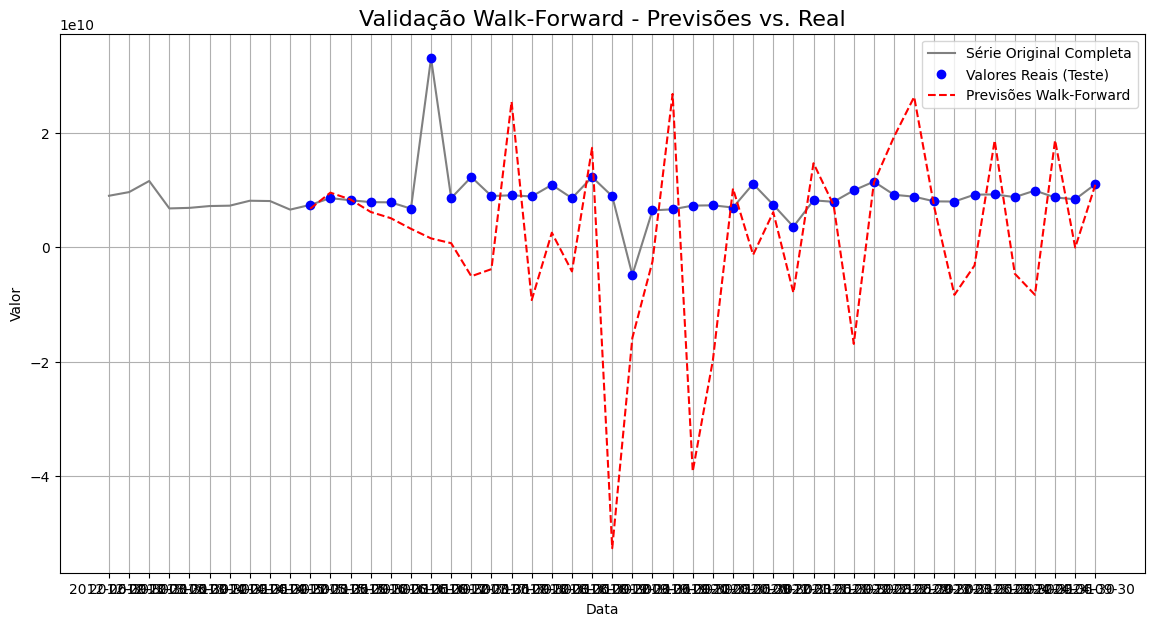


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 10, Tamanho do Teste: 5
--- Dobra 2/8 ---
Tamanho do Treino: 15, Tamanho do Teste: 5
--- Dobra 3/8 ---
Tamanho do Treino: 20, Tamanho do Teste: 5
--- Dobra 4/8 ---
Tamanho do Treino: 25, Tamanho do Teste: 5
--- Dobra 5/8 ---
Tamanho do Treino: 30, Tamanho do Teste: 5
--- Dobra 6/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 5
--- Dobra 7/8 ---
Tamanho do Treino: 40, Tamanho do Teste: 5
--- Dobra 8/8 ---
Tamanho do Treino: 45, Tamanho do Teste: 5
                               SARIMAX Results                                
Dep. Variable:                  18376   No. Observations:                   45
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -972.824
Date:                Sun, 05 Oct 2025   AIC                           1953.649
Time:                        13:25:51   BIC                           1960.786
Sample:                    06-30-2012  

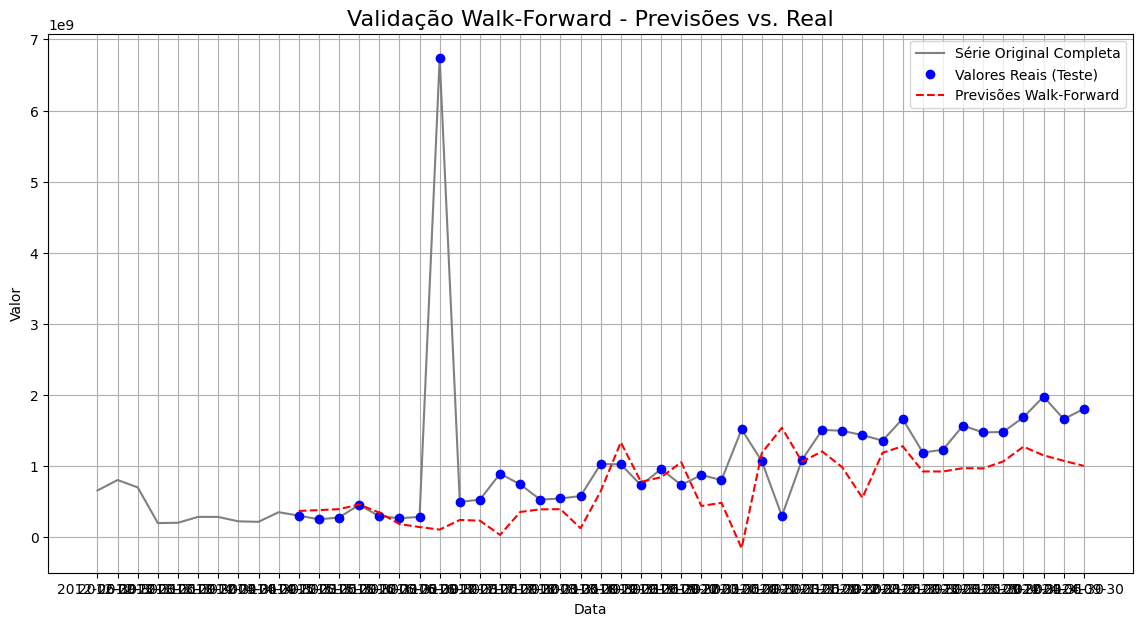


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 10, Tamanho do Teste: 5
--- Dobra 2/8 ---
Tamanho do Treino: 15, Tamanho do Teste: 5
--- Dobra 3/8 ---
Tamanho do Treino: 20, Tamanho do Teste: 5
--- Dobra 4/8 ---
Tamanho do Treino: 25, Tamanho do Teste: 5
--- Dobra 5/8 ---
Tamanho do Treino: 30, Tamanho do Teste: 5
--- Dobra 6/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 5
--- Dobra 7/8 ---
Tamanho do Treino: 40, Tamanho do Teste: 5
--- Dobra 8/8 ---
Tamanho do Treino: 45, Tamanho do Teste: 5
                               SARIMAX Results                                
Dep. Variable:                  20257   No. Observations:                   45
Model:                 ARIMA(1, 1, 4)   Log Likelihood                -884.175
Date:                Sun, 05 Oct 2025   AIC                           1800.350
Time:                        13:25:54   BIC                           1828.897
Sample:                    06-30-2012  

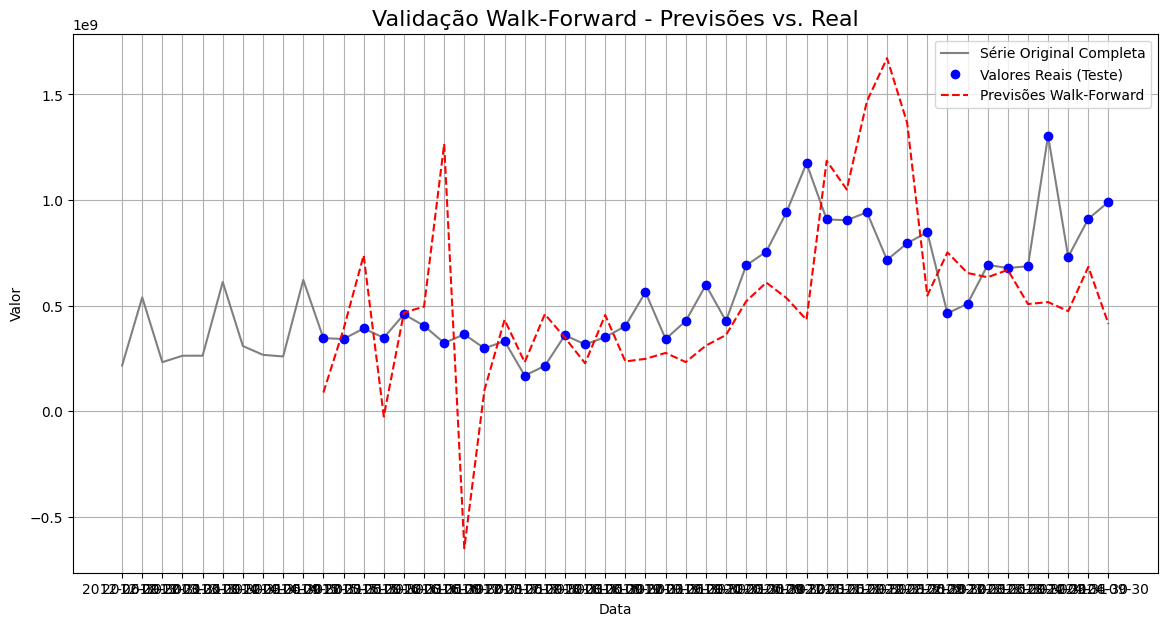


Empresa 21490 - Ordem ARIMA: [1, 1, 5]
Iniciando a validação Walk-Forward...
--- Dobra 1/8 ---
Tamanho do Treino: 10, Tamanho do Teste: 5
--- Dobra 2/8 ---
Tamanho do Treino: 15, Tamanho do Teste: 5
--- Dobra 3/8 ---
Tamanho do Treino: 20, Tamanho do Teste: 5
--- Dobra 4/8 ---
Tamanho do Treino: 25, Tamanho do Teste: 5
--- Dobra 5/8 ---
Tamanho do Treino: 30, Tamanho do Teste: 5
--- Dobra 6/8 ---
Tamanho do Treino: 35, Tamanho do Teste: 5
--- Dobra 7/8 ---
Tamanho do Treino: 40, Tamanho do Teste: 5
--- Dobra 8/8 ---
Tamanho do Treino: 45, Tamanho do Teste: 5
                               SARIMAX Results                                
Dep. Variable:                  21490   No. Observations:                   45
Model:                 ARIMA(1, 1, 5)   Log Likelihood                -865.146
Date:                Sun, 05 Oct 2025   AIC                           1812.292
Time:                        13:26:00   BIC                           1885.444
Sample:                    06-30-2012  

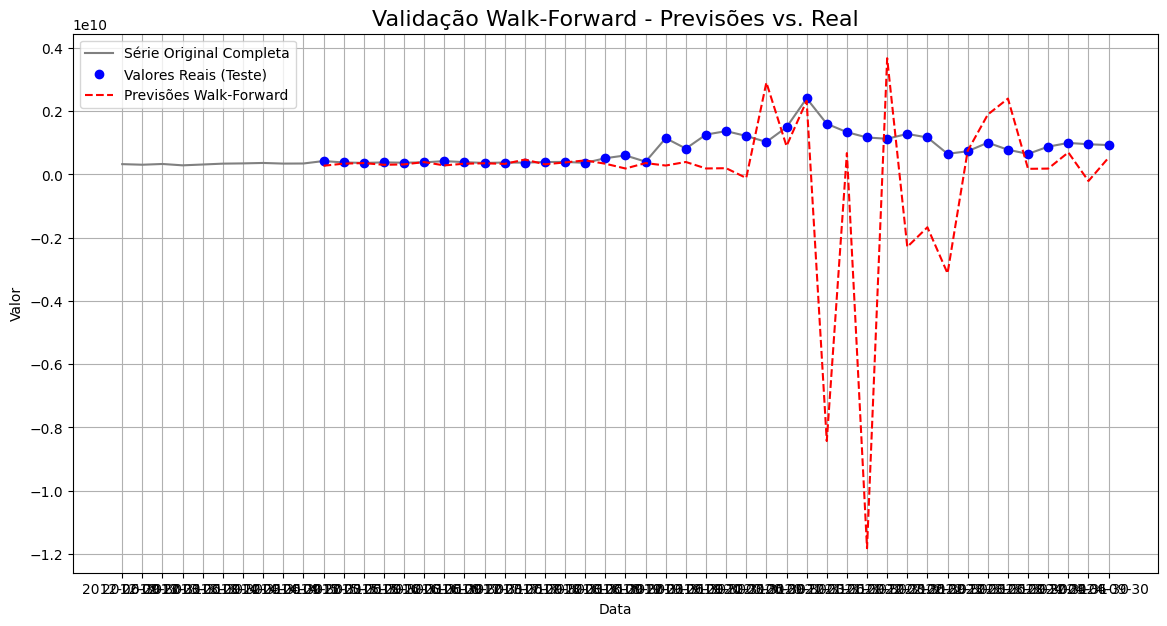

In [66]:
#aplica arimax
rmse_dict = {}
modelo_arimax = {}
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    rmse_dict[empresa], modelo_arimax[empresa] = walk_forward_arimax(resultado_bruto[empresa][9:], ordem_arima=resultado_bruto_comp_arima.loc[empresa].tolist(), n_splits=8, input_exog=input_receita[empresa])


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 38
--- Prevendo passo 10/38 (Treinando com 21 observações) ---
--- Prevendo passo 20/38 (Treinando com 31 observações) ---
--- Prevendo passo 30/38 (Treinando com 41 observações) ---
--- Prevendo passo 38/38 (Treinando com 49 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 21323612946.4725


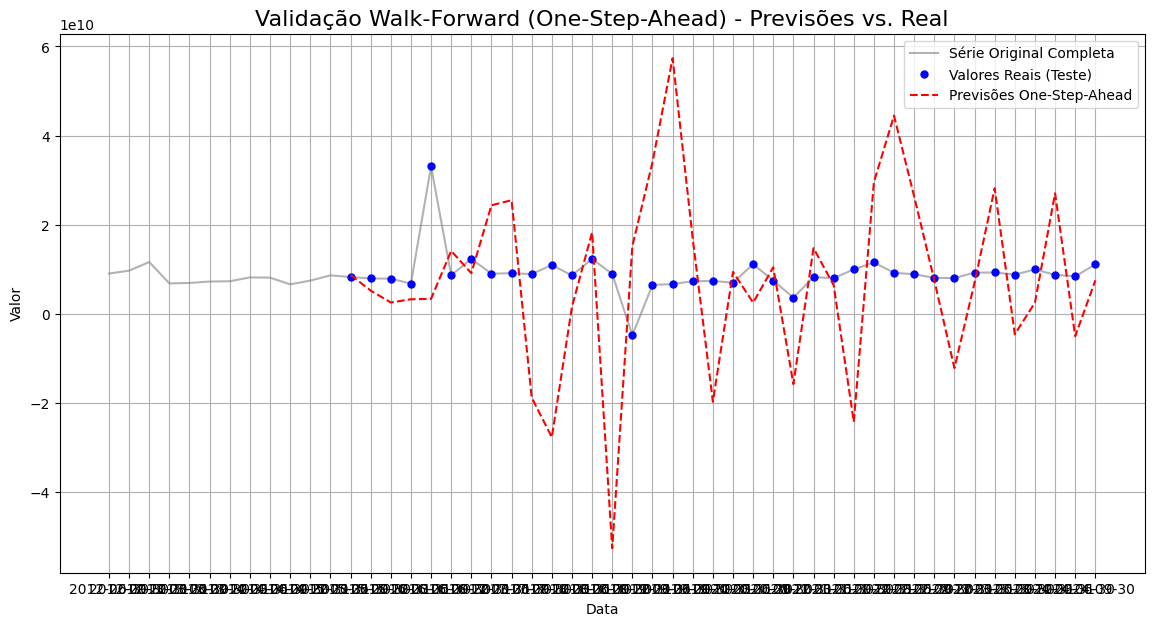


Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 38
--- Prevendo passo 10/38 (Treinando com 21 observações) ---
--- Prevendo passo 20/38 (Treinando com 31 observações) ---
--- Prevendo passo 30/38 (Treinando com 41 observações) ---
--- Prevendo passo 38/38 (Treinando com 49 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 1424536450.5321


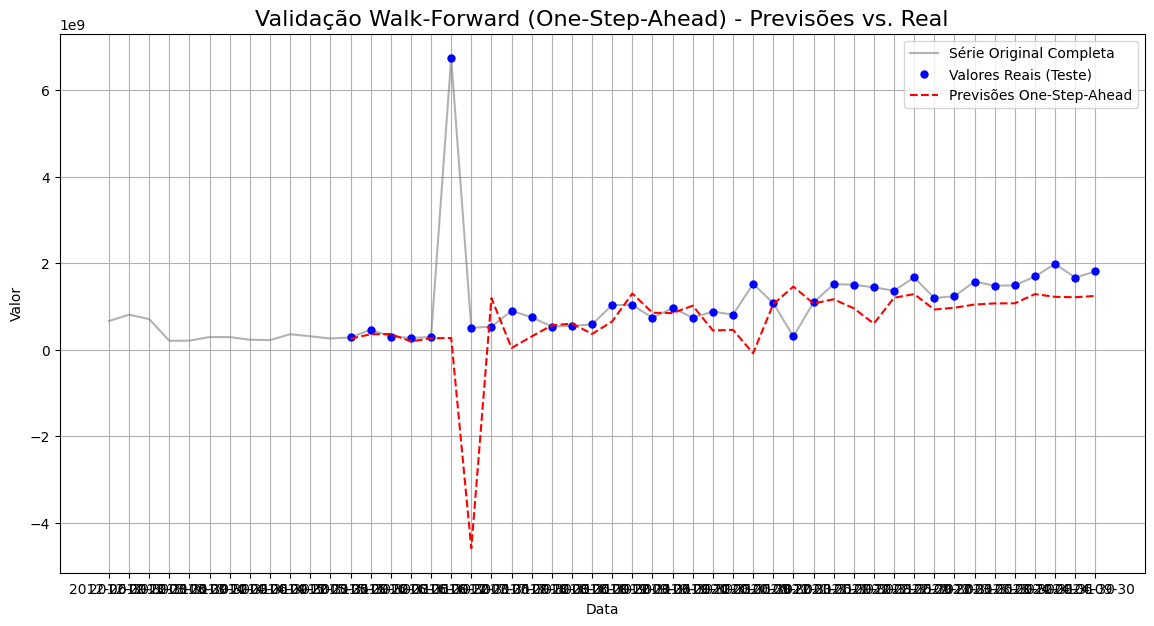


Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 38
--- Prevendo passo 10/38 (Treinando com 21 observações) ---
--- Prevendo passo 20/38 (Treinando com 31 observações) ---
--- Prevendo passo 30/38 (Treinando com 41 observações) ---
--- Prevendo passo 38/38 (Treinando com 49 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 281210034.9507


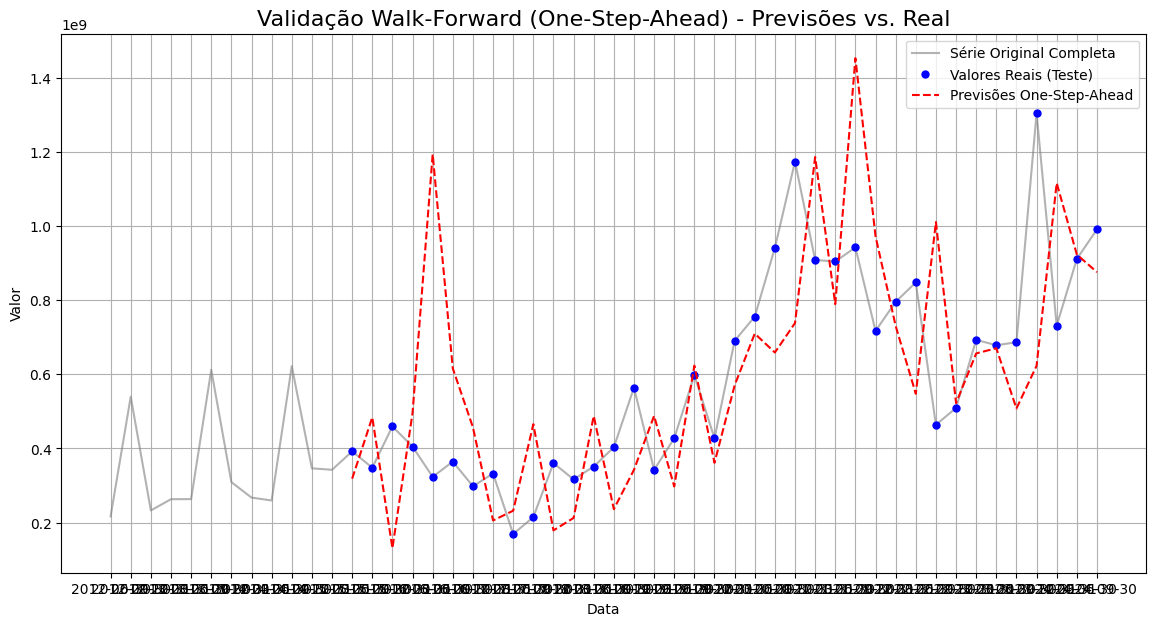


Empresa 21490 - Ordem ARIMA: [1, 1, 5]
Iniciando a validação Walk-Forward (One-Step-Ahead)...
Tamanho do treino inicial: 12, Número de previsões a fazer: 38
--- Prevendo passo 10/38 (Treinando com 21 observações) ---
--- Prevendo passo 20/38 (Treinando com 31 observações) ---
--- Prevendo passo 30/38 (Treinando com 41 observações) ---
--- Prevendo passo 38/38 (Treinando com 49 observações) ---

Validação Walk-Forward concluída.
RMSE Final (out-of-sample): 1848415235.2649


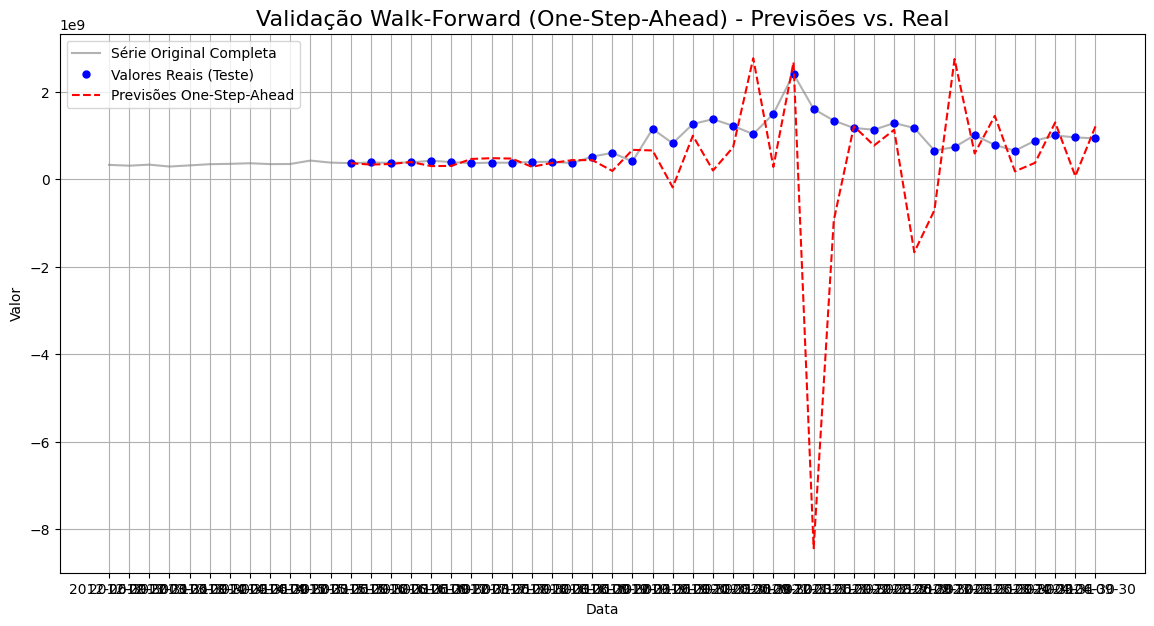

In [68]:
#aplica arimax one step
rmse_dict_one_step = {}
modelo_arimax_one_step = {}
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    rmse_dict_one_step[empresa], modelo_arimax_one_step[empresa] = walk_forward_arimax_one_step(resultado_bruto[empresa][9:], ordem_arima=resultado_bruto_comp_arima.loc[empresa].tolist(), tamanho_treino_inicial=12, input_exog=input_receita[empresa])

In [69]:
rmse_dict

{2437: 17590518090.90556,
 18376: 1165582069.4447086,
 20257: 397118007.0375822,
 21490: 2856806641.5167685}

In [70]:
rmse_dict_one_step

{2437: 21323612946.472504,
 18376: 1424536450.5320642,
 20257: 281210034.9507399,
 21490: 1848415235.264939}

Refina ARIMAX

In [71]:
# def refina_arimax(y_train, X_train, ordem_arima, alpha=0.05, max_iter=25, verbose=True):
#     """
#     Refina um modelo ARIMAX removendo iterativamente variáveis exógenas com p-value > alpha.
#     Parâmetros:
#       - y_train: Series com a endógena usada no treino.
#       - X_train: DataFrame com exógenas usadas no treino (colunas nomeadas).
#       - ordem_arima: tupla (p, d, q).
#       - alpha: limiar de significância (default 0.05).
#       - max_iter: no máx. de iterações de poda.
#       - verbose: imprime progresso.

#     Retorna:
#       - modelo_refinado: ARIMAResults após a poda.
#       - X_refinada: DataFrame com as colunas exógenas remanescentes (ou None).
#       - removidas_df: DataFrame com o log das variáveis removidas (variavel, pvalue, iter).
#     """
#     # Alinhar e limpar (dropna mantendo alinhamento)
#     if X_train is not None:
#         df = pd.concat([y_train.rename('y'), X_train], axis=1)
#         df = df.dropna()
#         if df.empty:
#             raise ValueError("Dados de treino ficaram vazios após dropna.")
#         y = df['y']
#         X = df.drop(columns=['y'])
#         if X.shape[1] == 0:
#             X = None
#     else:
#         y = y_train.dropna()
#         if y.empty:
#             raise ValueError("Série de treino vazia após dropna.")
#         X = None

#     order = tuple(int(v) for v in ordem_arima)
#     modelo = sm.tsa.ARIMA(y, order=order, exog=X)
#     res = modelo.fit()

#     removidas = []
#     it = 0

#     while it < max_iter and X is not None and X.shape[1] > 0:
#         it += 1
#         pvals = res.pvalues

#         # Nomes de exógenas presentes nos parâmetros do modelo
#         exog_names_in_model = [c for c in X.columns if c in pvals.index]
#         if len(exog_names_in_model) == 0:
#             if verbose:
#                 print("Nenhum parâmetro de exógena encontrado no modelo (nomenclatura não casou). Encerrando poda.")
#             break

#         exog_pvals = pvals[exog_names_in_model].astype(float)
#         worst_var = exog_pvals.idxmax()
#         worst_p = float(exog_pvals.loc[worst_var])

#         if np.isnan(worst_p) or worst_p > alpha:
#             if verbose:
#                 print(f"Iter {it}: removendo '{worst_var}' (p={worst_p:.4f})")
#             X = X.drop(columns=[worst_var])
#             removidas.append({'variavel': worst_var, 'pvalue': worst_p, 'iter': it})

#             X_fit = X if X.shape[1] > 0 else None
#             try:
#                 res = sm.tsa.ARIMA(y, order=order, exog=X_fit).fit()
#                 print(res.summary())
#             except Exception as e:
#                 if verbose:
#                     print(f"Falha ao refitar após remover {worst_var}: {e}. Restaurando última versão válida e encerrando.")
#                 # Recolocar a variável (rollback) e sair
#                 X = X.join(X_train[[worst_var]], how='left') if worst_var in X_train.columns else X
#                 break
#         else:
#             if verbose:
#                 print("Não há mais variáveis com p-value acima do limite.")
#             break

#     removidas_df = pd.DataFrame(removidas)
#     return res, (None if X is None or X.shape[1] == 0 else X), removidas_df
# # ...existing code...

In [72]:
def refina_arimax(y, X, ordem_arima, alpha=0.05, max_iter=50, verbose=True):
    """
    Refina ARIMAX removendo iterativamente termos insignificantes (p > alpha):
      - exógenas (colunas de X)
      - termos AR (reduz p se ar.Lp for insignificante)
      - termos MA (reduz q até remover o maior lag insignificante)
    Saídas: (res, X_final, log_df, y_fit)
    """
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm

    def _to_pdq(o):
        try:
            if all(k in o for k in ['AR(p)', 'I(d)', 'MA(q)']):
                return int(o['AR(p)']), int(o['I(d)']), int(o['MA(q)'])
        except Exception:
            pass
        if isinstance(o, (list, tuple)) and len(o) == 3:
            return int(o[0]), int(o[1]), int(o[2])
        raise ValueError("ordem_arima deve ser (p,d,q) ou possuir chaves 'AR(p)', 'I(d)', 'MA(q)'.")

    p, d, q = _to_pdq(ordem_arima)

    # Alinhamento e limpeza
    if X is not None:
        X = X.select_dtypes(include=[np.number])
        df = pd.concat([y.rename('y'), X], axis=1).dropna()
        if df.empty:
            raise ValueError("Dados vazios após alinhamento/dropna.")
        y_fit = df['y']
        X_fit = df.drop(columns=['y'])
        if X_fit.shape[1] == 0:
            X_fit = None
    else:
        y_fit = y.dropna()
        if y_fit.empty:
            raise ValueError("Série y vazia após dropna.")
        X_fit = None

    def _fit_cur(p, d, q, Xf):
        return sm.tsa.ARIMA(y_fit, order=(p, d, q), exog=(Xf if Xf is not None and Xf.shape[1] > 0 else None)).fit()

    res = _fit_cur(p, d, q, X_fit)

    log = []
    it = 0

    def _map_exog_param_to_cols(pvals_index, cols):
        mapping = {}
        if cols is None or len(cols) == 0:
            return mapping
        cols = list(cols)
        for name in pvals_index:
            if name in ('const', 'sigma2', 'intercept'):
                continue
            if name.startswith('ar.L') or name.startswith('ma.L'):
                continue
            if name in cols:
                mapping[name] = name
                continue
            if name.startswith('x') and name[1:].isdigit():
                idx = int(name[1:]) - 1
                if 0 <= idx < len(cols):
                    mapping[name] = cols[idx]
        return mapping

    while it < max_iter:
        it += 1
        pvals = res.pvalues

        # AR: somente maior lag atual
        ar_name = f'ar.L{p}' if p > 0 else None
        ar_pv = float(pvals.get(ar_name, np.nan)) if ar_name else np.nan

        # MA: avalia TODOS os lags atuais e pega o MAIOR lag insignificante
        ma_candidate = None
        if q > 0:
            ma_insig = []
            for k in range(1, q + 1):
                name = f'ma.L{int(k)}'
                if name in pvals.index:
                    pv = float(pvals.get(name, np.nan))
                    if np.isnan(pv) or pv > alpha:
                        ma_insig.append((k, pv))
            if ma_insig:
                # maior lag MA insignificante -> reduzir q até k-1
                k_star, pv_star = max(ma_insig, key=lambda t: t[0])
                ma_candidate = ('ma', f'ma.L{k_star}', pv_star, k_star - 1)

        # Exógenas: pior p-value entre as colunas presentes
        exog_candidate = None
        if X_fit is not None and X_fit.shape[1] > 0:
            mapping = _map_exog_param_to_cols(pvals.index, X_fit.columns)
            exog_p = []
            for p_name, col in mapping.items():
                pv = float(pvals.get(p_name, np.nan))
                if np.isnan(pv):
                    continue
                exog_p.append((col, pv))
            if exog_p:
                worst_col, worst_pv = max(exog_p, key=lambda t: t[1])
                if worst_pv > alpha or np.isnan(worst_pv):
                    exog_candidate = ('exog', worst_col, worst_pv, None)

        # Monta candidatos (tipo, item, pvalue, drop_to)
        candidates = []
        if p > 0 and (ar_pv > alpha or np.isnan(ar_pv)):
            candidates.append(('ar', ar_name, ar_pv, p - 1))
        if ma_candidate is not None:
            candidates.append(ma_candidate)
        if exog_candidate is not None:
            candidates.append(exog_candidate)

        if not candidates:
            if verbose:
                print("Não há termos com p-value acima do limite. Encerrando.")
            break

        # Escolha pelo maior p-value; em caso de empate: prioriza MA > AR > EXOG
        prio = {'ma': 0, 'ar': 1, 'exog': 2}
        action_type, action_item, action_pv, drop_to = max(
            candidates,
            key=lambda t: (np.nan_to_num(t[2], nan=1.0), -prio[t[0]])
        )
        if verbose:
            pv_str = "nan" if (action_pv is None or np.isnan(action_pv)) else f"{action_pv:.4f}"
            if action_type in ('ar', 'ma'):
                print(f"Iter {it}: removendo {action_type} '{action_item}' (p={pv_str}) -> novo {'p' if action_type=='ar' else 'q'} = {drop_to}")
            else:
                print(f"Iter {it}: removendo exógena '{action_item}' (p={pv_str})")

        # Aplica ação
        old_state = (p, q, None if X_fit is None else X_fit.copy())
        if action_type == 'exog':
            X_fit = X_fit.drop(columns=[action_item], errors='ignore')
            if X_fit.shape[1] == 0:
                X_fit = None
        elif action_type == 'ar':
            p = max(0, drop_to)
        elif action_type == 'ma':
            q = max(0, drop_to)

        # Refit
        try:
            res = _fit_cur(p, d, q, X_fit)
            log.append({
                'tipo': action_type, 'item': action_item,
                'pvalue': (np.nan if action_pv is None else float(action_pv)),
                'iter': it, 'p': p, 'd': d, 'q': q
            })
        except Exception as e:
            if verbose:
                print(f"Falha ao refitar após remover {action_type} '{action_item}': {e}. Revertendo e encerrando.")
            p, q, X_fit_restore = old_state
            X_fit = X_fit_restore
            break

    log_df = pd.DataFrame(log)
    X_final = None if (X_fit is None or (hasattr(X_fit, 'shape') and X_fit.shape[1] == 0)) else X_fit
    return res, X_final, log_df, y_fit
# ...existing code...

In [73]:
res = {}
X_final = {}
log_df = {}
y_fit = {}
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    res[empresa], X_final[empresa], log_df[empresa], y_fit[empresa] = refina_arimax(resultado_bruto[empresa][9:], input_receita[empresa], resultado_bruto_comp_arima.loc[empresa].tolist(), alpha=0.05, max_iter=25, verbose=True)


Empresa 2437 - Ordem ARIMA: [1, 1, 1]
Iter 1: removendo exógena 'Energia Com._lag6' (p=0.5674)
Não há termos com p-value acima do limite. Encerrando.

Empresa 18376 - Ordem ARIMA: [1, 1, 1]
Iter 1: removendo ar 'ar.L1' (p=0.7851) -> novo p = 0
Não há termos com p-value acima do limite. Encerrando.

Empresa 20257 - Ordem ARIMA: [1, 1, 4]
Iter 1: removendo ma 'ma.L4' (p=0.4354) -> novo q = 3
Iter 2: removendo exógena 'Energia Ind._lag6' (p=0.1859)
Iter 3: removendo ar 'ar.L1' (p=0.9643) -> novo p = 0
Iter 4: removendo ma 'ma.L3' (p=0.7431) -> novo q = 2
Iter 5: removendo exógena 'Vol. VA Serviços_lag6' (p=0.7219)
Iter 6: removendo exógena 'Vol. VA Indústria' (p=0.6440)
Iter 7: removendo ma 'ma.L2' (p=0.5631) -> novo q = 1
Não há termos com p-value acima do limite. Encerrando.

Empresa 21490 - Ordem ARIMA: [1, 1, 5]
Iter 1: removendo ar 'ar.L1' (p=0.8145) -> novo p = 0
Iter 2: removendo exógena 'Energia Res.' (p=0.3730)
Iter 3: removendo exógena 'IPAOG-DI_lag6' (p=0.4280)
Iter 4: removen

Diagnóstico do modelo

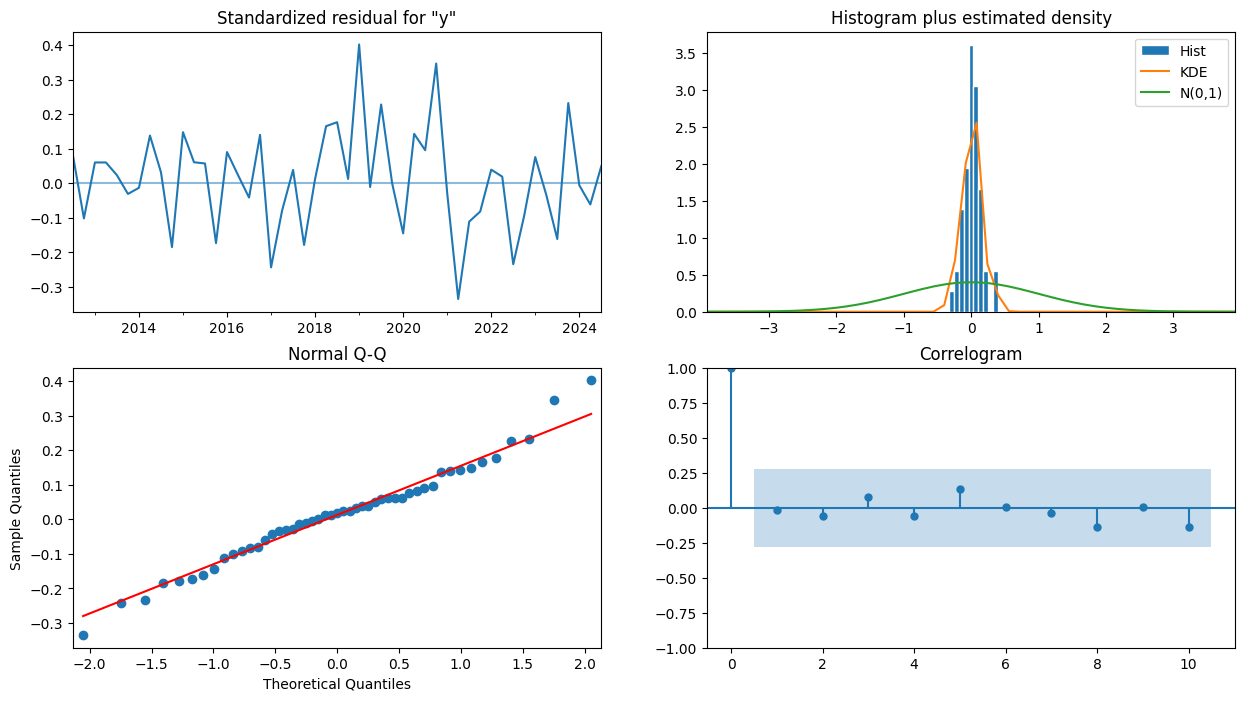

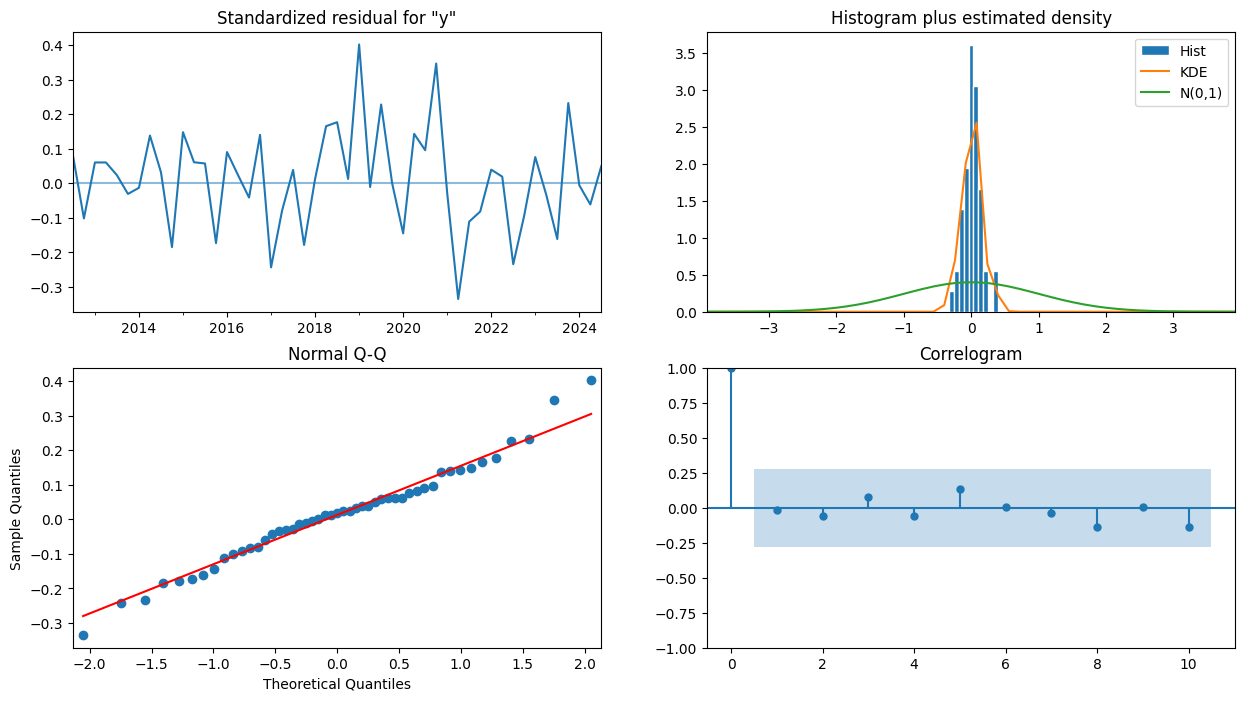

In [77]:
res[empresa].plot_diagnostics(figsize=(15, 8))

Refazendo o one-step com as ordens e variáveis exógenas refinadas

In [ ]:
rmse_dict_one_step = {}
modelo_arimax_one_step = {}
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMA: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    rmse_dict_one_step[empresa], modelo_arimax_one_step[empresa] = walk_forward_arimax_one_step(resultado_bruto[empresa][9:], ordem_arima=list(res[empresa].model.order), tamanho_treino_inicial=12, input_exog=X_final[empresa])

NARIMAX

In [ ]:
def cria_nao_linearidades(
    X,
    y=None,
    poly_degree=2,
    interactions=False,
    rolling_windows=None,
    drop_constants=True
):
    """
    Cria apenas não linearidades a partir de X (e, opcionalmente, estatísticas móveis de y).
    - X: DataFrame numérico com exógenas já prontas (incluindo lags, se houver).
    - y: Series alvo para calcular estatísticas móveis sem vazamento (usa y.shift(1)).
    - poly_degree: grau máximo de potência (>=2).
    - interactions: se True, cria interações par-a-par entre colunas de X.
    - rolling_windows: lista de janelas para médias e desvios móveis de y (ex.: [4,8]).
    - drop_constants: remove colunas constantes.
    Retorna: DataFrame com X original + não linearidades, alinhado ao índice comum.
    """
    import numpy as np
    import pandas as pd
    from itertools import combinations

    if X is None or X.empty:
        raise ValueError("X não pode ser vazio para criação de não linearidades.")

    X_num = X.select_dtypes(include=[np.number]).copy()
    idx = X_num.index
    if y is not None:
        y = pd.Series(y).copy()
        idx = idx.intersection(y.index)
        X_num = X_num.loc[idx]


    # Potências
    outs = [X_num]
    if poly_degree is not None and poly_degree >= 2:
        for d in range(2, int(poly_degree) + 1):
            pows = X_num.pow(d)
            pows.columns = [f"{c}__pow{d}" for c in X_num.columns]
            outs.append(pows)

    # Interações
    if interactions:
        inter_cols = {}
        cols = list(X_num.columns)
        for a, b in combinations(cols, 2):
            inter_cols[f"{a}__x__{b}"] = X_num[a] * X_num[b]
        if inter_cols:
            outs.append(pd.DataFrame(inter_cols, index=X_num.index))

    # Rolling de y (sem vazamento)
    if y is not None and rolling_windows:
        y_lagged = y.shift(1)
        roll_feats = {}
        for w in rolling_windows:
            rm = y_lagged.rolling(w, min_periods=w).mean()
            rs = y_lagged.rolling(w, min_periods=w).std()
            rm = rm.loc[idx]
            roll_feats[f"y_roll_mean_{w}"] = rm
            roll_feats[f"y_roll_std_{w}"] = rs
        outs.append(pd.DataFrame(roll_feats, index=y.index))

    feats = pd.concat([c for c in outs if c is not None and not c.empty], axis=1)

    # Limpeza
    feats = feats.dropna(axis=1, how='all')
    if drop_constants and not feats.empty:
        nun = feats.nunique(dropna=True)
        const_cols = nun[nun <= 1].index.tolist()
        if const_cols:
            feats = feats.drop(columns=const_cols, errors='ignore')

    return feats


In [ ]:
type(exog_filtradas[empresa]['3.01'].index)

In [ ]:
feats = {}
for empresa in exog_filtradas.keys():
    print(f"\nEmpresa {empresa}")
    feats[empresa] = cria_nao_linearidades(
        X=exog_filtradas[empresa]['3.01'],
        y=resultado_bruto[empresa],
        poly_degree=2,
        interactions=True,
        rolling_windows=[4, 8],
        drop_constants=True
    )
    print(f"Feats criadas: {feats[empresa].shape[1]}")
    display(feats[empresa].head())

In [ ]:
def walk_foward_narimax_one_step(
    serie,
    ordem_arima,
    tamanho_treino_inicial,
    X_prepared=None,
    scale_exog=True,
    verbose=True
):
    """
    Walk-forward one-step-ahead com NARIMAX usando X_prepared (não linearidades já criadas).
    Retorna: rmse_final, modelo_ajustado, df_resultados
    """
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import mean_squared_error

    # Alinhar y e X (e remover linhas com NaN)
    y = pd.Series(serie).copy()
    y.name = y.name or 'y'
    if X_prepared is not None and not X_prepared.empty:
        df_all = pd.concat([y.rename('y'), X_prepared], axis=1).dropna(axis=0, how='any')
        if df_all.empty:
            raise ValueError("Sem dados após alinhamento/dropna. Verifique X_prepared/serie.")
        y_aligned = df_all['y']
        X_aligned = df_all.drop(columns=['y'])
    else:
        y_aligned = y.dropna()
        X_aligned = None

    n = len(y_aligned)
    if tamanho_treino_inicial < 10:
        tamanho_treino_inicial = max(10, tamanho_treino_inicial)
    if tamanho_treino_inicial >= n:
        raise ValueError("tamanho_treino_inicial deve ser menor que o número de amostras válidas.")

    valores_reais, previsoes = [], []
    modelo_ajustado = None
    p, d, q = (int(ordem_arima[0]), int(ordem_arima[1]), int(ordem_arima[2]))

    if verbose:
        n_preds = n - tamanho_treino_inicial
        n_feats = 0 if (X_aligned is None) else X_aligned.shape[1]
        print(f"Iniciando Walk-Forward NARIMAX: {n_preds} previsões.")
        print(f"Ordem ARIMA: {(p, d, q)}, Features: {n_feats}")

    for i in range(tamanho_treino_inicial, n):
        treino_y = y_aligned.iloc[:i]
        valor_real = y_aligned.iloc[i]

        if X_aligned is not None and not X_aligned.empty:
            treino_X = X_aligned.iloc[:i]
            teste_X = X_aligned.iloc[i:i+1]
            if scale_exog and treino_X.shape[1] > 0:
                scaler = StandardScaler().fit(treino_X.values)
                X_train_fit = pd.DataFrame(scaler.transform(treino_X.values), index=treino_X.index, columns=treino_X.columns)
                X_test_fit = pd.DataFrame(scaler.transform(teste_X.values), index=teste_X.index, columns=teste_X.columns)
            else:
                X_train_fit, X_test_fit = treino_X, teste_X
        else:
            X_train_fit = None
            X_test_fit = None

        try:
            modelo_ajustado = sm.tsa.ARIMA(treino_y, order=(p, d, q), exog=X_train_fit).fit()
        except Exception:
            modelo_ajustado = sm.tsa.SARIMAX(
                treino_y, order=(p, d, q), exog=X_train_fit,
                enforce_stationarity=False, enforce_invertibility=False
            ).fit(disp=False)

        prev = modelo_ajustado.forecast(steps=1, exog=X_test_fit)
        previsoes.append(prev.iloc[0])
        valores_reais.append(valor_real)

        if verbose and ((i - tamanho_treino_inicial + 1) % 10 == 0 or i == n - 1):
            print(f"Passo {i - tamanho_treino_inicial + 1}/{n - tamanho_treino_inicial}: treino={len(treino_y)}")

    rmse_final = float(np.sqrt(mean_squared_error(valores_reais, previsoes)))
    df_resultados = pd.DataFrame({'Real': valores_reais, 'Previsao': previsoes}, index=y_aligned.index[-len(valores_reais):])

    if verbose:
        print(f"RMSE Final (one-step): {rmse_final:.4f}")

    # Plot opcional
    try:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(14, 7))
        plt.plot(y_aligned, label='Série (alinhada)', color='gray', alpha=0.6)
        plt.plot(df_resultados['Real'], label='Real (Teste)', color='blue', marker='o', linestyle='None', markersize=5)
        plt.plot(df_resultados['Previsao'], label='Previsão (NARIMAX)', color='red', linestyle='--')
        plt.title('Walk-Forward (One-Step) - NARIMAX'); plt.xlabel('Data'); plt.ylabel('Valor')
        plt.legend(); plt.grid(True); plt.show()
    except Exception:
        pass

    return rmse_final, modelo_ajustado, df_resultados

In [60]:
resultado_bruto.to_csv(f"{path_dados_tratados}resultado_bruto.csv")
lucro_consolidado.to_csv(f"{path_dados_tratados}lucro_consolidado.csv")
despesas_operacionais.to_csv(f"{path_dados_tratados}despesas_operacionais.csv")


In [ ]:
for empresa in input_receita.keys():
    input_receita[empresa].to_csv(f"{path_dados_tratados}input_receita_{empresa}.csv")

In [ ]:
res = {}
X_final = {}
log_df = {}
y_fit = {}
for empresa in resultado_bruto.keys():
    print(f"\nEmpresa {empresa} - Ordem ARIMAX: {resultado_bruto_comp_arima.loc[empresa].tolist()}")
    res[empresa], modelo_ajustado, y_fit[empresa] = walk_foward_narimax_one_step(resultado_bruto[empresa][9:], input_receita[empresa], resultado_bruto_comp_arima.loc[empresa].tolist(), alpha=0.05, max_iter=25, verbose=True)